In [ ]:
import networkx as nx
import random

def barabasi_albert_graph(n, m, seed=None):
    """
    Manually builds a Barabási–Albert (BA) graph using preferential attachment.

    Parameters:
        n (int): Total number of nodes in the final graph.
        m (int): Number of edges each new node attaches to when added.
        seed (int, optional): Random seed for reproducibility.

    Returns:
        G (nx.Graph): The generated BA graph.
    """
    if seed is not None:
        random.seed(seed)

    if m < 1 or m >= n:
        raise ValueError("m must satisfy 1 <= m < n")

    # Initialize with a small fully connected (complete) graph of m nodes
    G = nx.Graph()
    G.add_nodes_from(range(m))
    for i in range(m):
        for j in range(i + 1, m):
            G.add_edge(i, j)

    # A list of nodes where each node appears as many times as its degree.
    # This is used for preferential attachment sampling.
    node_list = list(G.nodes()) * (m - 1)
    for new_node in range(m, n):
        # Select m distinct existing nodes with probability proportional to degree
        targets = set()
        while len(targets) < m:
            chosen = random.choice(node_list)
            targets.add(chosen)

        # Add the new node and edges to selected targets
        G.add_node(new_node)
        for t in targets:
            G.add_edge(new_node, t)

        # Update node_list for degree weighting
        node_list.extend(targets)
        node_list.extend([new_node] * m)

    return G

import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend, weighted=False):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    # G.add_nodes_from(list(range(backend.num_qubits)))
    if weighted:
        # props = backend.properties()
        # # Extract two-qubit gate errors
        # for gate in props.gates:
        #     if gate.gate in ['cz', 'cx', 'ecr']:
        #         q1, q2 = gate.qubits
        #         err = next(param.value for param in gate.parameters if param.name == "gate_error")
        #         if err<1.0:
        #             G.add_edge(q1, q2, weight=1-err)

        props = backend.properties()
        conf = backend.configuration()
        coupling = conf.coupling_map

        alpha=0.75
        beta_readout=0.7
        beta_t12=0.2
        beta_gate=0.1

        G = nx.Graph()
        # G.add_nodes_from(range(conf.num_qubits))

        # ---- Node (1Q) noise ----
        node_noise = {}
        for q in range(conf.num_qubits):
            qb = props.qubits[q]
            for p in qb:
                if p.name=='T1':
                    if p.value>0:
                        t1 = p.value
                    else:
                        t1 = 100e6
                if p.name=='T2':
                    if p.value>0:
                        t2 = p.value
                    else:
                        t2 = 100e6
                if p.name=='readout_error':
                    readout_err = p.value
            decoh = (1 / t1 + 1 / t2) if t1 > 0 and t2 > 0 else 0
            gate_errs = [
                param.value
                for g in props.gates
                if len(g.qubits) == 1 and g.qubits[0] == q
                for param in g.parameters
                if param.name == "gate_error"
            ]
            # print(gate_errs)
            max_gate_err = np.mean(gate_errs) if gate_errs else 0
            node_noise[q] = (
                beta_readout * readout_err
                + beta_t12 * decoh
                + beta_gate * max_gate_err
            )
            # print(q, node_noise[q])
            G.add_node(q, weight=max(1 - node_noise[q], 0))
            # print(q, decoh, max_gate_err, readout_err, 1-node_noise[q])

        # ---- Edge (2Q) noise ----
        for g in props.gates:
            if len(g.qubits) == 2:
                q1, q2 = g.qubits
                err = next(param.value for param in g.parameters if param.name == "gate_error")
                node_term = (node_noise[q1] + node_noise[q2]) / 2
                # print(node_term)
                combined_noise = alpha * err + (1 - alpha) * node_term
                reliability = 1 - combined_noise
                # if reliability>0.9:
                G.add_edge(q1, q2, weight=max(reliability, 0))
    else:
        G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    
import matplotlib.pyplot as plt
def gradient_graph(graph : nx.Graph, normalized=False, tree=None, title=None, flip_sign=False):
    if not tree:
        tree = graph
    G = nx.Graph()
    G.add_nodes_from(sorted(graph.nodes()))
    G.add_edges_from(graph.edges())
    graph=G
    fiedler = graph_laplacian_embedding(tree, k=1, normalized=normalized).flatten()
    # sorted_nodes = np.argsort(fiedler)

    fiedler_dict = {}
    fiedler_dict = {list(graph.nodes)[i] : (1+2*flip_sign*(-1))*fiedler[i] for i in range(graph.number_of_nodes())}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()


def selective_bfs(G, source, n, weight='weight', threshold=0.9, relax_factor=0.5, min_threshold=0.0):
    if source not in G:
        raise ValueError(f"Source node {source} not in graph")

    visited = set([source])
    q = deque([source])
    sub_nodes = [source]
    current_threshold = threshold

    while len(sub_nodes) < n:
        progress = False
        temp_q = deque(q)

        while temp_q and len(sub_nodes) < n:
            u = temp_q.popleft()
            for v in G.neighbors(u):
                if v not in visited:
                    w = G[u][v].get(weight, 1.0)
                    if w >= current_threshold:
                        visited.add(v)
                        q.append(v)
                        sub_nodes.append(v)
                        progress = True
                        if len(sub_nodes) >= n:
                            break

        # If no new nodes were added, relax the threshold
        if not progress:
            current_threshold *= relax_factor
            if current_threshold < min_threshold:
                # As a last resort, include any remaining nodes
                remaining = [v for v in G.nodes if v not in visited]
                sub_nodes.extend(remaining[: n - len(sub_nodes)])
                break

    return G.subgraph(sub_nodes).copy()

def extract_low_noise_subgraph(
    backend,
    n_target,
    beta_readout=0.75,
    beta_t12=0.2,
    beta_gate=0.1,
    start_percentile=0.90,
    relax_step=0.05,
    min_percentile=0.01,
):
    """
    Extract a low-noise connected subgraph using statistical filtering.
    
    Nodes/edges are selected by percentile thresholds rather than fixed values.
    """

    props = backend.properties()
    conf = backend.configuration()

    G = nx.Graph()

    # ---- Compute node reliability ----
    for q in range(conf.num_qubits):
        qb = props.qubits[q]
        readout_err = qb[2].value
        t1 = qb[0].value if qb[0].value > 0 else np.inf
        t2 = qb[1].value if qb[1].value > 0 else np.inf
        decoherence_term = (1.0 / t1 + 1.0 / t2)

        gate_errs = [
            param.value
            for g in props.gates if len(g.qubits) == 1 and g.qubits[0] == q
            for param in g.parameters if param.name == "gate_error"
        ]
        avg_gate_err = np.mean(gate_errs) if gate_errs else 0.0

        node_noise = (
            beta_readout * readout_err +
            beta_t12 * decoherence_term +
            beta_gate * avg_gate_err
        )
        # print(readout_err, decoherence_term, avg_gate_err)

        reliability = max(1 - node_noise, 0)
        G.add_node(q, reliability=reliability)

    # ---- Compute edge reliability ----
    for g in props.gates:
        if len(g.qubits) == 2:
            q1, q2 = g.qubits
            err_2q = next(param.value for param in g.parameters if param.name == "gate_error")
            reliability = max(1 - err_2q, 0)
            G.add_edge(q1, q2, reliability=reliability)

    # ---- Iterative percentile relaxation ----
    percentile = start_percentile

    # Compute statistical thresholds
    node_vals = np.array([d["reliability"] for _, d in G.nodes(data=True)])
    edge_vals = np.array([d["reliability"] for _, _, d in G.edges(data=True)])
    while percentile >= min_percentile:
        node_thresh = np.quantile(node_vals, percentile)
        edge_thresh = np.quantile(edge_vals, percentile)
        # print(percentile, len([x for x in edge_vals if x>edge_thresh])/len(edge_vals))

        # Filter nodes
        good_nodes = [q for q in G.nodes if G.nodes[q]["reliability"] >= node_thresh]
        G1 = G.subgraph(good_nodes).copy()

        # Filter edges
        good_edges = [(u, v) for u, v in G1.edges
                      if G1[u][v]["reliability"] >= edge_thresh]

        G2 = nx.Graph()
        G2.add_nodes_from(G1.nodes(data=True))
        G2.add_edges_from([(u, v, G1[u][v]) for u, v in good_edges])
        # draw_graph_custom(G2)

        # Connected components
        components = sorted(nx.connected_components(G2), key=len, reverse=True)
        for comp in components:
            # print(len(comp), comp)
            if len(comp) >= n_target:
                # print(f"Selected percentile: {percentile:.2f}")
                return G2.subgraph(comp).copy()

        # Relax if no valid component
        percentile -= relax_step

    return None

def central_node(G):
    # Compute eccentricity of each node
    ecc = nx.eccentricity(G)
    
    # Find center nodes (min eccentricity)
    min_ecc = min(ecc.values())
    center_nodes = [n for n, e in ecc.items() if e == min_ecc]
    
    # If multiple centers exist, break ties using closeness centrality
    if len(center_nodes) > 1:
        closeness = nx.closeness_centrality(G)
        center_nodes.sort(key=lambda n: closeness[n], reverse=True)
    
    return center_nodes[0]  # Best root

def initial_layout(graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None, noise_aware=False, na_method='selective_bfs'):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            if noise_aware:
                if na_method=='selective_bfs':
                    G = get_coupling_graph(backend, weighted=True)
                else:
                    G = extract_low_noise_subgraph(backend, n_target=num_nodes)
            else:
                G = get_coupling_graph(backend)
            if not root_on_backend:
                root_on_backend = central_node(G)
            
            if noise_aware and na_method=='selective_bfs':
                tree_layout = selective_bfs(G, source=root_on_backend, n=num_nodes)
            else:
                tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)

            order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math

    graph = nx.Graph()
    graph.add_nodes_from(G.nodes())
    graph.add_edges_from(G.edges())
    G=graph

    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np

def optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=None):
    """
    Find optimal mapping between logical and physical qubits
    using Hungarian algorithm on Euclidean distances.

    Args:
        logical_embedding: np.ndarray, shape (n, k)
        physical_embedding: np.ndarray, shape (n, k)

    Returns:
        mapping: dict {logical_index: physical_index}
    """
    if not nodes:
        nodes = list(range(physical_embedding.shape[0]))
    # cost matrix: pairwise distances between embeddings
    cost_matrix = cdist(logical_embedding, physical_embedding, metric='sqeuclidean')

    # Hungarian (linear sum assignment)
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Construct mapping
    mapping = {int(r): int(nodes[c]) for r, c in zip(row_ind, col_ind)}
    return mapping


def normalized_graph(graph:nx.Graph):
    for u,v in list(graph.edges):
        graph[u][v]['weight'] = 1.0/np.sqrt(graph.degree(u)*graph.degree(v))
    return graph

def return_ops(backend, graph_type='reg', param=4, average_over=5, node_list=list(range(10,101,2)), reps=2, tech='1D', k=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False, normalize_laplacian=False, noise_aware=False, na_method='selective_bfs'):
    swaps = {'means': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]},
             'stddevs': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':[], 'fied':[], 'triv':[], 'rand':[]}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)
        gen = gen_QAOA_circuit(graph, reps=reps)
        spec_graph=graph
        if tech=='1D':
            tree = dfs_spanning_tree(graph, root=0)
            
            proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology, noise_aware=noise_aware, na_method=na_method)
        elif tech=='2D':
            logical_embedding = graph_laplacian_embedding(spec_graph, k=k, normalized=normalize_laplacian)
            logical_embedding = logical_embedding[:, :k]

            if noise_aware:
                if na_method=='selective_bfs':
                    G = get_coupling_graph(backend, weighted=True)
                else:
                    G = extract_low_noise_subgraph(backend, n_target=n)
            else:
                G = get_coupling_graph(backend)
            root_on_backend = sorted(list(G.nodes))[len(G)//2]
            
            if noise_aware and na_method=='selective_bfs':
                S = selective_bfs(G, source=root_on_backend, n=n)
            else:
                S = build_tree_cluster(G, source=root_on_backend, n=n)
            physical_embedding = graph_laplacian_embedding(S, k=k)

            # if k>2:
            #     num_extra_cols = k - 2
            #     physical_embedding = np.hstack([physical_embedding, np.zeros((physical_embedding.shape[0], num_extra_cols))])

            proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        # swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        # swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(graph, backend=backend, how='random')
        # swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            swap_avg['fied'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=proposed_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['triv'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['sabre'].append(func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0))
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['means']['SABRE'].append(np.mean(swap_avg['sabre']))
        swaps['stddevs']['SABRE'].append(np.std(swap_avg['sabre']))

        swaps['means']['Proposed'].append(np.mean(swap_avg['fied']))
        swaps['stddevs']['Proposed'].append(np.std(swap_avg['fied']))

        swaps['means']['Trivial'].append(np.mean(swap_avg['triv']))
        swaps['stddevs']['Trivial'].append(np.std(swap_avg['triv']))

    return swaps

import warnings
warnings.filterwarnings("ignore")

def return_ops_all_methods(
    backend,
    graph_type='reg',
    param=4,
    average_over=5,
    node_list=list(range(10,101,2)),
    k_list=[2,3,5],
    reps=2,
    topology='tree_dfs',
    opt_level=3,
    op_name='ecr',
    use_custom=True,
    stop_after_routing=False,
    normalize_laplacian=True,
    noise_aware=False,
    na_method='selective_bfs'
):
    methods = ["SABRE", "Trivial", "Fiedler"]
    for k in k_list:
        methods.append(f"Assign{k}")
    
    swaps = {
        'means': {m: [] for m in methods},
        'stddevs': {m: [] for m in methods}
    }

    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {m.lower(): [] for m in methods}

        # Generate problem graph
        if graph_type == 'reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)

        # Create QAOA circuit (unmapped)
        gen = gen_QAOA_circuit(graph, reps=reps)

        # Trivial and Random Mappings
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        
        # SABRE handled separately
        sabre_mapping = None  # Automatic by SABRE transpiler

        # ====================
        # Mapping Strategy 1: Fiedler Ordered Mapping
        # ====================
        tree = dfs_spanning_tree(graph, root=0)
        fiedler_mapping = initial_layout(tree, backend=backend, how='fiedler',
                                         topology=topology, noise_aware=noise_aware,
                                         na_method=na_method)

        # ====================
        # Mapping Strategies 2–4: Spectral Assignment Mapping (k = 2,3,5)
        # ====================
        logical_embeddings = {
            k: graph_laplacian_embedding(graph, k=k, normalized=normalize_laplacian)[:, :k]
            for k in k_list
        }

        # Hardware subgraph (noise-aware or standard)
        if noise_aware:
            if na_method == 'selective_bfs':
                G = get_coupling_graph(backend, weighted=True)
            else:
                G = extract_low_noise_subgraph(backend, n_target=n)
        else:
            G = get_coupling_graph(backend)

        root = sorted(G.nodes)[len(G)//2]

        if noise_aware and na_method == 'selective_bfs':
            S = selective_bfs(G, source=root, n=n)
        else:
            S = build_tree_cluster(G, source=root, n=n)

        physical_embeddings = {
            k: graph_laplacian_embedding(S, k=k) for k in k_list
        }
        
        assign_mappings = {
            f"assign{k}": optimal_qubit_assignment(logical_embeddings[k],
                                                  physical_embeddings[k],
                                                  nodes=sorted(S.nodes()))
            for k in k_list
        }

        # ===========================
        # Circuit Execution & Counting
        # ===========================
        if stop_after_routing:
            exec_map_func = custom_routed_circuit
            exec_sabre_func = sabre_routed_circuit
        else:
            exec_map_func = final_optimized_circuit
            exec_sabre_func = final_optimized_circuit

        for i in range(average_over):
            # Fiedler
            swap_avg['fiedler'].append(
                exec_map_func(custom_qaoa_ansatz(graph, fiedler_mapping, backend.coupling_map, reps=reps) if use_custom else gen, 
                              backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0)
            )
        
            # Assign2 / Assign4 / Assign5
            for k in k_list:
                key = f"assign{k}".lower()
                swap_avg[key].append(
                    exec_map_func(circuit=custom_qaoa_ansatz(graph, assign_mappings[f"assign{k}"], backend.coupling_map, reps=reps) if use_custom else gen, 
                                  backend=backend, initial_mapping=assign_mappings[f"assign{k}"], opt_level=opt_level).count_ops().get(op_name, 0)
                )

            # Trivial
            swap_avg['trivial'].append(
                exec_map_func(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0)
            )

            # SABRE
            swap_avg['sabre'].append(
                exec_sabre_func(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0)
            )

        # ===========================
        # Statistical Results
        # ===========================
        for m in methods:
            key = m.lower()
            swaps['means'][m].append(np.mean(swap_avg[key]))
            swaps['stddevs'][m].append(np.std(swap_avg[key]))

    return swaps

import matplotlib.pyplot as plt
import numpy as np

# Methods returned by return_ops_all_methods()

# Colors for consistency across plots
colors = {
    "SABRE":   "#E69F00",
    "Trivial": "#56B4E9",
    "Fiedler": "#009E74",
    "Assign2": "#0072B2",
    "Assign4": "#D55E00",
    'Assign4': "#F0E442",
    "Assign5": "#CC79A7"
}

def plot_swap_results(swaps_dict, node_list, k_list, params, zoom=None, title_prefix=""):
    """
    swaps_dict: swap statistics returned from return_ops_all_methods()
    node_list: list of graph sizes tested (x-axis)
    params: list of values used for graph param (ex: degrees or m attachments)
    """
    methods = ["SABRE", "Trivial", "Fiedler"]
    for k in k_list:
        methods.append(f"Assign{k}")
    if zoom:
        node_list=node_list[:zoom]
    for param in params:
        plt.figure(figsize=(9, 6))
        
        for method in methods:
            means=swaps_dict[param]['means'][method]
            stds=swaps_dict[param]['stddevs'][method]
            if zoom:
                means=means[:zoom]
                stds=stds[:zoom]
            mean_vals = np.array(means)
            std_vals  = np.array(stds)
            
            plt.plot(node_list, mean_vals,
                     label=method,
                     color=colors.get(method, None),
                     linewidth=2)

            plt.fill_between(node_list,
                             mean_vals - std_vals,
                             mean_vals + std_vals,
                             alpha=0.25,
                             color=colors.get(method, None))

        plt.xlabel("Number of Nodes", fontsize=18)
        plt.ylabel("SWAP Count", fontsize=18)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)

        if title_prefix:
            plt.title(f"{title_prefix} (param = {param})", fontsize=18)

        plt.grid(alpha=0.4)
        plt.legend(fontsize=14)
        plt.tight_layout()
        plt.show()


def QAOA_max_cut(candidate_circuit:QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, estimator_shots=1000, sampler_shots=1000):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = estimator_shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
    optimized_circuit = candidate_circuit.assign_parameters(result.x)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = sampler_shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    counts_int = job.result()[0].data.meas.get_int_counts()
    counts_bin = job.result()[0].data.meas.get_counts()
    shots = sum(counts_bin.values())
    final_distribution_int = {key: val/shots for key, val in counts_int.items()}
    final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}

    return final_distribution_bin
    # keys = list(final_distribution_bin.keys())
    # values = list(final_distribution_bin.values())
    # most_likely = keys[np.argmax(np.abs(values))]

    # return most_likely[::-1]

def optimized_parameters(candidate_circuit: QuantumCircuit, cost_hamiltonian:SparsePauliOp, backend, reps=2, shots=100):
    initial_gamma = np.pi
    initial_beta = np.pi/2
    init_params = [initial_gamma, initial_beta] * reps

    objective_func_vals = [] # Global variable

    def cost_func_estimator(params, ansatz, hamiltonian, estimator):
        isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

        pub = (ansatz, isa_hamiltonian, params)
        job = estimator.run([pub])

        results = job.result()[0]
        cost = results.data.evs

        objective_func_vals.append(cost)

        return cost

    with Session(backend=backend) as session:
        estimator = Estimator(mode=session)
        estimator.options.default_shots = shots

        estimator.options.dynamical_decoupling.enable = True
        estimator.options.dynamical_decoupling.sequence_type = "XY4"
        estimator.options.twirling.enable_gates = True
        estimator.options.twirling.num_randomizations = "auto"

        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, cost_hamiltonian, estimator),
            method="COBYLA",
            tol=1e-2,
        )
        return result.x
    
def sample_distribution(candidate_circuit:QuantumCircuit, optimized_params, backend, shots=1000):
    optimized_circuit = candidate_circuit.assign_parameters(optimized_params)

    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots

    # Set simple error suppression/mitigation options
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    pub= (optimized_circuit, )
    job = sampler.run([pub], shots=int(1e4))
    return job.job_id()

def dist_from_job_id(job_id, backend):
    job = backend.retrieve_job(job_id)
    result = job.result()
    counts = result[0].data.meas.get_counts()
    total = sum(counts.values())
    return {k: v / total for k, v in counts.items()}

def evaluate_cut(graph: nx.Graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v in list(graph.edges()):
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += 1
    return cut_value

def maxcut_dict(graph, cut_dict):
    mc_dict = defaultdict(int)
    for bitstr, prob in cut_dict.items():
        mc_dict[evaluate_cut(graph, bitstr[::-1])] += prob
    return mc_dict


In [34]:
def maxcut_dist(sim, backend, num_nodes, graph_type='reg', param=4, reps=1, opt_level=3, estimator_shots=1000, sampler_shots=1000, root_on_backend=None, normalize_laplacian=True, tech='1D', k=2, noise_aware=False, default=False, gate='cz'):
    if graph_type=='reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = nx.barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    hamiltonian = get_hamiltonian(graph)

    if default:
        opt_gen = final_optimized_circuit(gen_QAOA_circuit(graph, reps=reps), backend, initial_mapping=None, opt_level=opt_level)
        print('Default=> ', gate,': ', opt_gen.count_ops().get(gate, 0), 'Depth: ',opt_gen.depth())
        return QAOA_max_cut(opt_gen, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)
    else:
        if tech=='1D':
                tree = dfs_spanning_tree(graph, root=0)
                proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', noise_aware=noise_aware)
        elif tech=='2D':
                logical_embedding = graph_laplacian_embedding(graph, k=k, normalized=normalize_laplacian)

                if noise_aware:
                    H = get_coupling_graph(backend, weighted=True)
                    S = selective_bfs(H, source=H.number_of_nodes()//2, n=num_nodes)
                else:
                    H = get_coupling_graph(backend)
                    S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=num_nodes)
                physical_embedding = graph_laplacian_embedding(S, k=k)
                proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))

        # Distribution with Proposed Initial Mapping
        prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        opt_prop = final_optimized_circuit(prop, backend, proposed_mapping, opt_level=opt_level)

        print('Prop=> ', gate,': ', opt_prop.count_ops().get(gate, 0), 'Depth: ',opt_prop.depth())
        
        return QAOA_max_cut(opt_prop, hamiltonian, backend=sim, reps=reps, estimator_shots=estimator_shots, sampler_shots=sampler_shots)  
    # mc_dist_prop = maxcut_dict(graph, prop_dist)
    # mc_dist_gen = maxcut_dict(graph, gen_dist)

    # return mc_dist_prop, mc_dist_gen, maxcut_dist_over_all_possible(graph)

def most_likely_cut(dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    most_likely = keys[np.argmax(np.abs(values))]

    return most_likely[::-1]

def expected_size(graph, dist: dict):
    keys = list(dist.keys())
    values = list(dist.values())
    sumValue = 0.0
    
    for key in keys:
        sumValue += dist[key] * evaluate_cut(graph, key[::-1]) # qiskit circuit measurements are returned in little-endian format, so we have to reverse the bitstrings

    return sumValue

def random_size(graph, dist: dict):
    keys = list(dist.keys())
    numKey = float(len(keys))
    sumValue = 0.0
    
    for key in keys:
        sumValue += evaluate_cut(graph, key[::-1]) / numKey

    return sumValue

import matplotlib.pyplot as plt

def plot_histogram(dist, keep_top=50, title=None, ax=None, y_lim=None):
    # Step 1: Get top `keep_top` items by value
    if not keep_top or keep_top>len(dist):
        keep_top = len(dist)
    top_items = sorted(dist.items(), key=lambda x: x[1], reverse=True)[:keep_top]

    # Step 2: Sort by bitstring key (lexicographically)
    top_items_sorted = sorted(top_items, key=lambda x: x[0])

    keys, values = zip(*top_items_sorted)

    # Create axes if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # ax.bar(range(len(values)), values, tick_label=keys)
    ax.bar(range(len(values)), values, tick_label=keys, width=0.5)
    ax.set_xticks([])
    # ax.set_xticklabels(keys, rotation=90)
    ax.set_xlabel(f'Bitstrings')
    ax.set_ylabel('Probability')
    if y_lim:
        ax.set_ylim(0, y_lim)
    if title:
        ax.set_title(title)

    if ax is None:
        plt.tight_layout()
        plt.show()

def show_histograms(dist, y_lim=None, keep_top=None):
    fig, axs = plt.subplots(1, 2, figsize=(20, 5))  # (rows, cols)

    plot_histogram(dist['def'], ax=axs[0], keep_top=keep_top)
    plot_histogram(dist['prop'], ax=axs[1], keep_top=keep_top)

    axs[0].set_title("Default Qiskit")
    axs[1].set_title("With proposed method")

    # uncomment if want to see with consistent scale
    if y_lim:
        axs[0].set_ylim(0, y_lim)
        axs[1].set_ylim(0, y_lim)

    plt.tight_layout()
    plt.show()
    

In [1]:
def average_distributions(dists):
    """
    Average a list of measurement distributions.
    Each distribution is a dict: bitstring -> probability.
    """
    avg = defaultdict(float)
    for dist in dists:
        for bitstring, prob in dist.items():
            avg[bitstring] += prob

    n = len(dists)
    for bitstring in avg:
        avg[bitstring] /= n

    return dict(avg)

def maxcut_results(
    sim,
    backend,
    num_nodes,
    graph_type='reg',
    param=4,
    reps=1,
    opt_level=3,
    estimator_shots=1000,
    sampler_shots=1000,
    normalize_laplacian=True,
    tech='1D',
    k=2,
    noise_aware=False,
    default=True,
    gate='cz',
    average_over=5,
):
    # ---- Graph generation ----
    if graph_type == 'reg':
        graph = nx.random_regular_graph(n=num_nodes, d=param, seed=0)
    else:
        graph = barabasi_albert_graph(n=num_nodes, m=param, seed=0)

    hamiltonian = get_hamiltonian(graph)
    final_circuit=None
    min_gates=float('inf')
    for _ in tqdm(range(100), desc='Finding best circuit', leave=False):
        if default:
            circuit = gen_QAOA_circuit(graph, reps=reps)
            opt_circ = final_optimized_circuit(
                circuit, backend, initial_mapping=None, opt_level=opt_level
            )
        else:
            if tech == '1D':
                tree = dfs_spanning_tree(graph, root=0)
                if noise_aware:
                    H = get_coupling_graph(backend, weighted=True)
                    high_degree_nodes = [u for u in H.nodes if H.degree(u) >= 3]
                    root = max(high_degree_nodes, key=lambda q: H.nodes[q]["weight"])
                else:
                    root = backend.number_of_qubits() // 2
                proposed_mapping = initial_layout(
                    tree, backend=backend, how='fiedler', noise_aware=noise_aware, root_on_backend=root
                )

            elif tech == '2D':
                logical_embedding = graph_laplacian_embedding(
                    graph, k=k, normalized=normalize_laplacian
                )

                if noise_aware:
                    H = get_coupling_graph(backend, weighted=True)
                    high_degree_nodes = [u for u in H.nodes if H.degree(u) >= 3]
                    root = max(high_degree_nodes, key=lambda q: H.nodes[q]["weight"])
                    S = selective_bfs(H, source=root, n=num_nodes)
                else:
                    H = get_coupling_graph(backend)
                    S = build_tree_cluster(H, source=H.number_of_nodes() // 2, n=num_nodes)

                physical_embedding = graph_laplacian_embedding(S, k=k)
                proposed_mapping = optimal_qubit_assignment(
                    logical_embedding,
                    physical_embedding,
                    nodes=sorted(S.nodes()),
                )

            circuit = custom_qaoa_ansatz(
                graph, proposed_mapping, backend.coupling_map, reps=reps
            )
            opt_circ = final_optimized_circuit(
                circuit, backend, proposed_mapping, opt_level=opt_level
            )
        if opt_circ.count_ops().get(gate, 0)<min_gates:
            min_gates=opt_circ.count_ops().get(gate, 0)
            final_circuit=opt_circ

    opt_circ=final_circuit
    print(f'{gate} Count: {opt_circ.count_ops().get(gate, 0)}, Depth: {opt_circ.depth()}')

    all_dists = []
    expected_cuts = []

    # ---- Monte Carlo loop ----
    for _ in tqdm(range(average_over), desc=f'Running {average_over} iterations', leave=False):
        # ---- Execute QAOA ----
        dist = QAOA_max_cut(
            opt_circ,
            hamiltonian,
            backend=sim,
            reps=reps,
            estimator_shots=estimator_shots,
            sampler_shots=sampler_shots,
        )

        all_dists.append(dist)

        exp_cut = expected_size(graph, dist)
        expected_cuts.append(exp_cut)

    # ---- Aggregate results ----
    mean_dist = average_distributions(all_dists)
    mean_cut = float(np.mean(expected_cuts))
    std_cut = float(np.std(expected_cuts))

    return mean_dist, mean_cut, std_cut


In [4]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeBrisbane()
# backend = FakeTorino()

# **RR3 10**

In [5]:
rr3_10 = nx.random_regular_graph(n=10, d=3, seed=0)
print('random cut size: ', 0.5 * rr3_10.number_of_edges())

random cut size:  7.5


### DEFAULT

In [6]:
rr3_10_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=3, 
                            default=True, 
                            gate='ecr', 
                            average_over=1)
print(rr3_10_def[1], rr3_10_def[2])

ecr Count: 50, Depth: 98


9.496600000000042 0.0


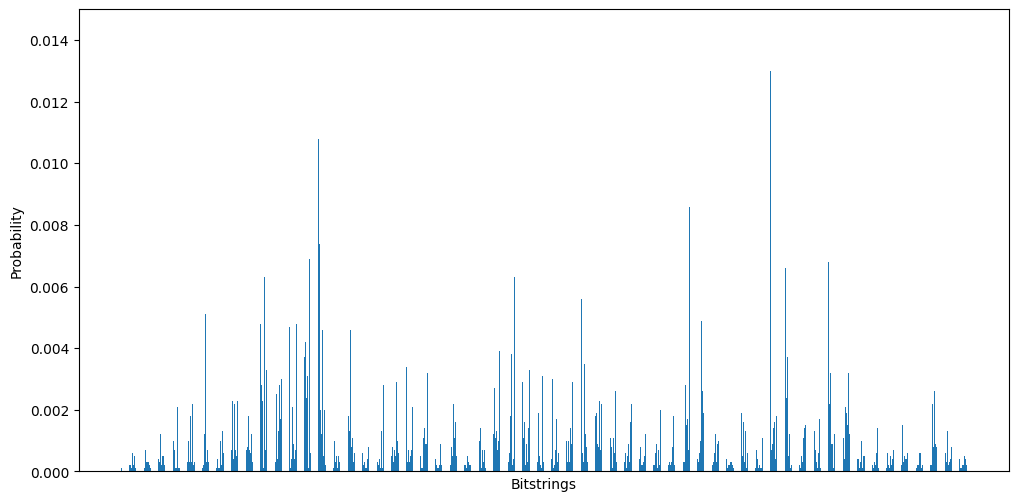

In [7]:
plot_histogram(rr3_10_def[0], keep_top=None, y_lim=0.015)

### FOM

In [8]:
rr3_10_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=1)
print(rr3_10_fom[1], rr3_10_fom[2])

KeyboardInterrupt: 

In [ ]:
plot_histogram(rr3_10_fom[0], keep_top=None, y_lim=0.015)

### SAM2

ecr Count: 63, Depth: 144


9.246440000000042 0.04989599583134022


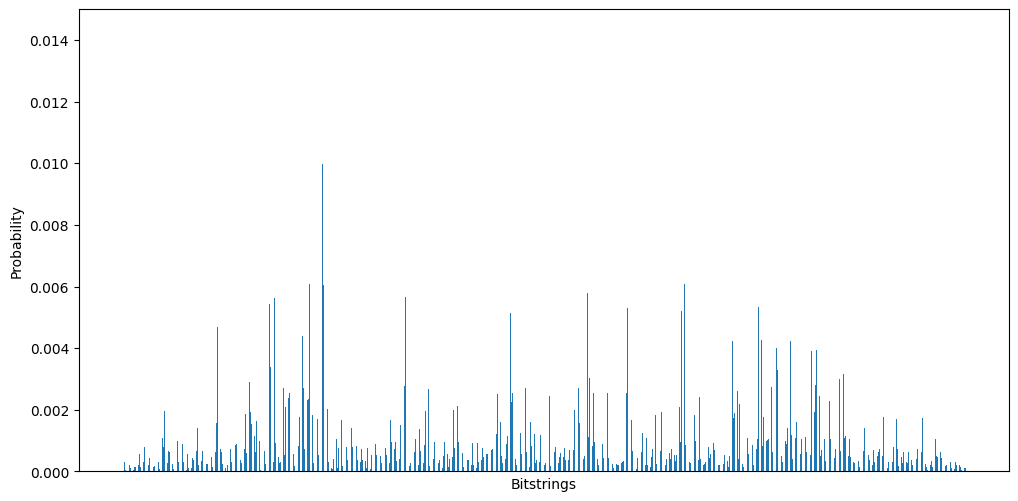

In [ ]:
rr3_10_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=1)
print(rr3_10_sam2[1], rr3_10_sam2[2])

In [ ]:
plot_histogram(rr3_10_sam2[0], keep_top=None, y_lim=0.015)

### SAM3

ecr Count: 66, Depth: 201


9.256440000000039 0.021725984442601022


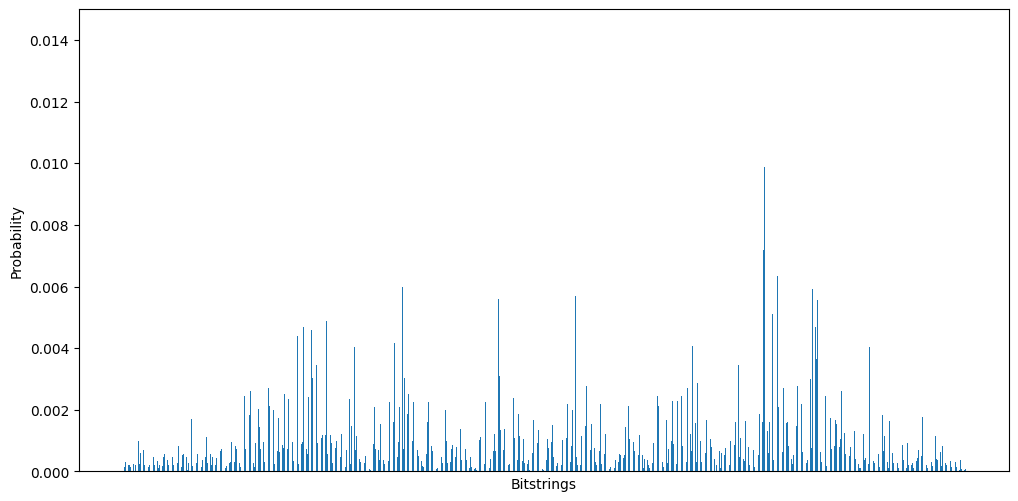

In [ ]:
rr3_10_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=1)
print(rr3_10_sam3[1], rr3_10_sam3[2])

In [ ]:
plot_histogram(rr3_10_sam3[0], keep_top=None, y_lim=0.015)

### SAM4

ecr Count: 66, Depth: 138


9.311460000000041 0.016562680942408512


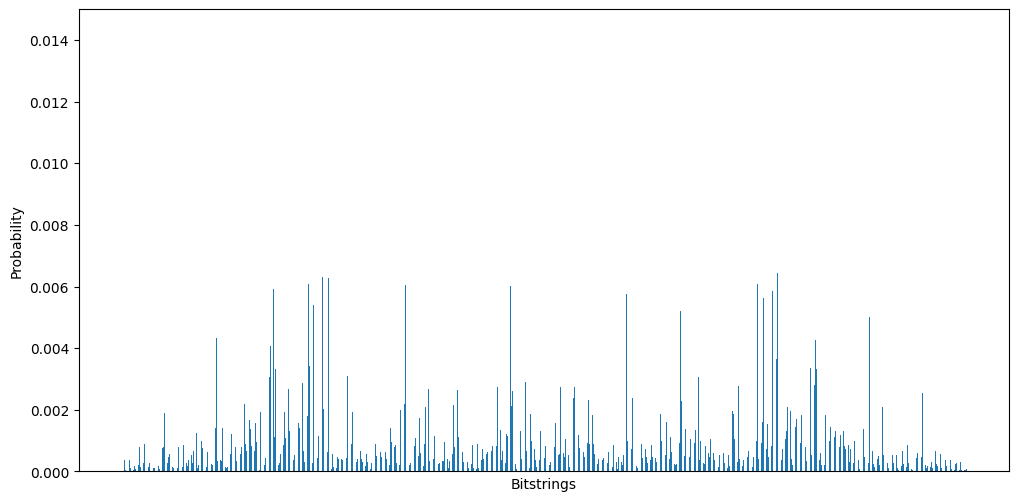

In [ ]:
rr3_10_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=1)
print(rr3_10_sam4[1], rr3_10_sam4[2])

In [ ]:
plot_histogram(rr3_10_sam4[0], keep_top=None, y_lim=0.015)

# **RR3 12**

In [ ]:
rr3_12 = nx.random_regular_graph(n=12, d=3, seed=0)
print('random cut size: ', 0.5 * rr3_12.number_of_edges())

random cut size:  9.0


### DEFAULT

ecr Count: 71, Depth: 117


11.50191999999988 0.0776119166107873


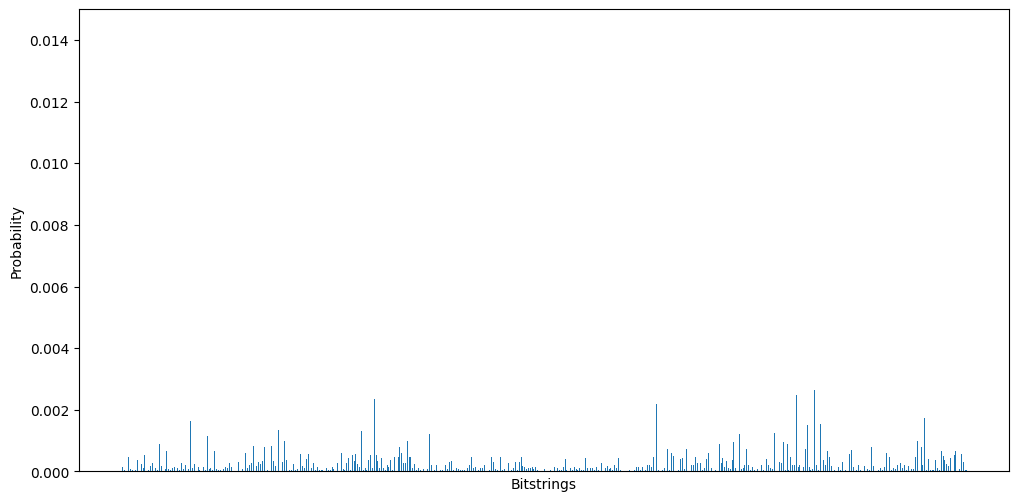

In [ ]:
rr3_12_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=3, 
                            default=True, 
                            gate='ecr', 
                            average_over=1)
print(rr3_12_def[1], rr3_12_def[2])

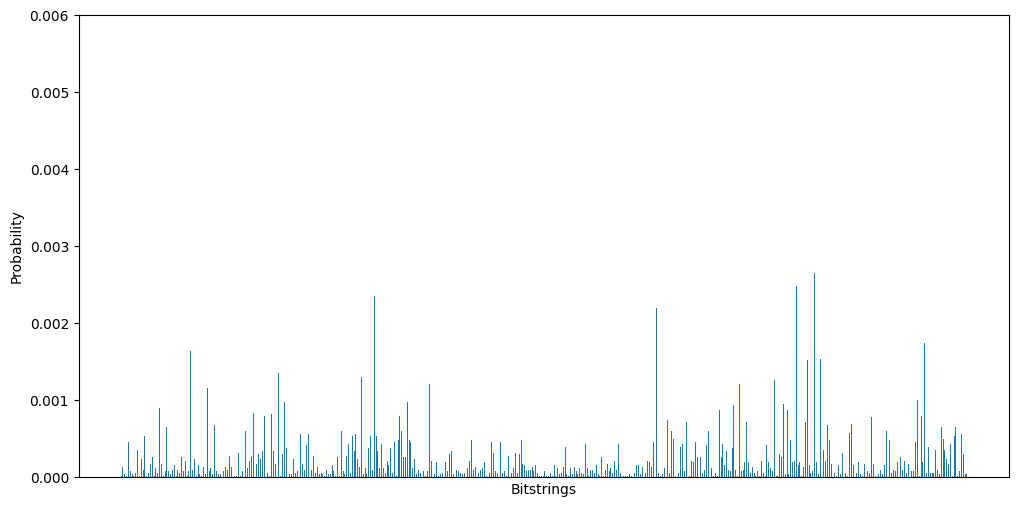

In [ ]:
plot_histogram(rr3_12_def[0], keep_top=None, y_lim=0.006)

### FOM

ecr Count: 75, Depth: 160


10.958939999999894 0.938930563140823


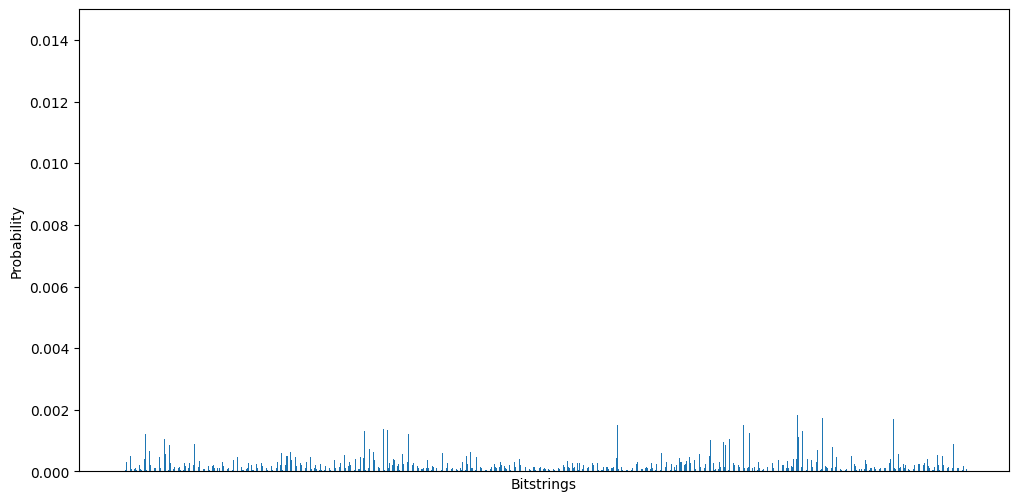

In [ ]:
rr3_12_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=1)
print(rr3_12_fom[1], rr3_12_fom[2])

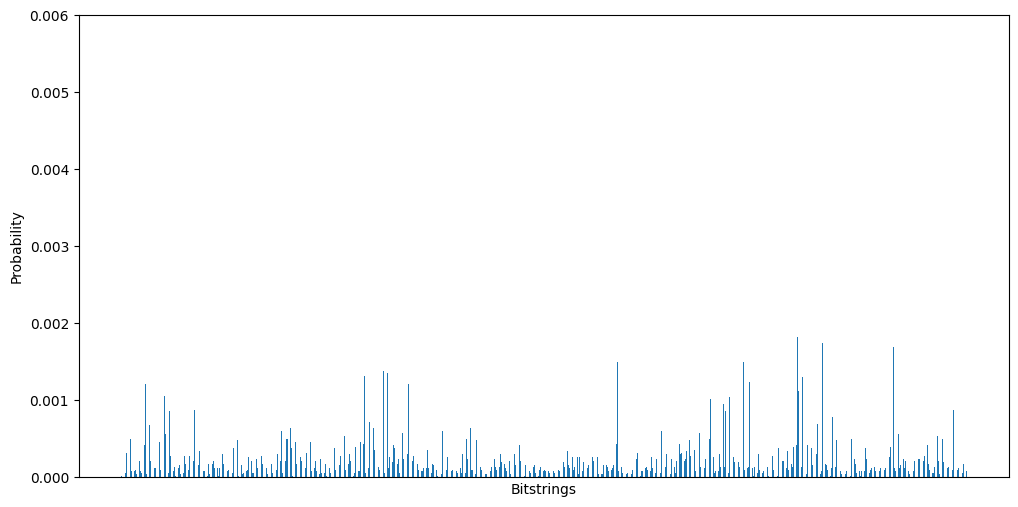

In [ ]:
plot_histogram(rr3_12_fom[0], keep_top=None, y_lim=0.006)

### SAM2

In [ ]:
rr3_12_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=1)
print(rr3_12_sam2[1], rr3_12_sam2[2])

ecr Count: 81, Depth: 188


10.826759999999897 0.9090032048348214


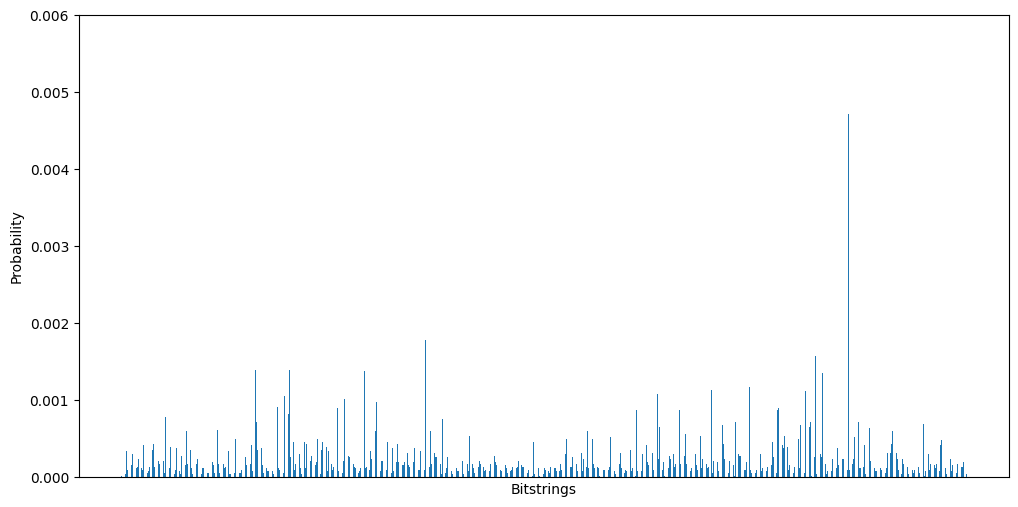

In [ ]:
plot_histogram(rr3_12_sam2[0], keep_top=None, y_lim=0.006)

### SAM3

ecr Count: 88, Depth: 153


10.837119999999894 0.9228432920057211


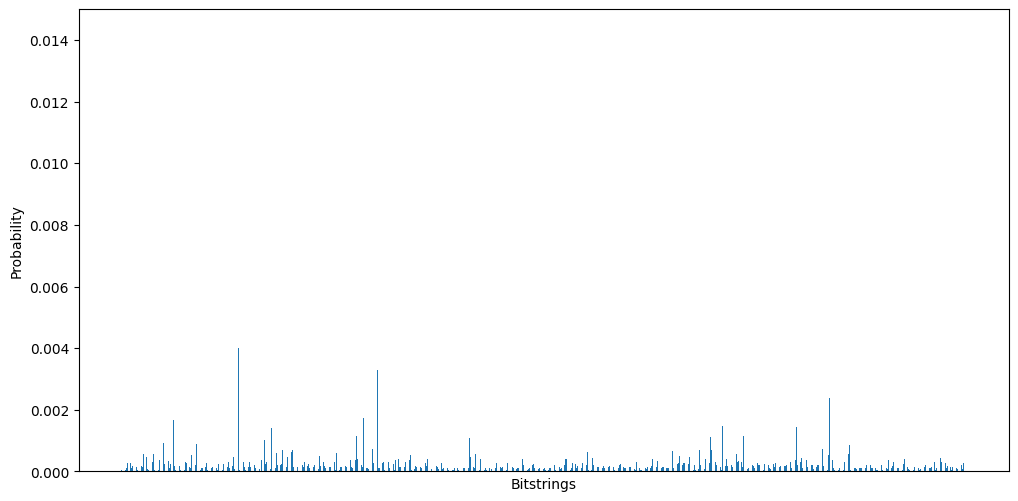

In [ ]:
rr3_12_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=1)
print(rr3_12_sam3[1], rr3_12_sam3[2])

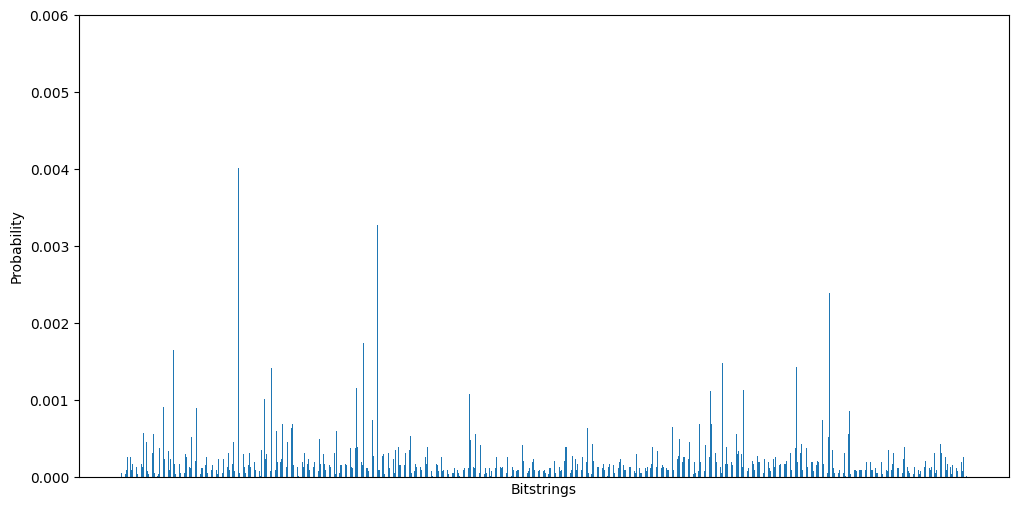

In [ ]:
plot_histogram(rr3_12_sam3[0], keep_top=None, y_lim=0.006)

### SAM4

ecr Count: 81, Depth: 134


11.33761999999987 0.043652784561798406


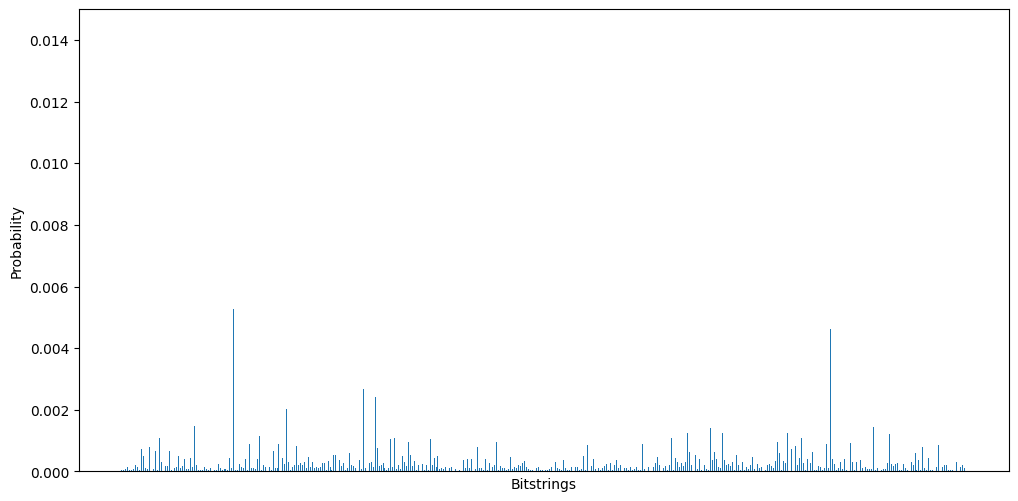

In [ ]:
rr3_12_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=1)
print(rr3_12_sam4[1], rr3_12_sam4[2])

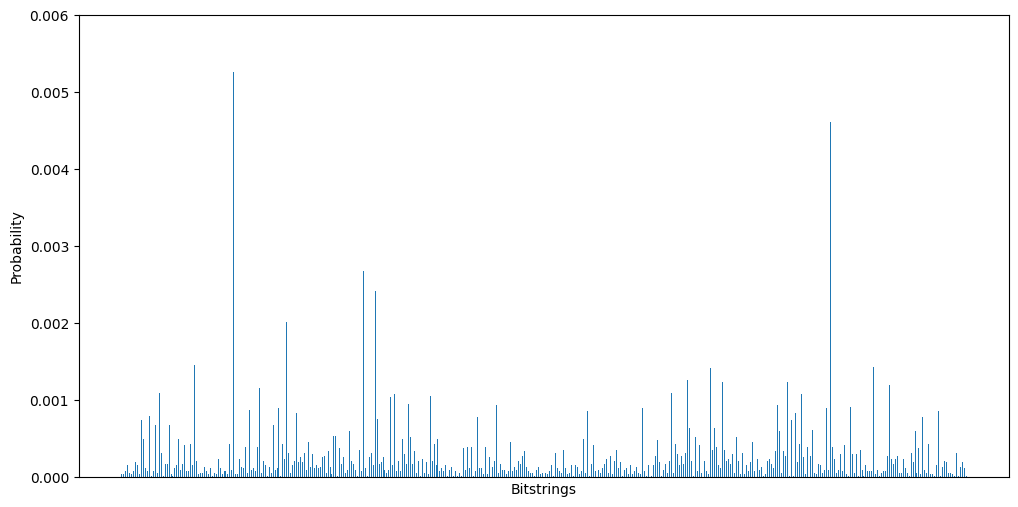

In [ ]:
plot_histogram(rr3_12_sam4[0], keep_top=None, y_lim=0.006)

# **RR3 14**

In [45]:
rr3_14 = nx.random_regular_graph(n=14, d=3, seed=0)
print('random cut size: ', 0.5 * rr3_14.number_of_edges())

random cut size:  10.5


### DEFAULT

In [46]:
rr3_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=3, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(rr3_14_def[1], rr3_14_def[2])

ecr Count: 78, Depth: 132


12.851840000000042 1.1220634484735033


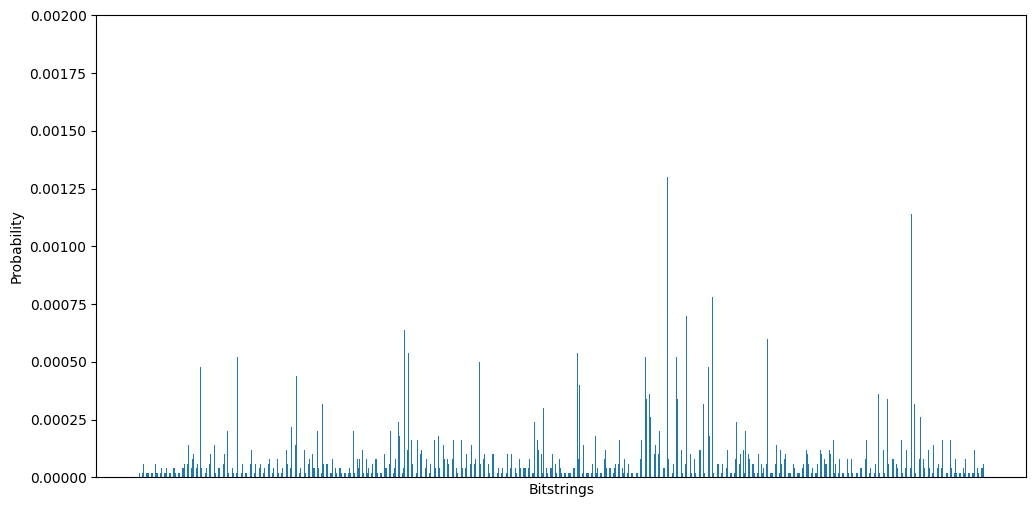

In [50]:
plot_histogram(rr3_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [6]:
rr3_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(rr3_14_fom[1], rr3_14_fom[2])

ecr Count: 100, Depth: 219


12.697919999999991 1.0969328847291362


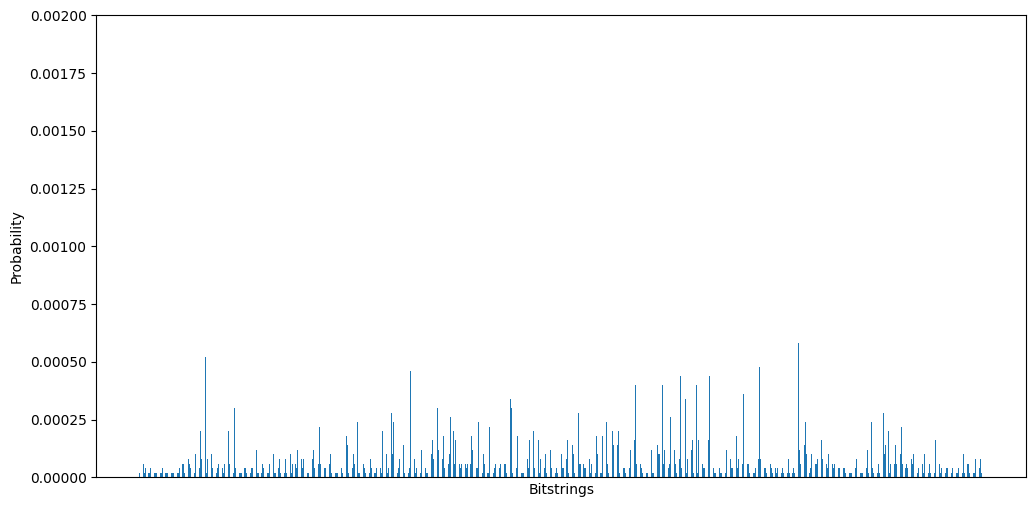

In [90]:
plot_histogram(rr3_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [8]:
rr3_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(rr3_14_sam2[1], rr3_14_sam2[2])

ecr Count: 100, Depth: 132


12.579579999999968 1.0065497770106395


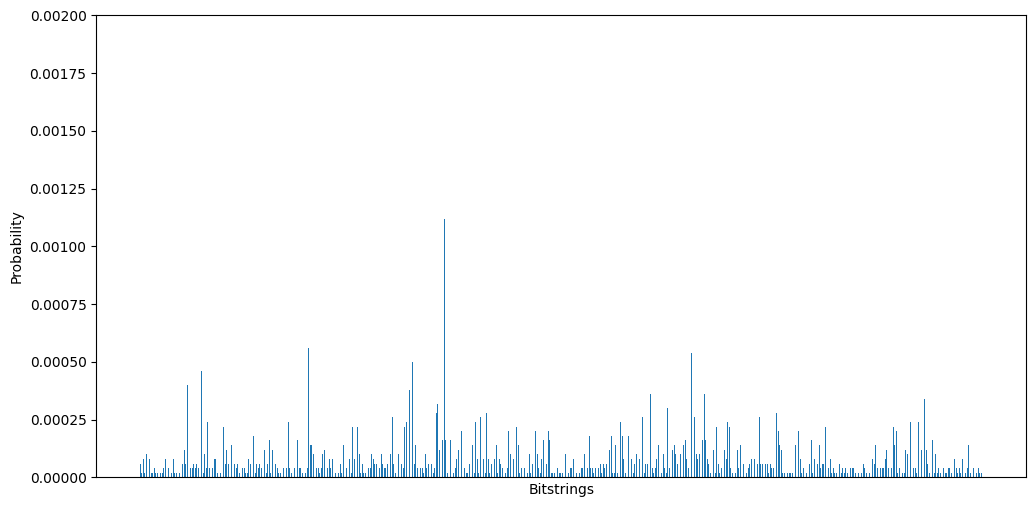

In [9]:
plot_histogram(rr3_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

In [10]:
rr3_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(rr3_14_sam3[1], rr3_14_sam3[2])

ecr Count: 108, Depth: 185


12.868799999999975 0.13482707443241967


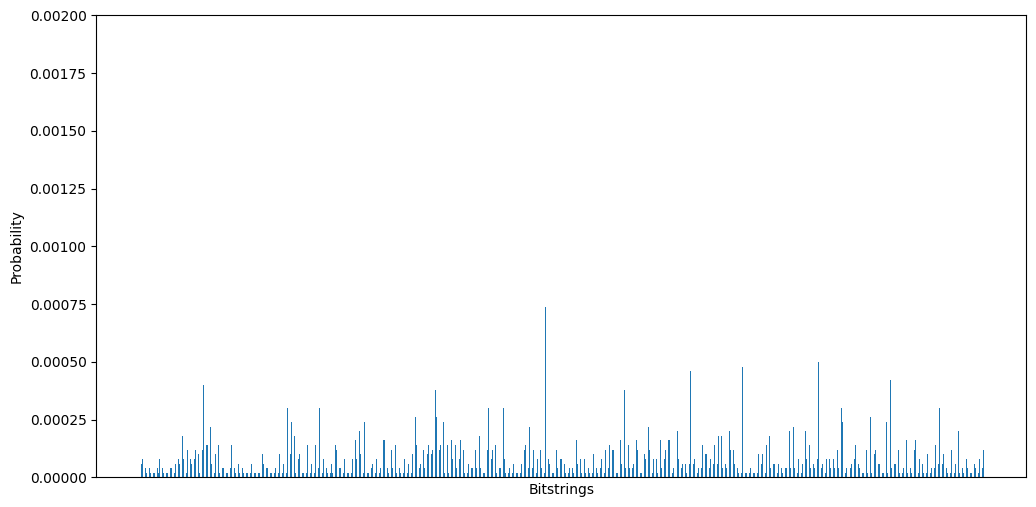

In [11]:
plot_histogram(rr3_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [14]:
rr3_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(rr3_14_sam4[1], rr3_14_sam4[2])

ecr Count: 130, Depth: 200


12.42039999999995 0.9651329835831522


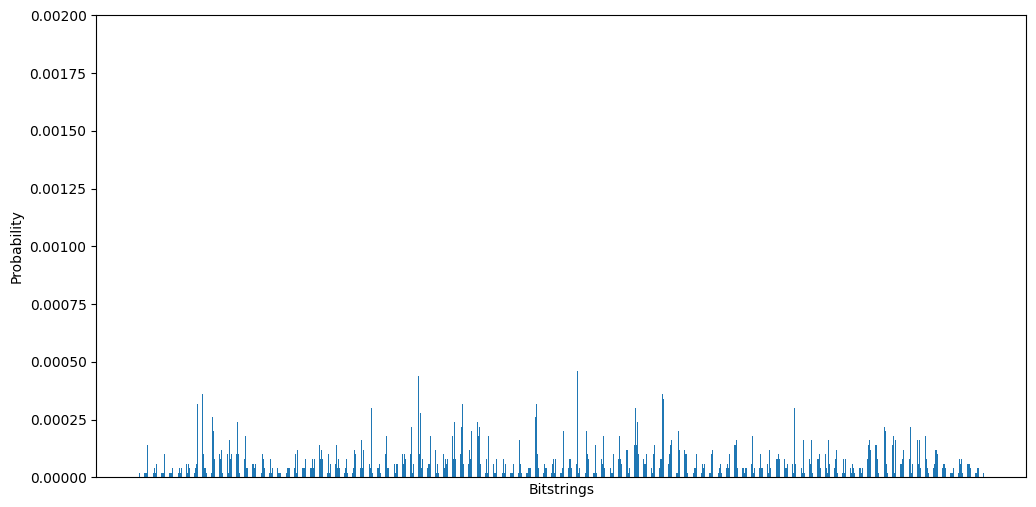

In [15]:
plot_histogram(rr3_14_sam4[0], keep_top=None, y_lim=0.002)

--------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------

# **RR4 10**

In [16]:
rr4_10 = nx.random_regular_graph(n=10, d=4, seed=0)
print('random cut size: ', 0.5 * rr4_10.number_of_edges())

random cut size:  10.0


### DEFAULT

In [17]:
rr4_10_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=4, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(rr4_10_def[1], rr4_10_def[2])

ecr Count: 76, Depth: 224


11.828279999999998 0.02592870224288204


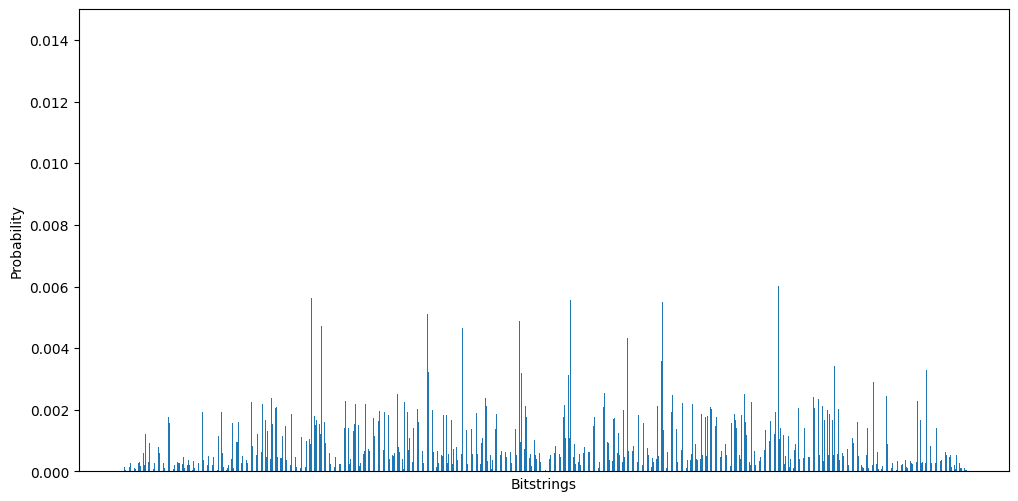

In [18]:
plot_histogram(rr4_10_def[0], keep_top=None, y_lim=0.015)

### FOM

In [19]:
rr4_10_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(rr4_10_fom[1], rr4_10_fom[2])

ecr Count: 81, Depth: 167


11.661559999999977 0.02248320261884788


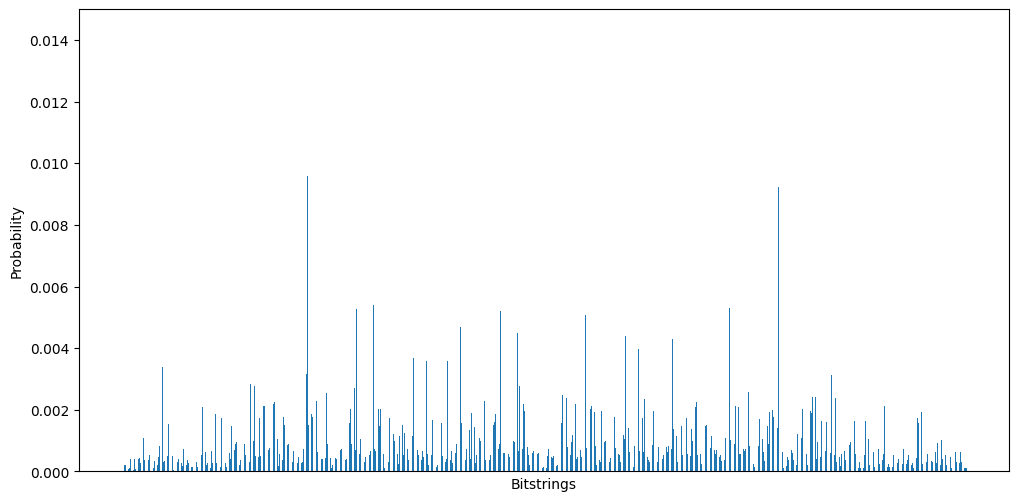

In [20]:
plot_histogram(rr4_10_fom[0], keep_top=None, y_lim=0.015)

### SAM2

In [21]:
rr4_10_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(rr4_10_sam2[1], rr4_10_sam2[2])

ecr Count: 82, Depth: 162


11.589239999999979 0.028659211433682642


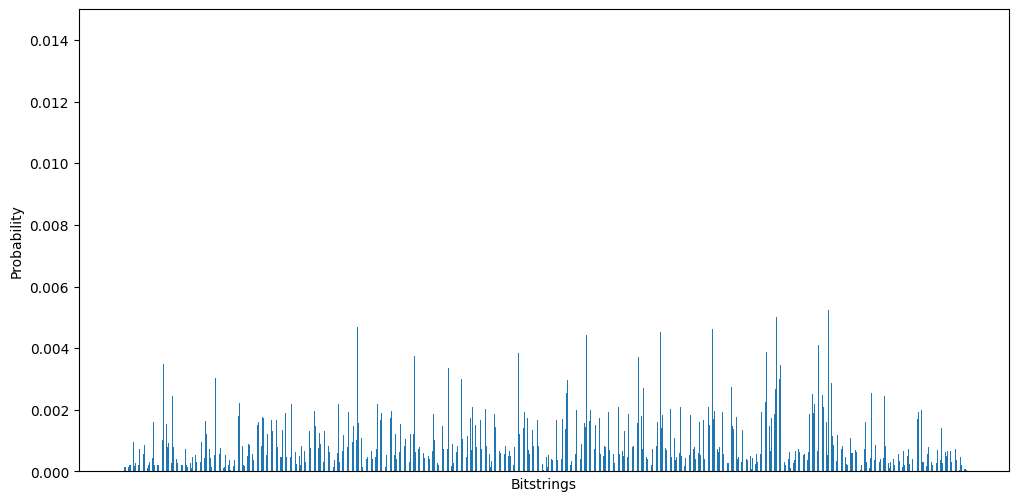

In [22]:
plot_histogram(rr4_10_sam2[0], keep_top=None, y_lim=0.015)

### SAM3

In [23]:
rr4_10_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(rr4_10_sam3[1], rr4_10_sam3[2])

ecr Count: 80, Depth: 161


11.630839999999967 0.006860204078592356


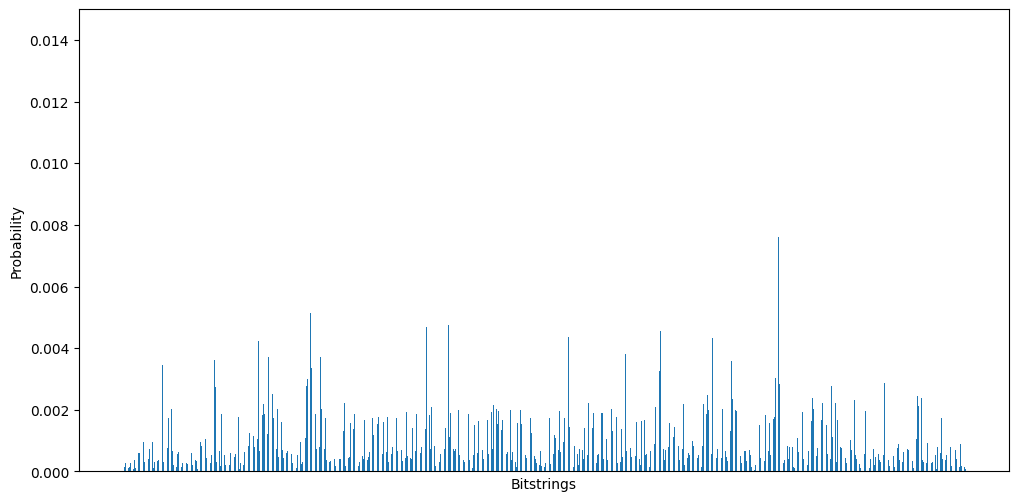

In [24]:
plot_histogram(rr4_10_sam3[0], keep_top=None, y_lim=0.015)

### SAM4

In [25]:
rr4_10_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(rr4_10_sam4[1], rr4_10_sam4[2])

ecr Count: 78, Depth: 173


11.605759999999984 0.03902745700145655


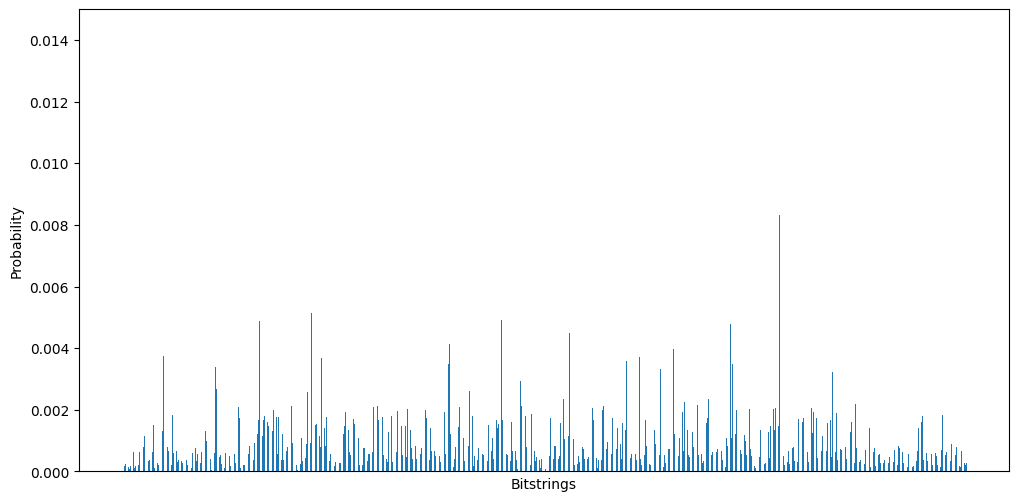

In [26]:
plot_histogram(rr4_10_sam4[0], keep_top=None, y_lim=0.015)

# **RR4 12**

In [27]:
rr4_12 = nx.random_regular_graph(n=12, d=4, seed=0)
print('random cut size: ', 0.5 * rr4_12.number_of_edges())

random cut size:  12.0


### DEFAULT

In [28]:
rr4_12_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=4, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(rr4_12_def[1], rr4_12_def[2])

ecr Count: 108, Depth: 222


14.612200000000332 0.042684329677292715


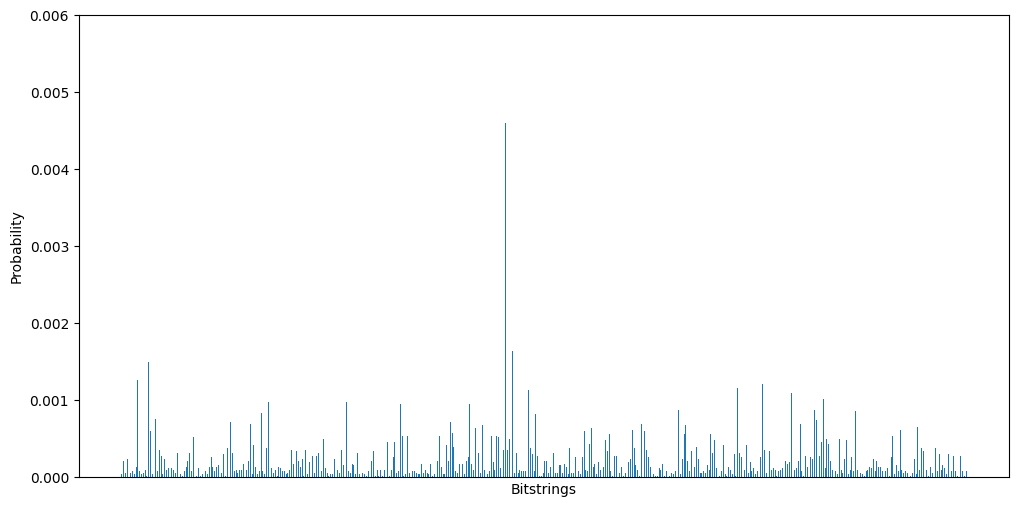

In [29]:
plot_histogram(rr4_12_def[0], keep_top=None, y_lim=0.006)

### FOM

In [30]:
rr4_12_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(rr4_12_fom[1], rr4_12_fom[2])

ecr Count: 110, Depth: 197


14.443840000000325 0.030138984720776165


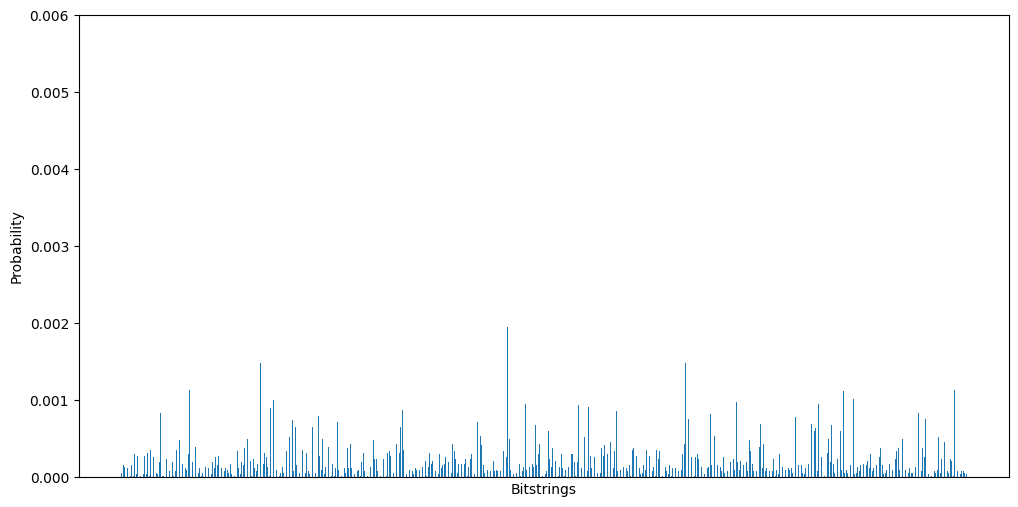

In [31]:
plot_histogram(rr4_12_fom[0], keep_top=None, y_lim=0.006)

### SAM2

In [32]:
rr4_12_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(rr4_12_sam2[1], rr4_12_sam2[2])

ecr Count: 117, Depth: 197


14.269240000000298 0.06392162701309922


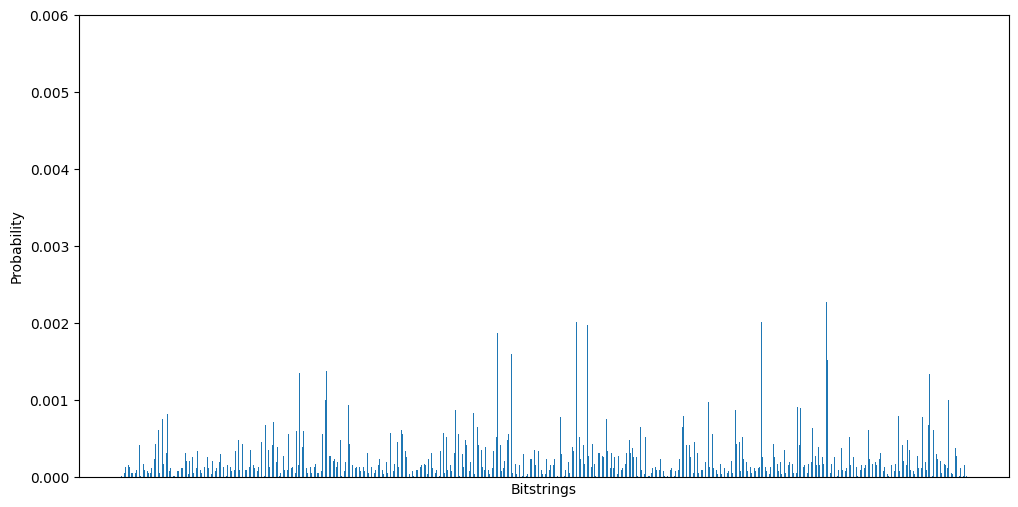

In [33]:
plot_histogram(rr4_12_sam2[0], keep_top=None, y_lim=0.006)

### SAM3

In [34]:
rr4_12_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(rr4_12_sam3[1], rr4_12_sam3[2])

ecr Count: 115, Depth: 256


14.3157200000003 0.08029421897002055


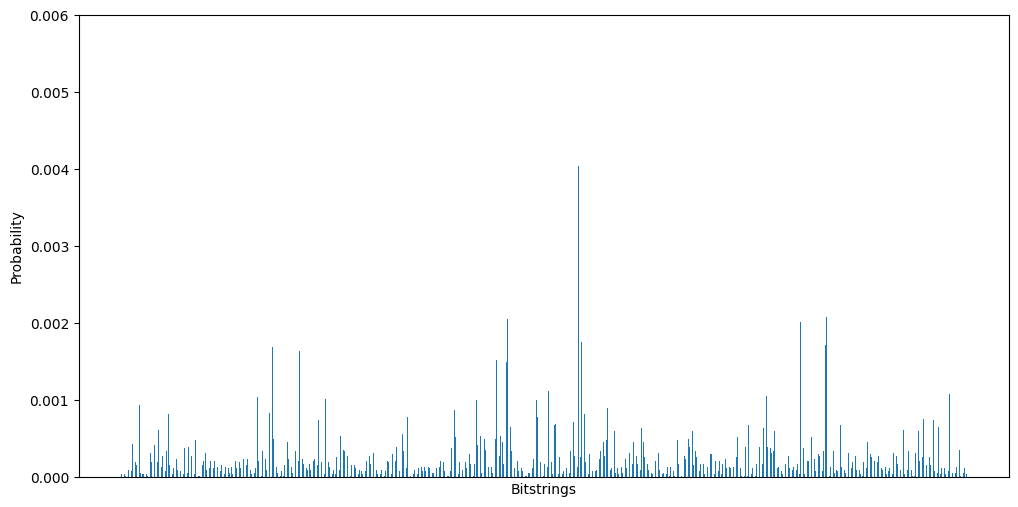

In [35]:
plot_histogram(rr4_12_sam3[0], keep_top=None, y_lim=0.006)

### SAM4

In [36]:
rr4_12_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(rr4_12_sam4[1], rr4_12_sam4[2])

ecr Count: 108, Depth: 208


14.363560000000286 0.06806836563340266


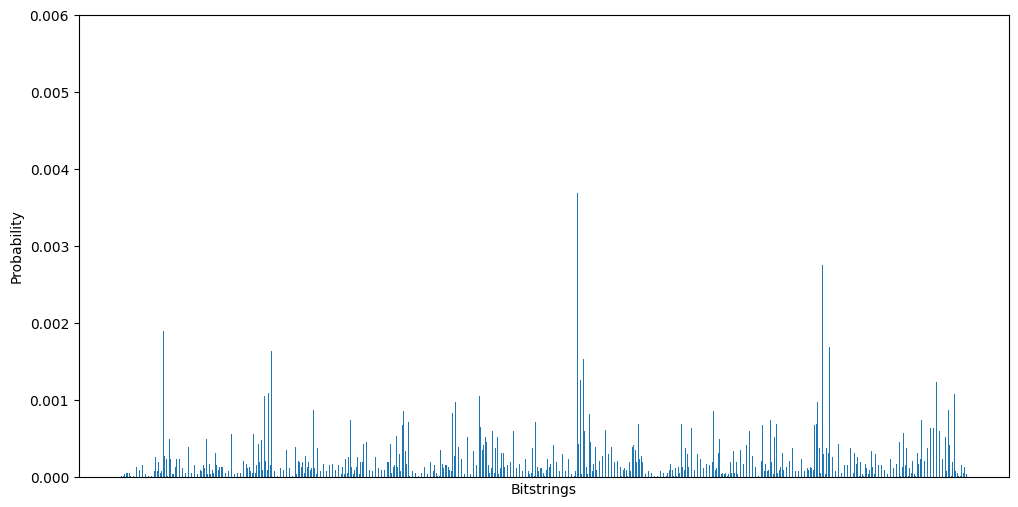

In [37]:
plot_histogram(rr4_12_sam4[0], keep_top=None, y_lim=0.006)

# **RR4 14**

In [38]:
rr4_14 = nx.random_regular_graph(n=14, d=4, seed=0)
print('random cut size: ', 0.5 * rr4_14.number_of_edges())

random cut size:  14.0


### DEFAULT

In [39]:
rr4_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=4, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(rr4_14_def[1], rr4_14_def[2])

ecr Count: 132, Depth: 255


17.08631999999998 0.057121288500843324


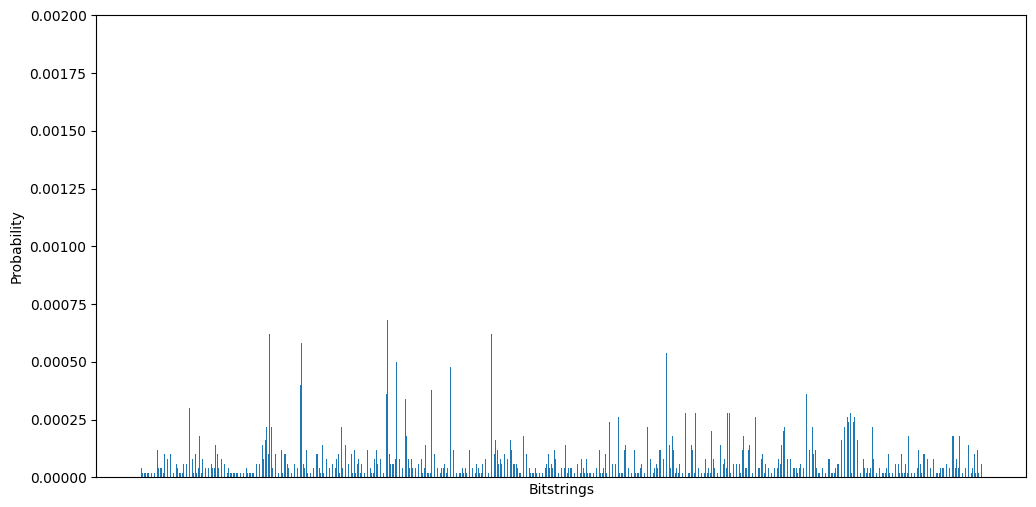

In [40]:
plot_histogram(rr4_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [41]:
rr4_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(rr4_14_fom[1], rr4_14_fom[2])

ecr Count: 152, Depth: 279


16.70792000000005 0.03485893859543728


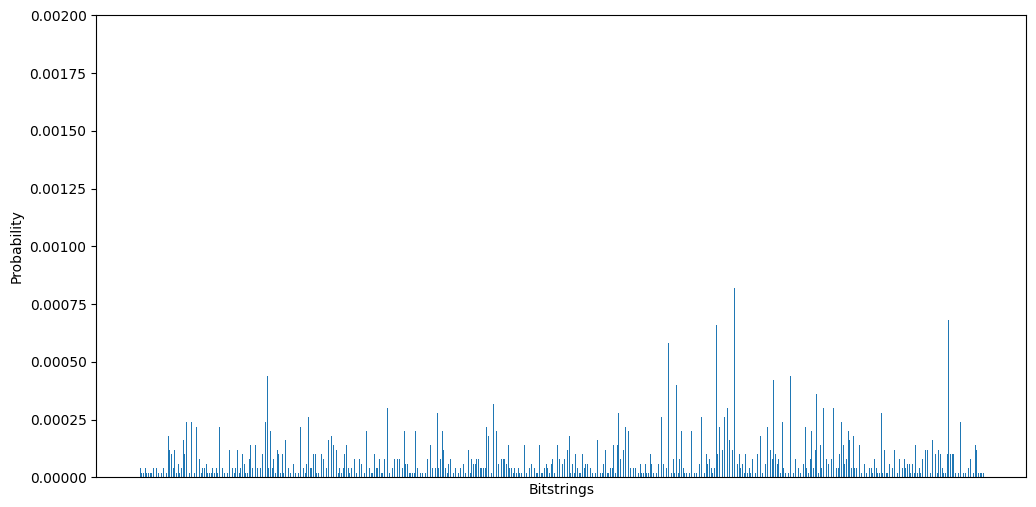

In [42]:
plot_histogram(rr4_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [43]:
rr4_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(rr4_14_sam2[1], rr4_14_sam2[2])

ecr Count: 147, Depth: 289


16.629480000000047 0.08807820161648482


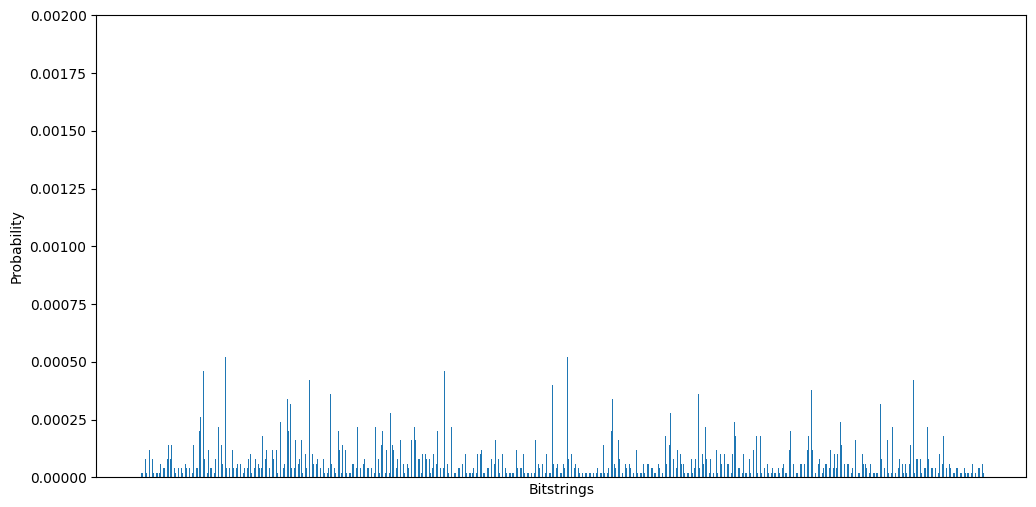

In [44]:
plot_histogram(rr4_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

In [45]:
rr4_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(rr4_14_sam3[1], rr4_14_sam3[2])

ecr Count: 137, Depth: 236


16.66668000000005 0.08001645830700255


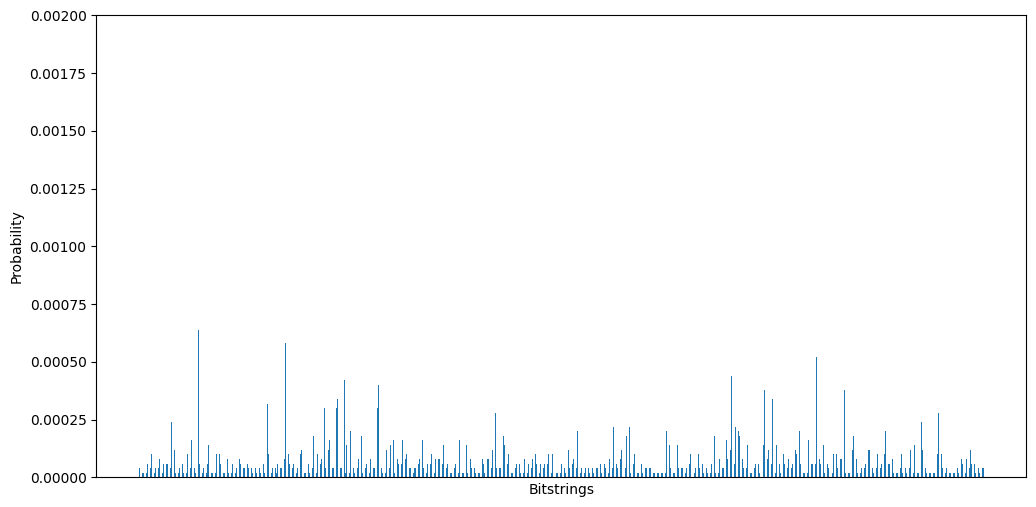

In [46]:
plot_histogram(rr4_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [47]:
rr4_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(rr4_14_sam4[1], rr4_14_sam4[2])

ecr Count: 135, Depth: 239


16.1875200000001 1.0887292453129747


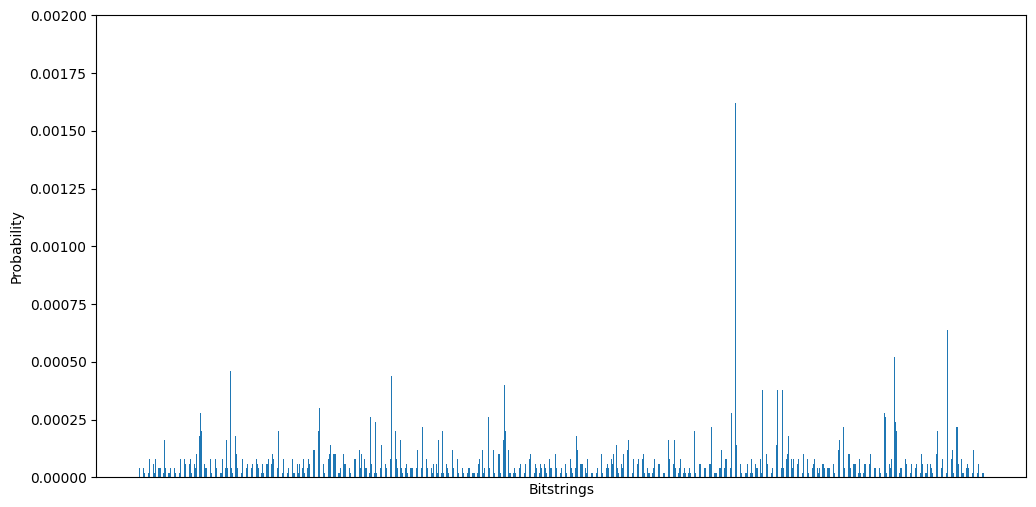

In [48]:
plot_histogram(rr4_14_sam4[0], keep_top=None, y_lim=0.002)

---------------------------------------------------------------------------------------------
---------------------------------------------------------------------------------------------

# **RR5 10**

In [36]:
rr5_10 = nx.random_regular_graph(n=10, d=5, seed=0)
print('random cut size: ', 0.5 * rr5_10.number_of_edges())

random cut size:  12.5


### DEFAULT

In [37]:
rr5_10_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=5, 
                            default=True, 
                            gate='ecr', 
                            average_over=1)
print(rr5_10_def[1], rr5_10_def[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 108, Depth: 285


14.50280000000001 0.0


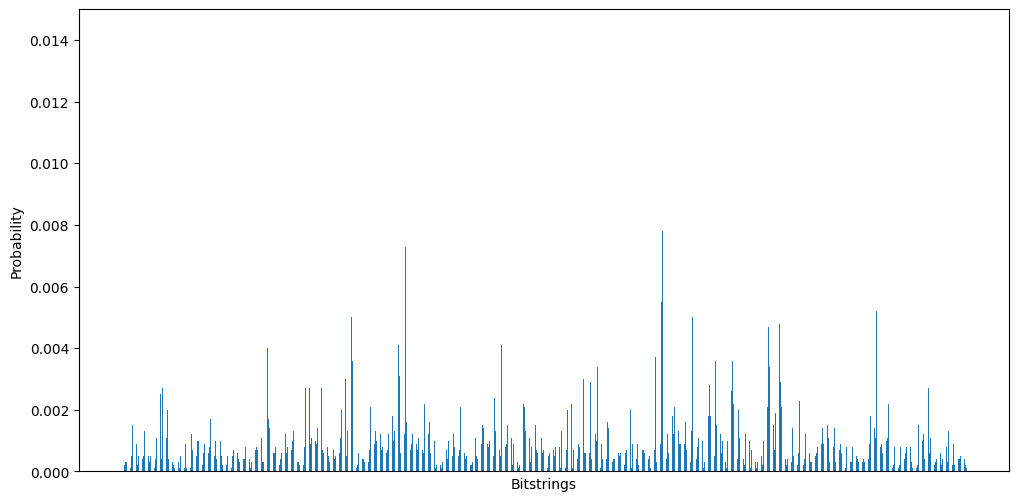

In [38]:
plot_histogram(rr5_10_def[0], keep_top=None, y_lim=0.015)

### FOM

In [39]:
rr5_10_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=5,
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=1)
print(rr5_10_fom[1], rr5_10_fom[2])

ecr Count: 119, Depth: 319


14.07570000000001 0.0


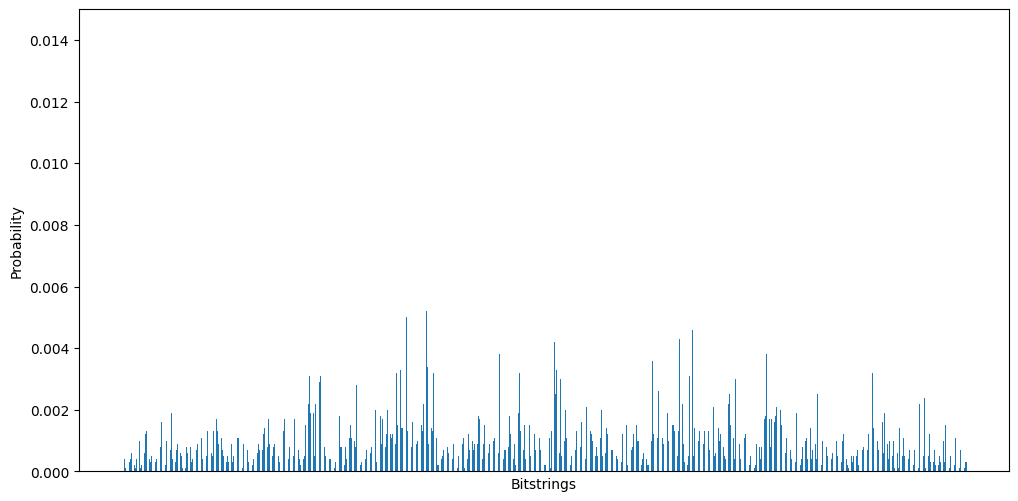

In [40]:
plot_histogram(rr5_10_fom[0], keep_top=None, y_lim=0.015)

### SAM2

In [41]:
rr5_10_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=1)
print(rr5_10_sam2[1], rr5_10_sam2[2])

ecr Count: 108, Depth: 217


14.246299999999982 0.0


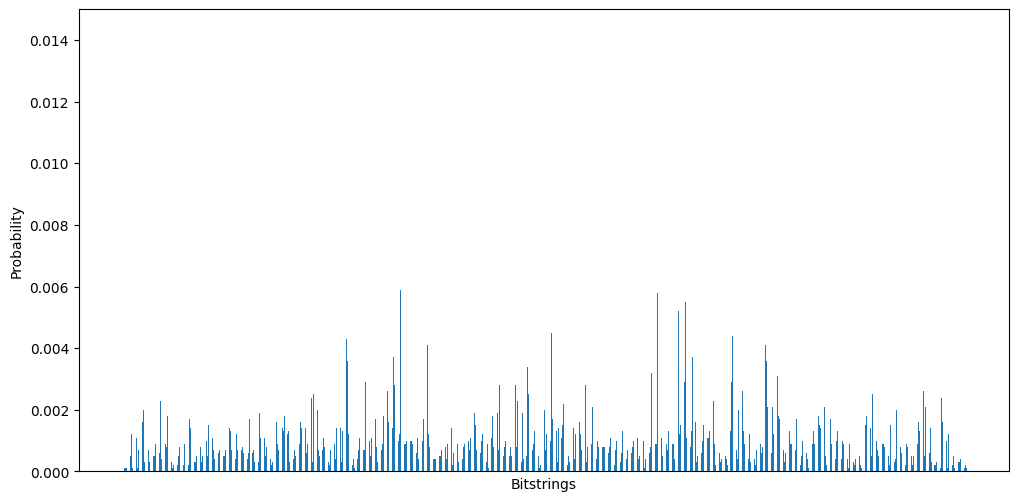

In [42]:
plot_histogram(rr5_10_sam2[0], keep_top=None, y_lim=0.015)

### SAM3

In [43]:
rr5_10_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=1)
print(rr5_10_sam3[1], rr5_10_sam3[2])

ecr Count: 118, Depth: 252


14.202700000000005 0.0


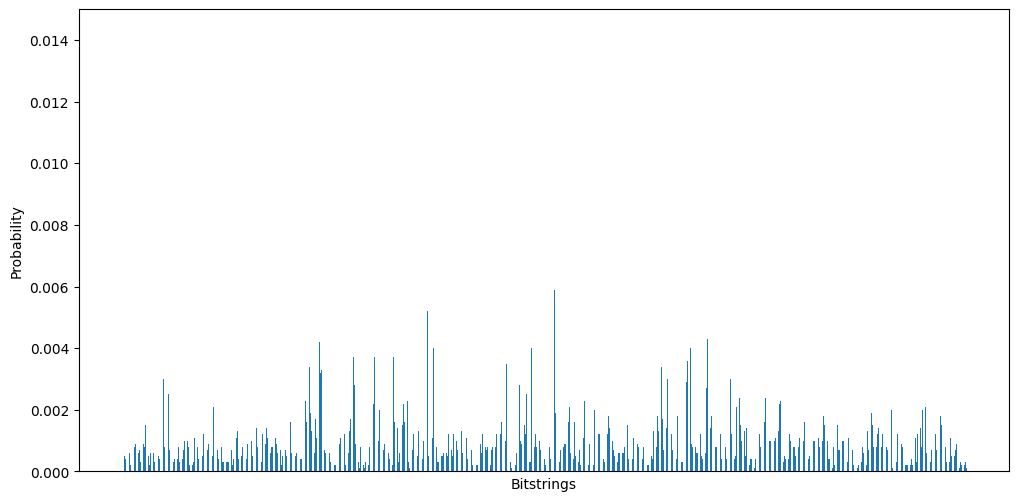

In [44]:
plot_histogram(rr5_10_sam3[0], keep_top=None, y_lim=0.015)

### SAM4

In [45]:
rr5_10_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=10, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=1)
print(rr5_10_sam4[1], rr5_10_sam4[2])

ecr Count: 111, Depth: 277


14.213099999999997 0.0


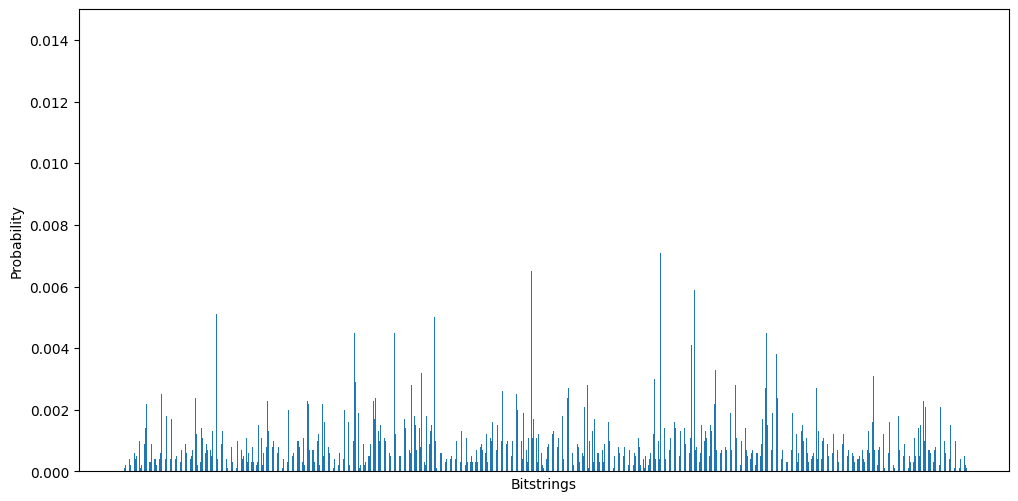

In [46]:
plot_histogram(rr5_10_sam4[0], keep_top=None, y_lim=0.015)

# **RR5 12**

In [47]:
rr5_12 = nx.random_regular_graph(n=12, d=5, seed=0)
print('random cut size: ', 0.5 * rr5_12.number_of_edges())

random cut size:  15.0


### DEFAULT

In [48]:
rr5_12_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=5, 
                            default=True, 
                            gate='ecr', 
                            average_over=1)
print(rr5_12_def[1], rr5_12_def[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 133, Depth: 321


17.458900000000014 0.0


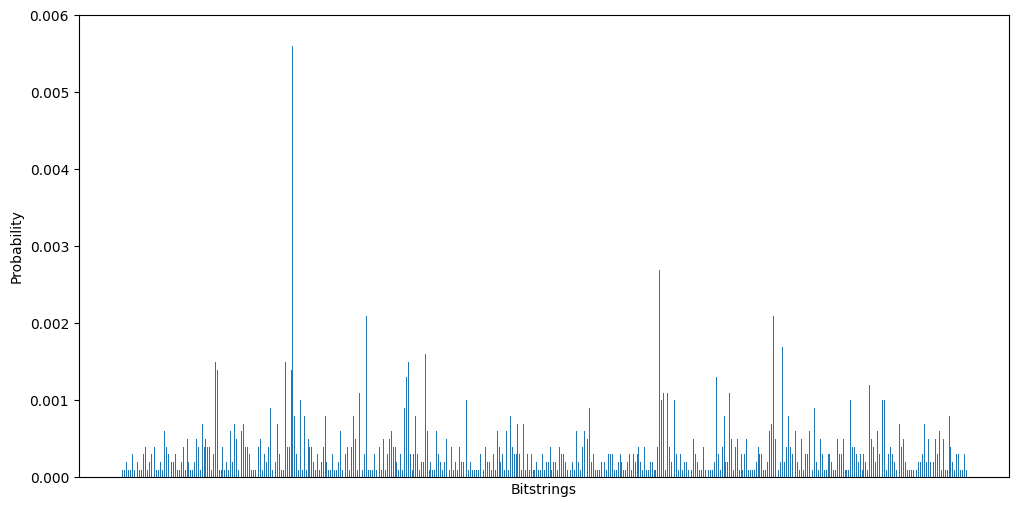

In [49]:
plot_histogram(rr5_12_def[0], keep_top=None, y_lim=0.006)

### FOM

In [50]:
rr5_12_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=5, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=1)
print(rr5_12_fom[1], rr5_12_fom[2])

ecr Count: 154, Depth: 293


16.771900000000045 0.0


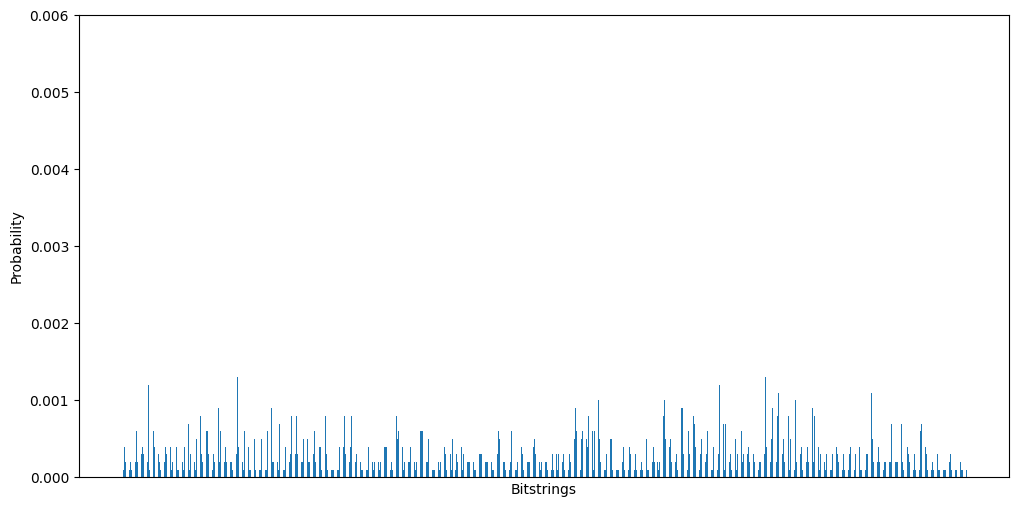

In [51]:
plot_histogram(rr5_12_fom[0], keep_top=None, y_lim=0.006)

### SAM2

In [52]:
rr5_12_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=1)
print(rr5_12_sam2[1], rr5_12_sam2[2])

ecr Count: 147, Depth: 339


17.047199999999993 0.0


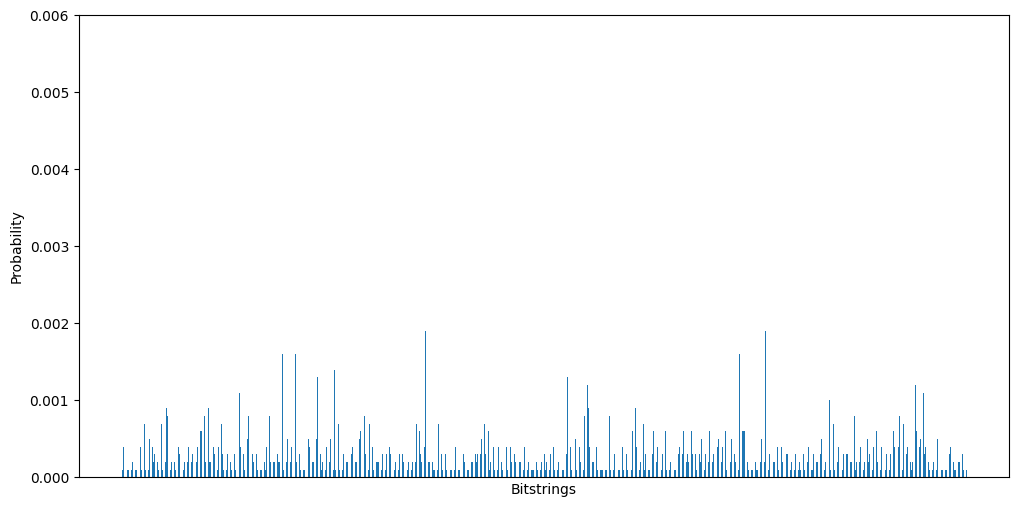

In [53]:
plot_histogram(rr5_12_sam2[0], keep_top=None, y_lim=0.006)

### SAM3

In [54]:
rr5_12_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=1)
print(rr5_12_sam3[1], rr5_12_sam3[2])

ecr Count: 140, Depth: 363


17.108400000000007 0.0


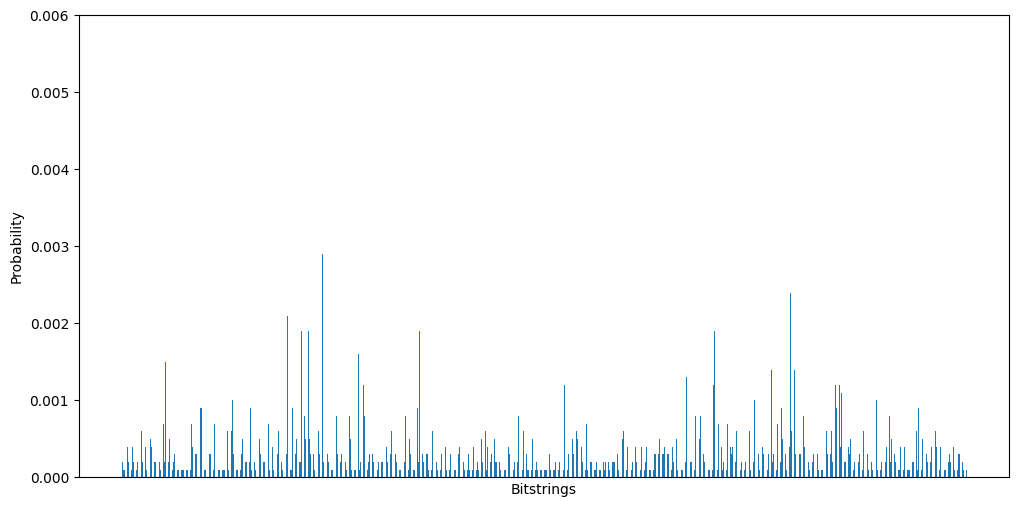

In [55]:
plot_histogram(rr5_12_sam3[0], keep_top=None, y_lim=0.006)

### SAM4

In [56]:
rr5_12_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=12, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=1)
print(rr5_12_sam4[1], rr5_12_sam4[2])

ecr Count: 145, Depth: 342


17.257800000000014 0.0


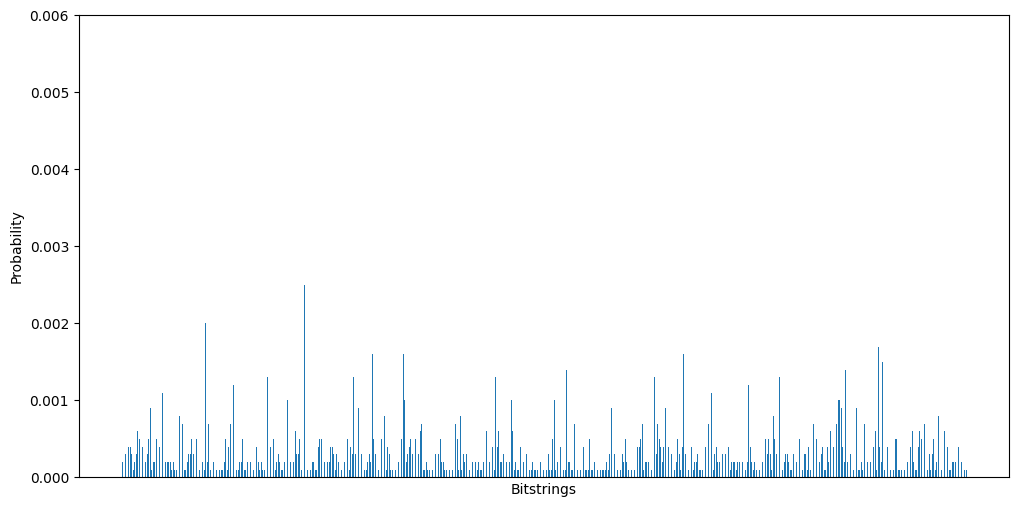

In [57]:
plot_histogram(rr5_12_sam4[0], keep_top=None, y_lim=0.006)

# **RR5 14**

In [58]:
rr5_14 = nx.random_regular_graph(n=14, d=5, seed=0)
print('random cut size: ', 0.5 * rr5_14.number_of_edges())

random cut size:  17.5


### DEFAULT

In [59]:
rr5_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=True, 
                            gate='ecr', 
                            average_over=1)
print(rr5_14_def[1], rr5_14_def[2])

ecr Count: 178, Depth: 372


20.226199999998716 0.0


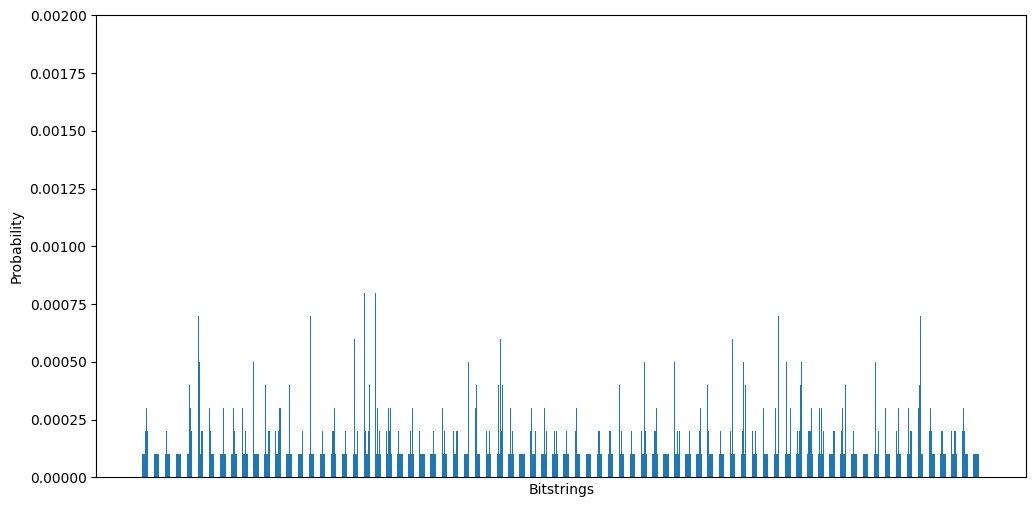

In [60]:
plot_histogram(rr5_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [61]:
rr5_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='1D',
                            gate='ecr',
                            average_over=1)
print(rr5_14_fom[1], rr5_14_fom[2])

ecr Count: 174, Depth: 294


19.7056999999988 0.0


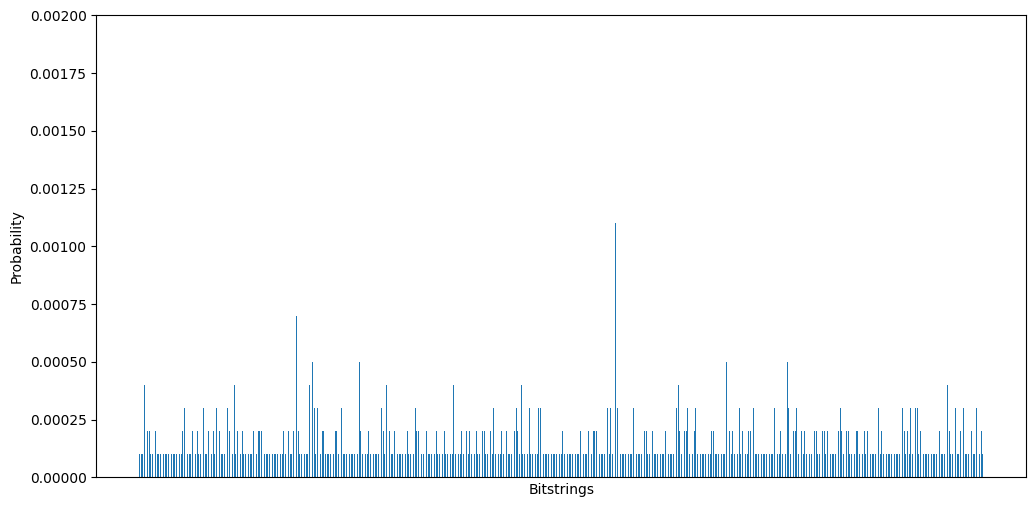

In [62]:
plot_histogram(rr5_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [63]:
rr5_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=1)
print(rr5_14_sam2[1], rr5_14_sam2[2])

ecr Count: 173, Depth: 273


20.012499999998848 0.0


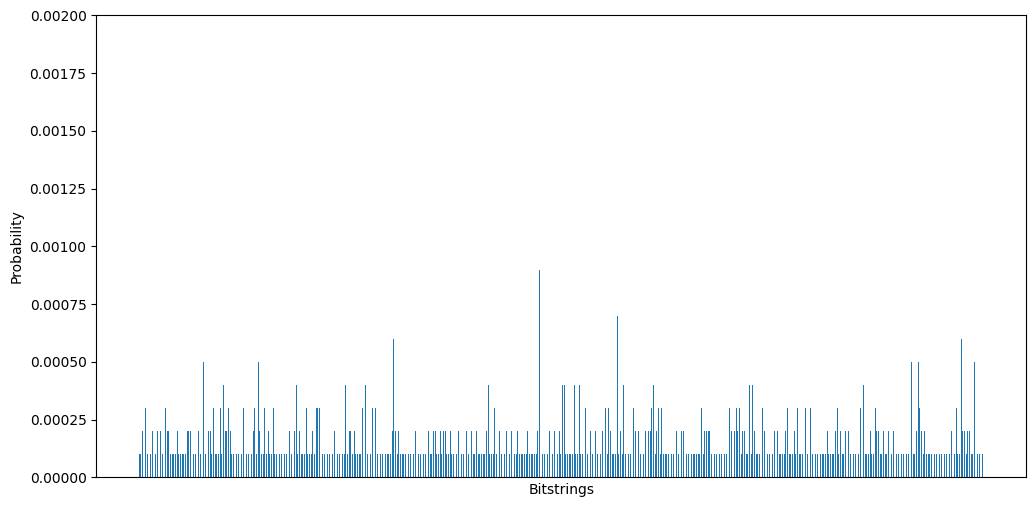

In [64]:
plot_histogram(rr5_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

In [ ]:
rr5_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=1)
print(rr5_14_sam3[1], rr5_14_sam3[2])

ecr Count: 177, Depth: 332


Running 1 iterations:   0%|          | 0/1 [00:00<?, ?it/s]

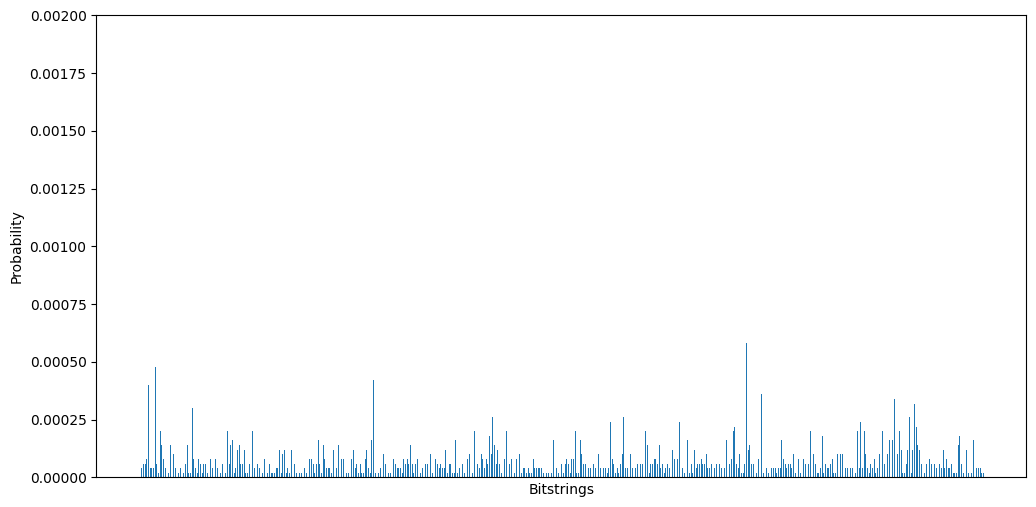

In [ ]:
plot_histogram(rr5_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [ ]:
rr5_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=1)
print(rr5_14_sam4[1], rr5_14_sam4[2])

ecr Count: 196, Depth: 321


19.97605999999879 0.058810529669416564


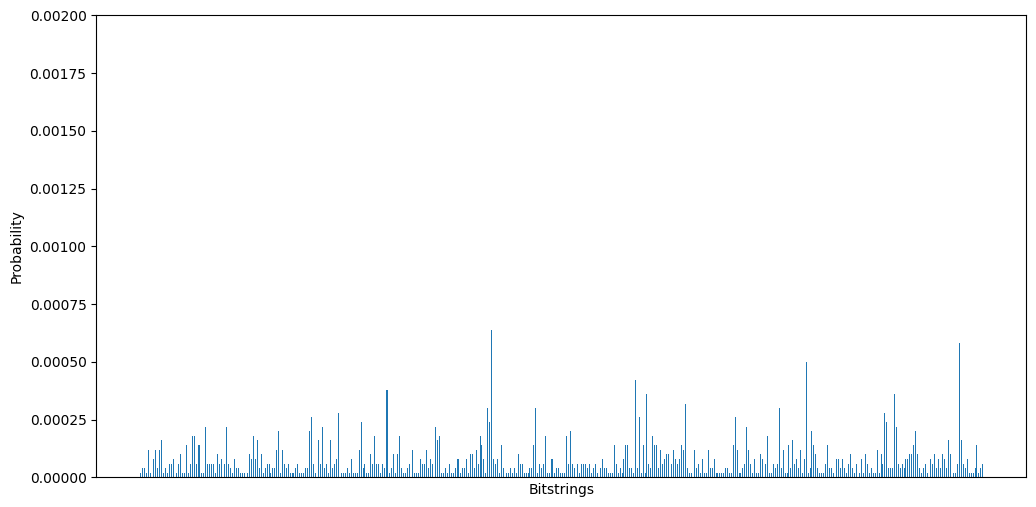

In [ ]:
plot_histogram(rr5_14_sam4[0], keep_top=None, y_lim=0.002)

--------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------

====================================================================================================================

# **BA2 10**

In [121]:
ba2_10 = nx.barabasi_albert_graph(n=10, m=2, seed=0)
print('random cut size: ', 0.5 * ba2_10.number_of_edges())

random cut size:  8.0


### DEFAULT

In [122]:
ba2_10_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=2, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba2_10_def[1], ba2_10_def[2])

ecr Count: 62, Depth: 172


9.938839999999995 0.34952888063792686


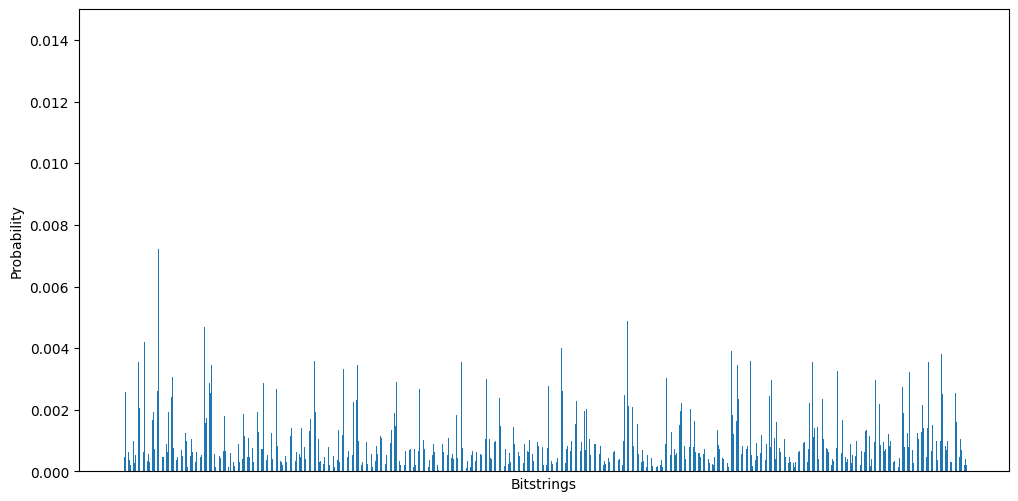

In [123]:
plot_histogram(ba2_10_def[0], keep_top=None, y_lim=0.015)

In [ ]:
                                                                       
ecr Count: 69, Depth: 217
                                                                   
9.755739999999994 0.3632096287269918


### FOM

In [124]:
ba2_10_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=2, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba2_10_fom[1], ba2_10_fom[2])

ecr Count: 69, Depth: 217


9.755739999999994 0.3632096287269918


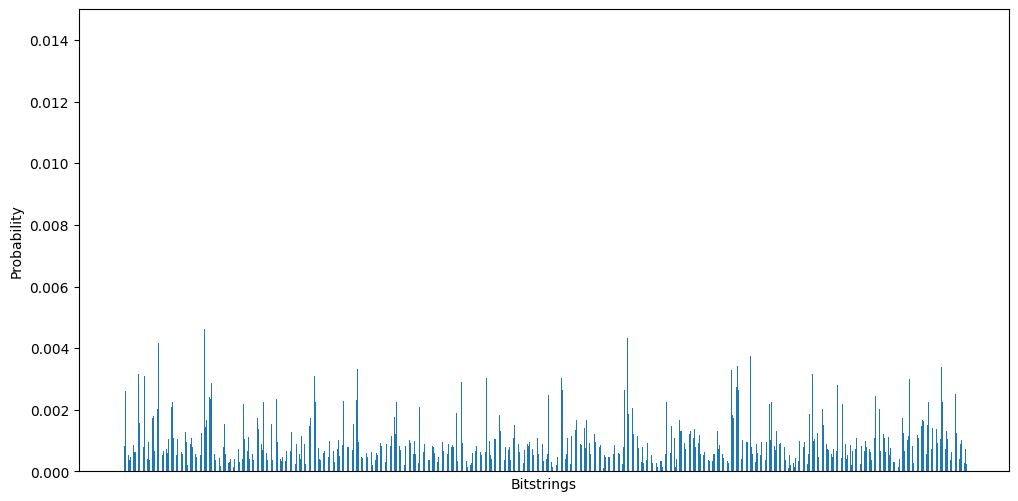

In [125]:
plot_histogram(ba2_10_fom[0], keep_top=None, y_lim=0.015)

### SAM2

In [126]:
ba2_10_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba2_10_sam2[1], ba2_10_sam2[2])

ecr Count: 67, Depth: 177


9.725619999999996 0.26513688087476867


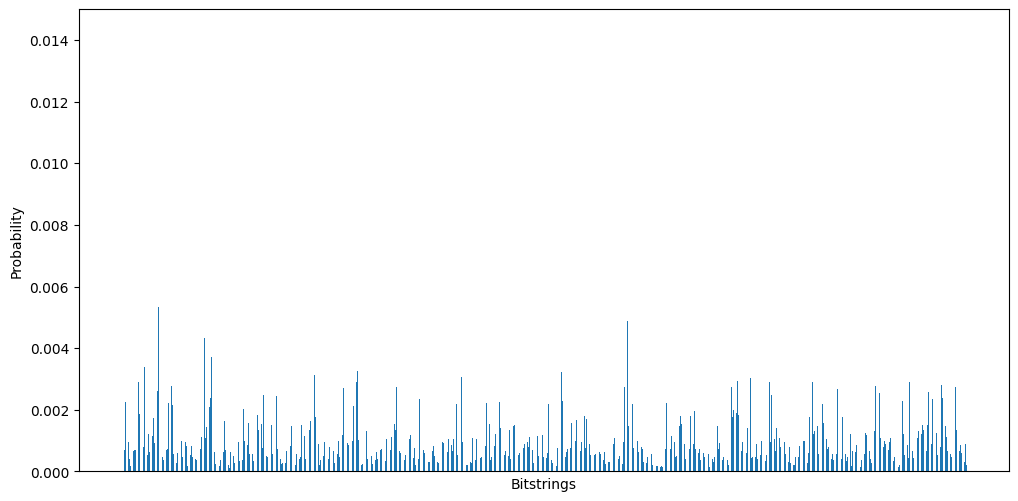

In [127]:
plot_histogram(ba2_10_sam2[0], keep_top=None, y_lim=0.015)

### SAM3

In [128]:
ba2_10_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba2_10_sam3[1], ba2_10_sam3[2])

ecr Count: 55, Depth: 164


9.59466 0.572925595867387


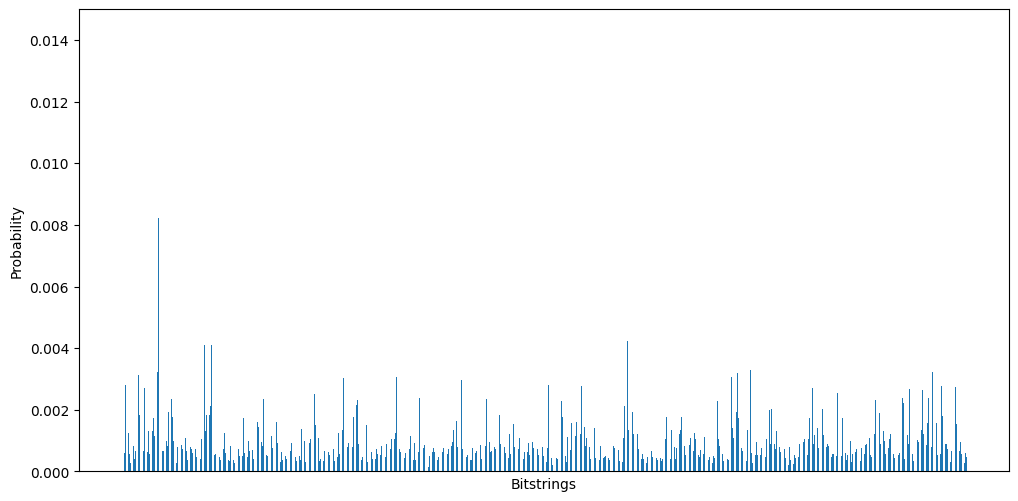

In [129]:
plot_histogram(ba2_10_sam3[0], keep_top=None, y_lim=0.015)

### SAM4

In [130]:
ba2_10_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba2_10_sam4[1], ba2_10_sam4[2])

ecr Count: 55, Depth: 172


9.769580000000003 0.37881778944501204


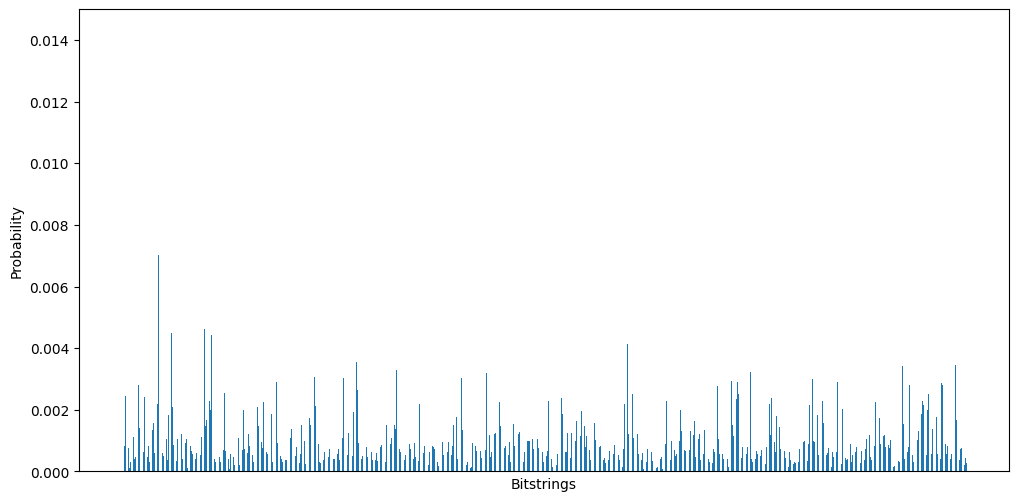

In [131]:
plot_histogram(ba2_10_sam4[0], keep_top=None, y_lim=0.015)

# **BA2 12**

In [132]:
ba2_12 = nx.barabasi_albert_graph(n=12, m=2, seed=0)
print('random cut size: ', 0.5 * ba2_12.number_of_edges())

random cut size:  10.0


### DEFAULT

In [133]:
ba2_12_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=2, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba2_12_def[1], ba2_12_def[2])

ecr Count: 83, Depth: 207


12.408199999999804 0.1192653344438362


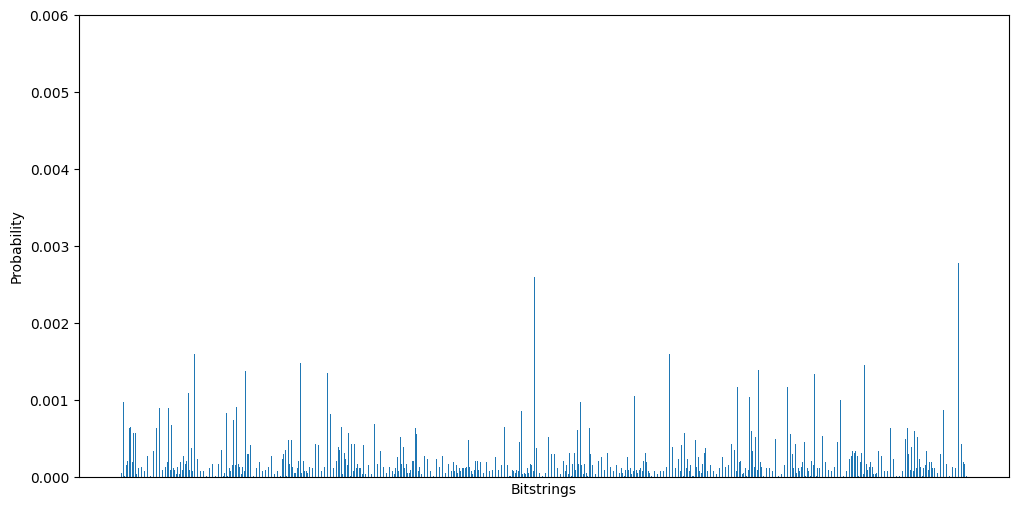

In [134]:
plot_histogram(ba2_12_def[0], keep_top=None, y_lim=0.006)

### FOM

In [135]:
ba2_12_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=2, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba2_12_fom[1], ba2_12_fom[2])

ecr Count: 94, Depth: 227


12.093339999999817 0.1710055624826163


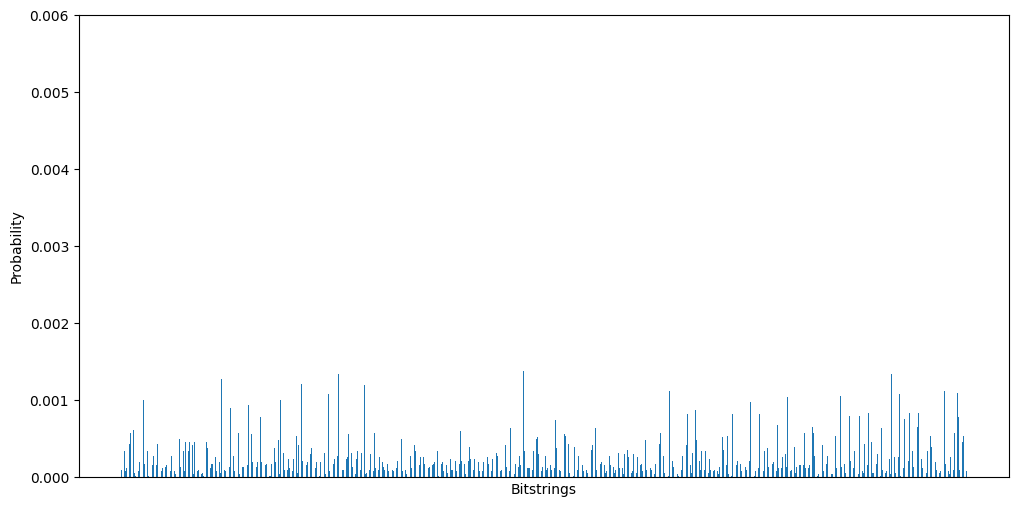

In [136]:
plot_histogram(ba2_12_fom[0], keep_top=None, y_lim=0.006)

### SAM2

In [137]:
ba2_12_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba2_12_sam2[1], ba2_12_sam2[2])

ecr Count: 103, Depth: 245


11.966939999999843 0.3662792683185505


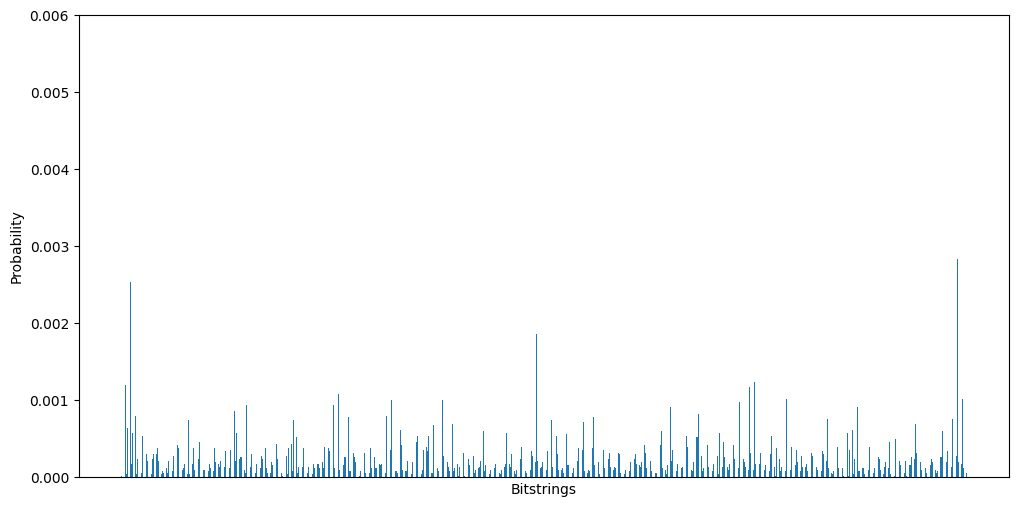

In [138]:
plot_histogram(ba2_12_sam2[0], keep_top=None, y_lim=0.006)

### SAM3

In [139]:
ba2_12_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba2_12_sam3[1], ba2_12_sam3[2])

ecr Count: 100, Depth: 277


12.221179999999814 0.11836111523637742


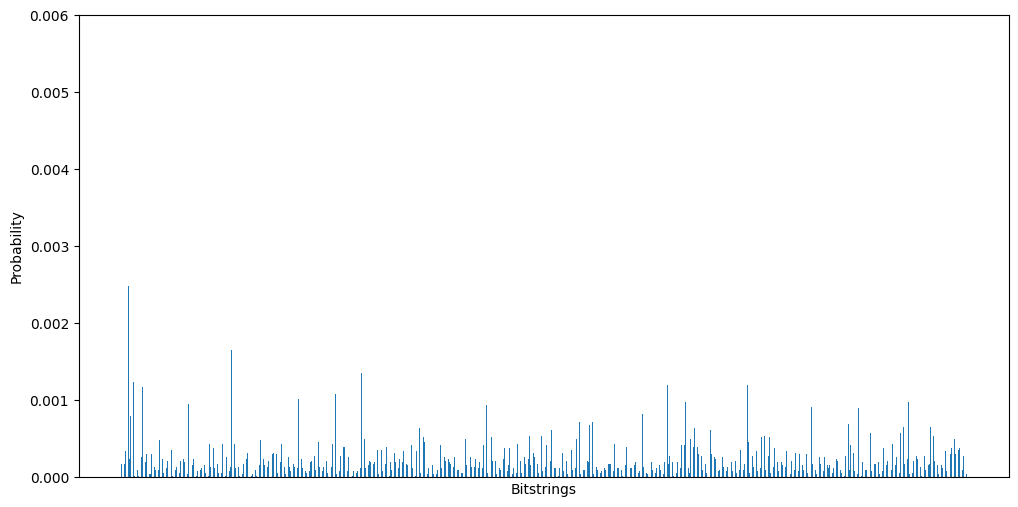

In [140]:
plot_histogram(ba2_12_sam3[0], keep_top=None, y_lim=0.006)

### SAM4

In [141]:
ba2_12_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba2_12_sam4[1], ba2_12_sam4[2])

ecr Count: 85, Depth: 229


12.172399999999787 0.11520770807545187


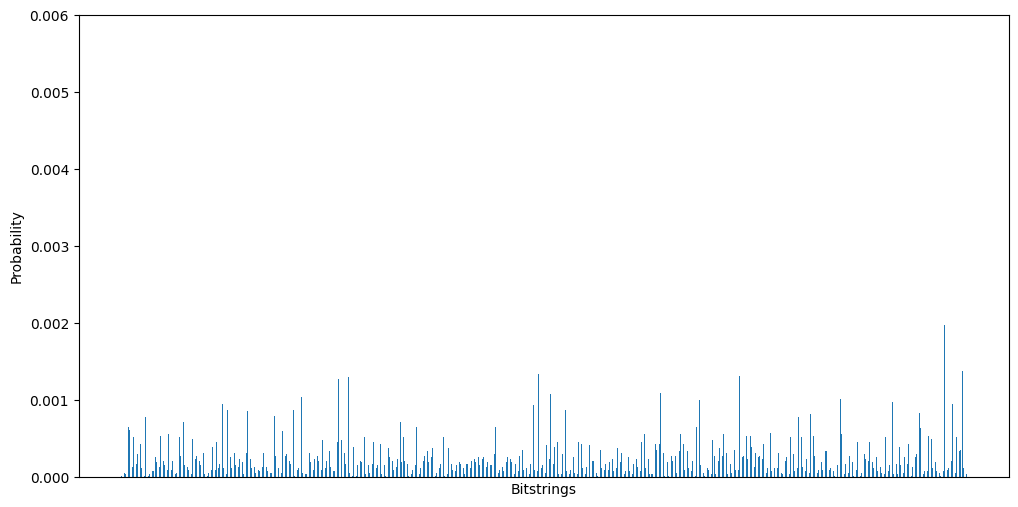

In [142]:
plot_histogram(ba2_12_sam4[0], keep_top=None, y_lim=0.006)

# **BA2 14**

In [143]:
ba2_14 = nx.barabasi_albert_graph(n=14, m=2, seed=0)
print('random cut size: ', 0.5 * ba2_14.number_of_edges())

random cut size:  12.0


### DEFAULT

In [144]:
ba2_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=2, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba2_14_def[1], ba2_14_def[2])

ecr Count: 105, Depth: 229


14.716520000000589 0.07334723989351913


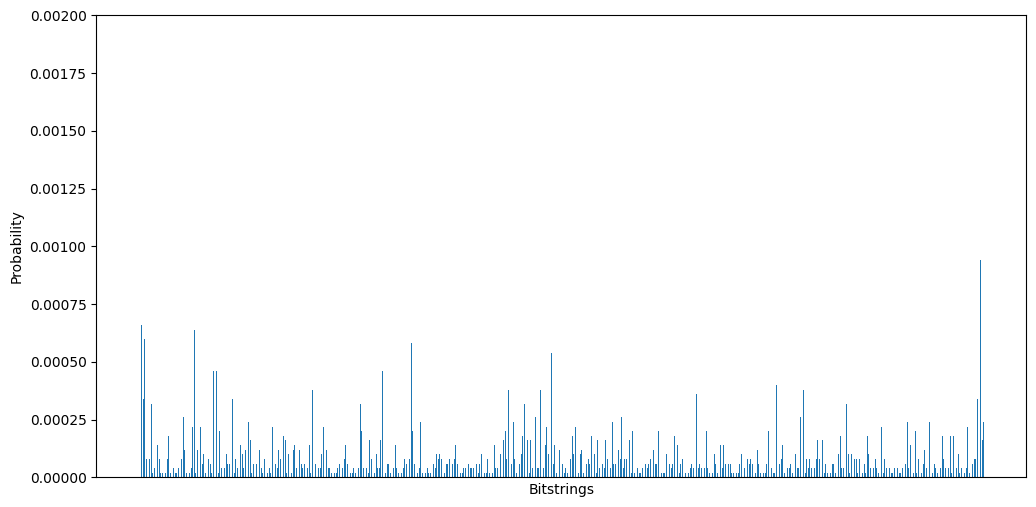

In [145]:
plot_histogram(ba2_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [146]:
ba2_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=2, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba2_14_fom[1], ba2_14_fom[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 113, Depth: 193


14.539480000000603 0.10692326968436237


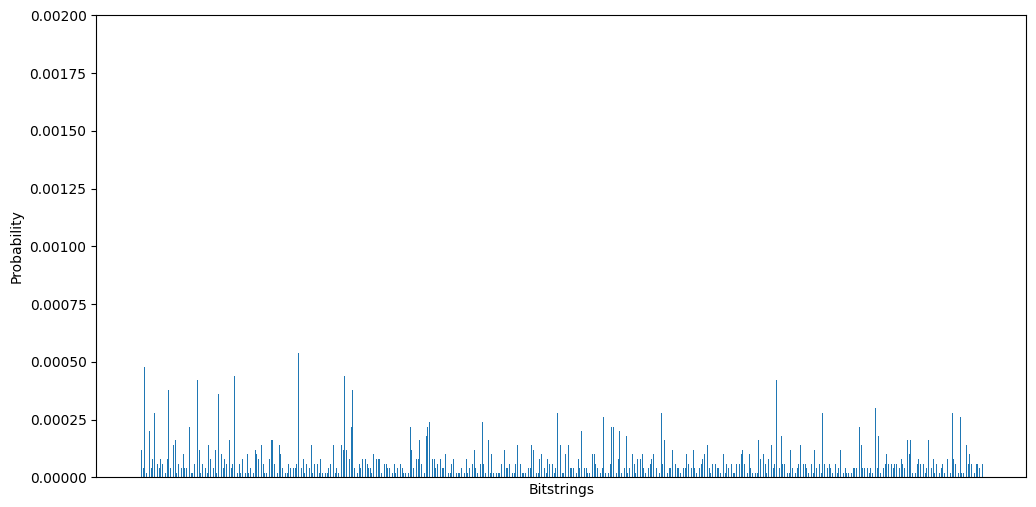

In [147]:
plot_histogram(ba2_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [148]:
ba2_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba2_14_sam2[1], ba2_14_sam2[2])

ecr Count: 116, Depth: 189


14.569440000000606 0.019970938886297047


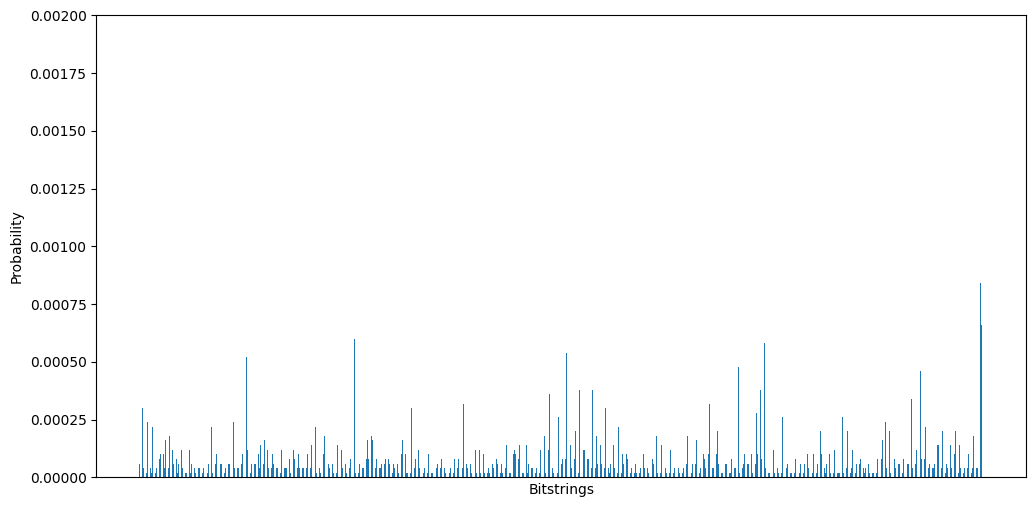

In [149]:
plot_histogram(ba2_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

In [150]:
ba2_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba2_14_sam3[1], ba2_14_sam3[2])

ecr Count: 116, Depth: 192


14.562040000000616 0.0379743913710449


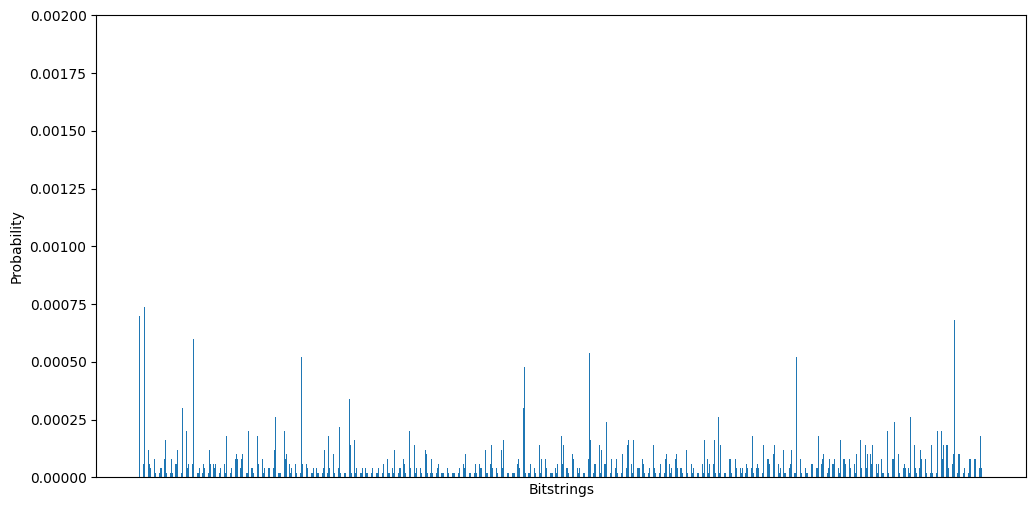

In [151]:
plot_histogram(ba2_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [152]:
ba2_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=2, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba2_14_sam4[1], ba2_14_sam4[2])

ecr Count: 107, Depth: 298


14.564520000000602 0.08947738038187886


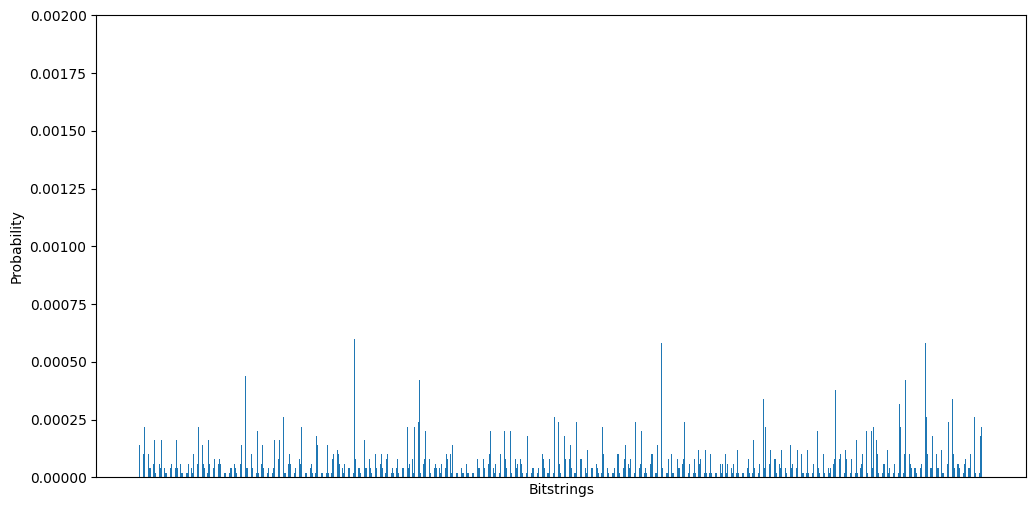

In [153]:
plot_histogram(ba2_14_sam4[0], keep_top=None, y_lim=0.002)

--------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------

# **BA3 10**

In [154]:
ba3_10 = nx.barabasi_albert_graph(n=10, m=3, seed=0)
print('random cut size: ', 0.5 * ba3_10.number_of_edges())

random cut size:  10.5


### DEFAULT

In [155]:
ba3_10_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=3, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba3_10_def[1], ba3_10_def[2])

ecr Count: 89, Depth: 209


13.473620000000007 0.5145101102990914


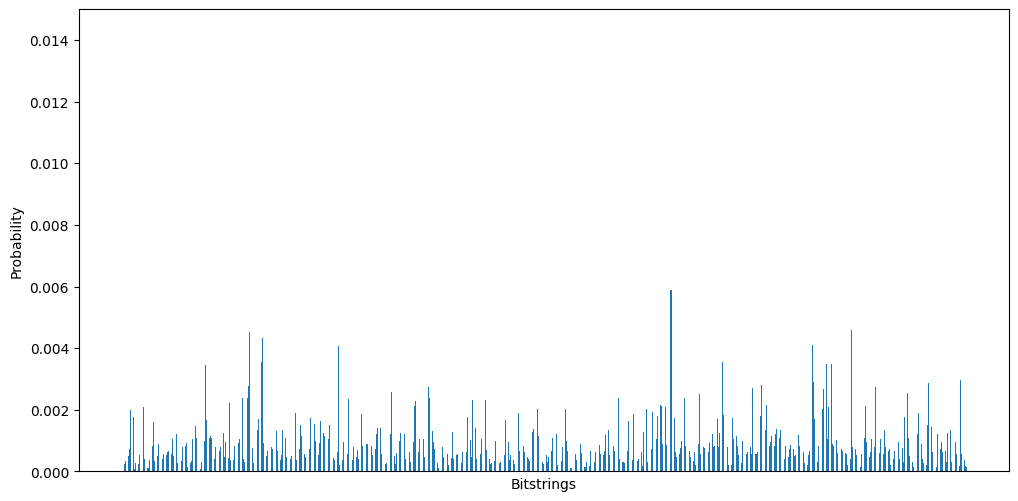

In [156]:
plot_histogram(ba3_10_def[0], keep_top=None, y_lim=0.015)

### FOM

In [157]:
ba3_10_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba3_10_fom[1], ba3_10_fom[2])

ecr Count: 97, Depth: 209


12.96232 0.773498895668243


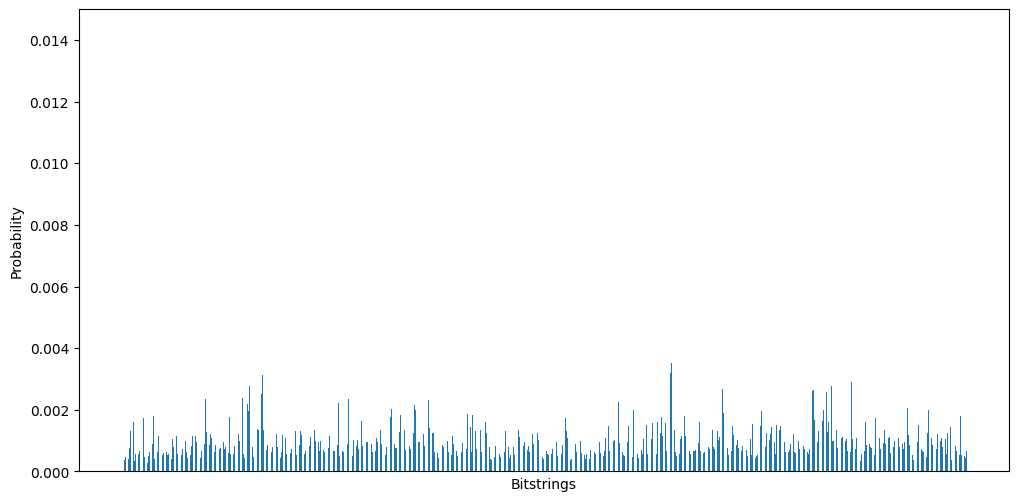

In [158]:
plot_histogram(ba3_10_fom[0], keep_top=None, y_lim=0.015)

### SAM2

In [159]:
ba3_10_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba3_10_sam2[1], ba3_10_sam2[2])

ecr Count: 103, Depth: 248


13.301540000000003 0.445514343652362


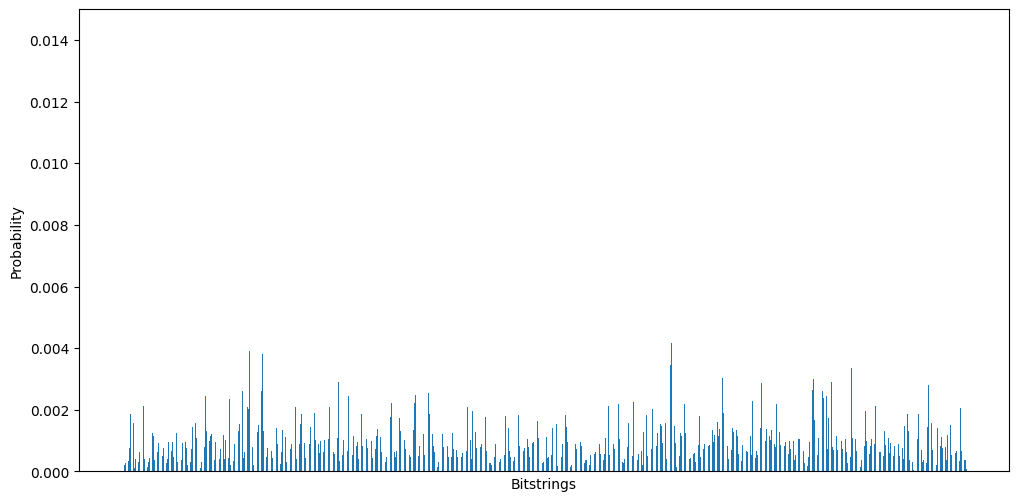

In [160]:
plot_histogram(ba3_10_sam2[0], keep_top=None, y_lim=0.015)

### SAM3

In [161]:
ba3_10_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba3_10_sam3[1], ba3_10_sam3[2])

ecr Count: 99, Depth: 228


12.895139999999998 0.7359743571619886


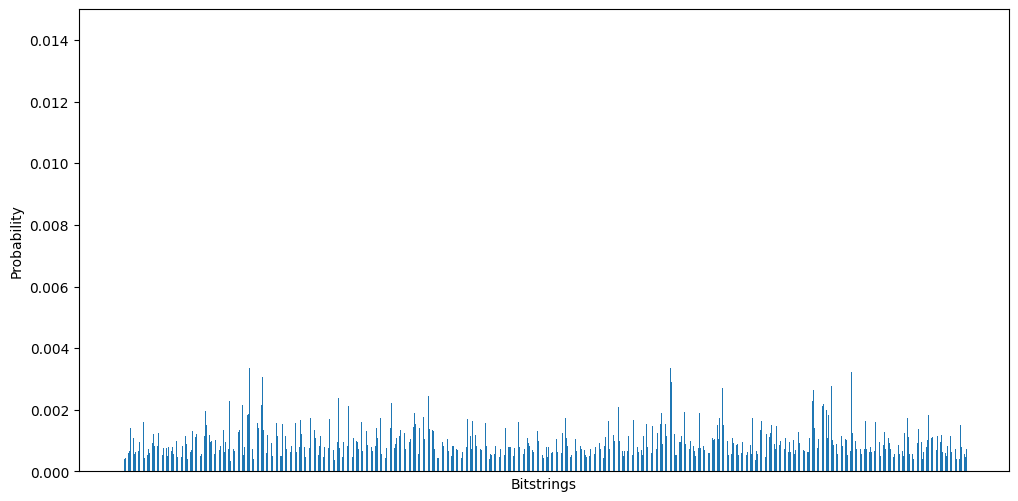

In [162]:
plot_histogram(ba3_10_sam3[0], keep_top=None, y_lim=0.015)

### SAM4

In [163]:
ba3_10_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba3_10_sam4[1], ba3_10_sam4[2])

ecr Count: 85, Depth: 196


13.13006 0.5503662402437179


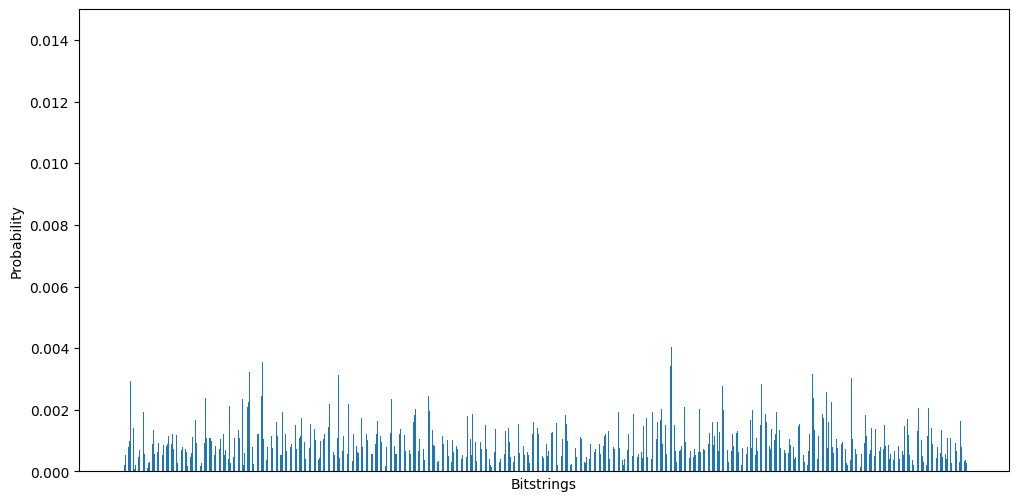

In [164]:
plot_histogram(ba3_10_sam4[0], keep_top=None, y_lim=0.015)

# **BA3 12**

In [165]:
ba3_12 = nx.barabasi_albert_graph(n=12, m=3, seed=0)
print('random cut size: ', 0.5 * ba3_12.number_of_edges())

random cut size:  13.5


### DEFAULT

In [166]:
ba3_12_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=3, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba3_12_def[1], ba3_12_def[2])

ecr Count: 120, Depth: 221


17.07955999999998 0.13979598849751057


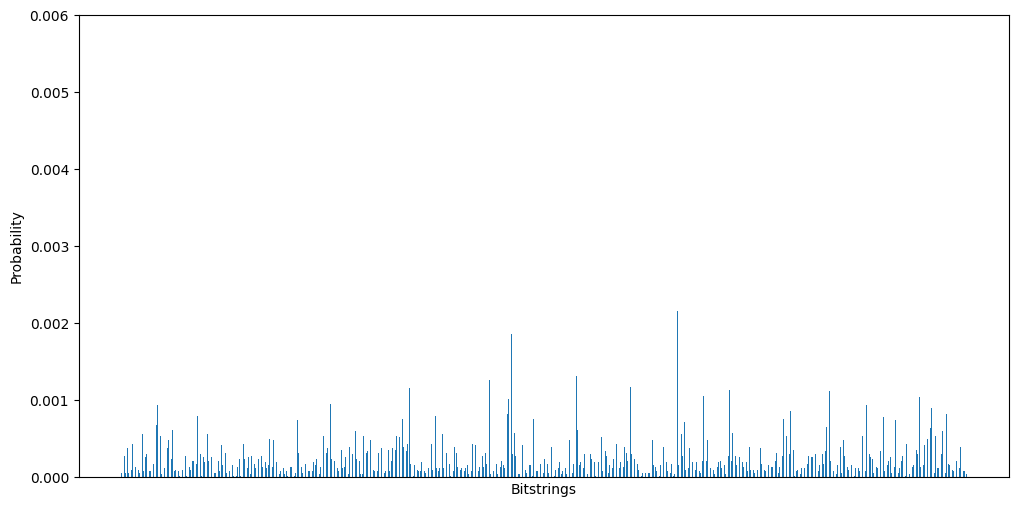

In [167]:
plot_histogram(ba3_12_def[0], keep_top=None, y_lim=0.006)

### FOM

In [168]:
ba3_12_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba3_12_fom[1], ba3_12_fom[2])

ecr Count: 132, Depth: 317


16.685879999999976 0.1397121669719724


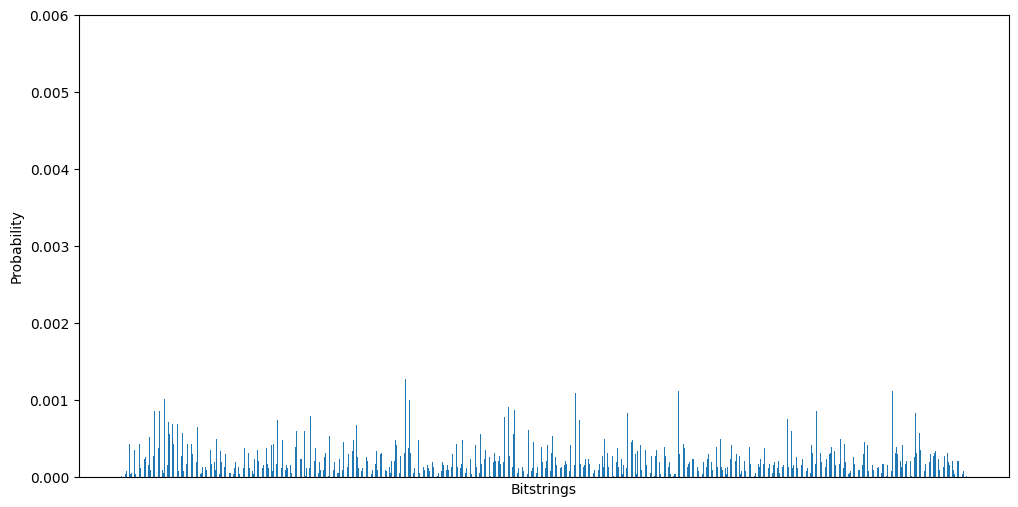

In [169]:
plot_histogram(ba3_12_fom[0], keep_top=None, y_lim=0.006)

### SAM2

In [170]:
ba3_12_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba3_12_sam2[1], ba3_12_sam2[2])

ecr Count: 127, Depth: 278


16.926859999999987 0.0493584278517946


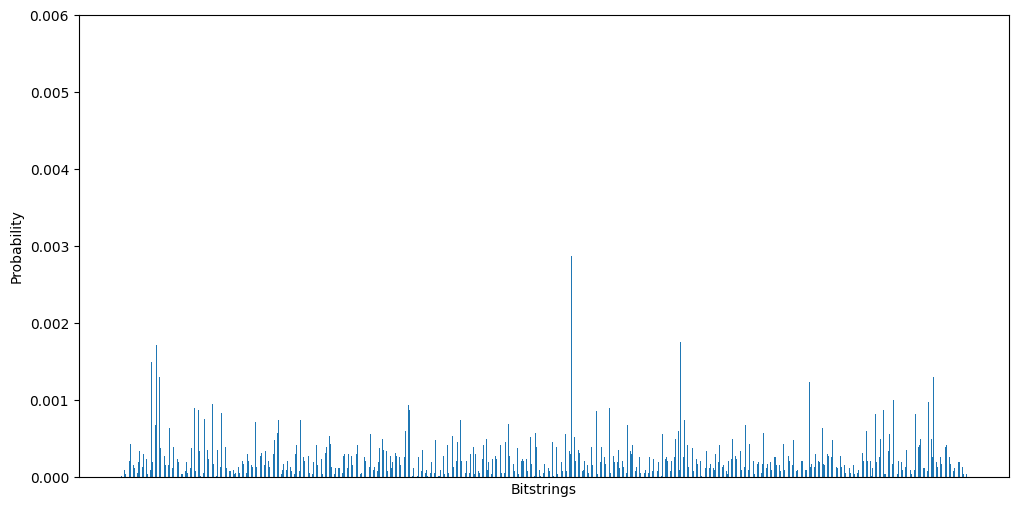

In [171]:
plot_histogram(ba3_12_sam2[0], keep_top=None, y_lim=0.006)

### SAM3

In [172]:
ba3_12_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba3_12_sam3[1], ba3_12_sam3[2])

ecr Count: 124, Depth: 250


15.681359999999898 0.8711219285496807


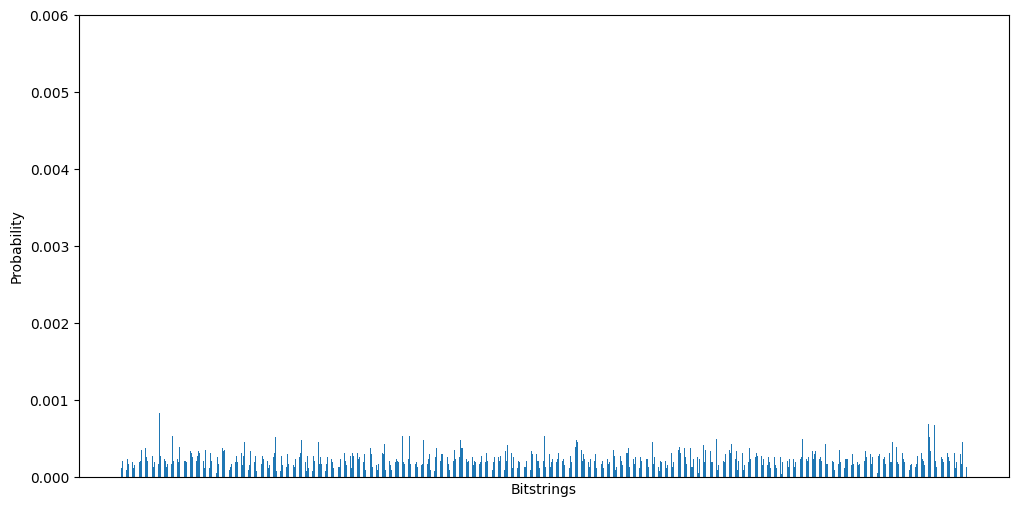

In [173]:
plot_histogram(ba3_12_sam3[0], keep_top=None, y_lim=0.006)

### SAM4

In [174]:
ba3_12_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba3_12_sam4[1], ba3_12_sam4[2])

ecr Count: 130, Depth: 322


16.572079999999964 0.5382416200927472


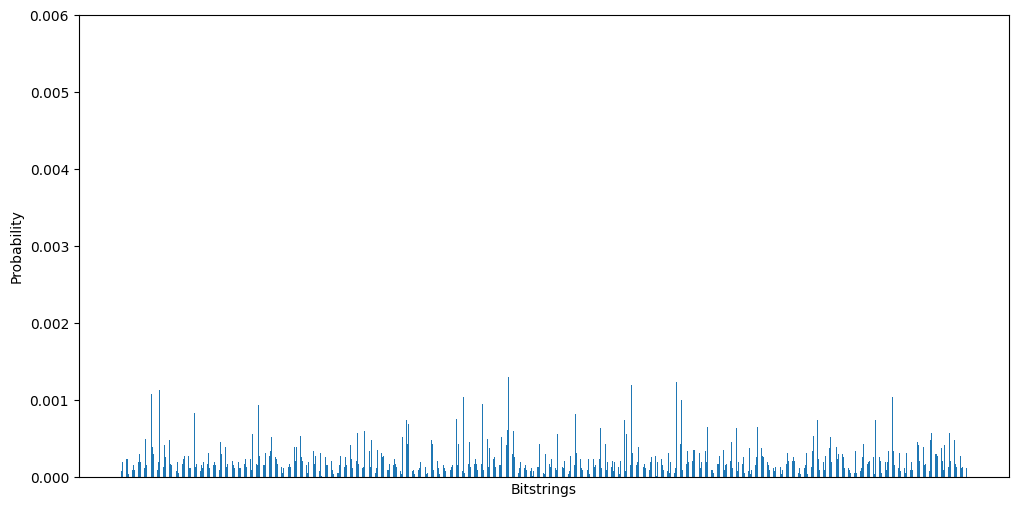

In [175]:
plot_histogram(ba3_12_sam4[0], keep_top=None, y_lim=0.006)

# **BA3 14**

In [176]:
ba3_14 = nx.barabasi_albert_graph(n=14, m=3, seed=0)
print('random cut size: ', 0.5 * ba3_14.number_of_edges())

random cut size:  16.5


### DEFAULT

In [177]:
ba3_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=3, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba3_14_def[1], ba3_14_def[2])

ecr Count: 156, Depth: 284


19.206539999998913 1.086590348935448


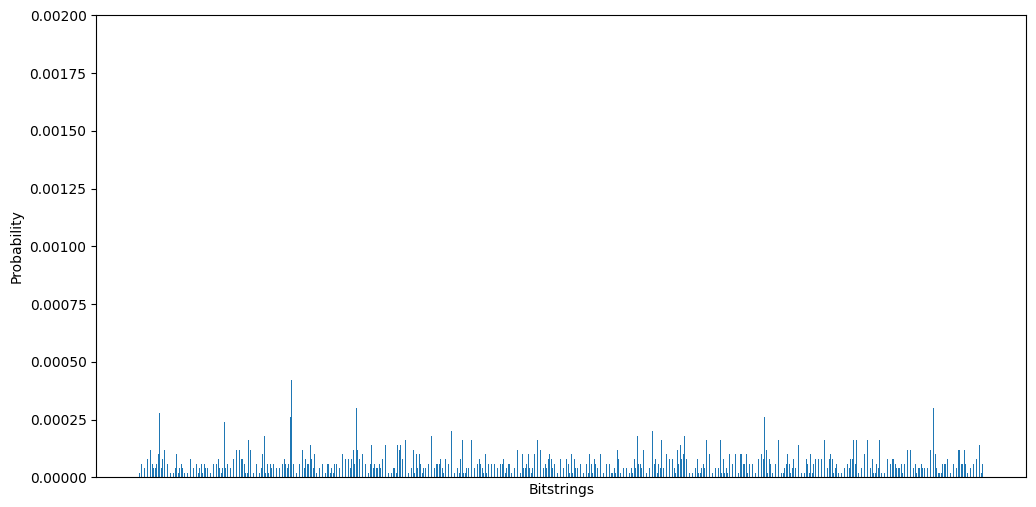

In [178]:
plot_histogram(ba3_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [179]:
ba3_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba3_14_fom[1], ba3_14_fom[2])

ecr Count: 171, Depth: 369


19.763379999998843 0.6514190583640505


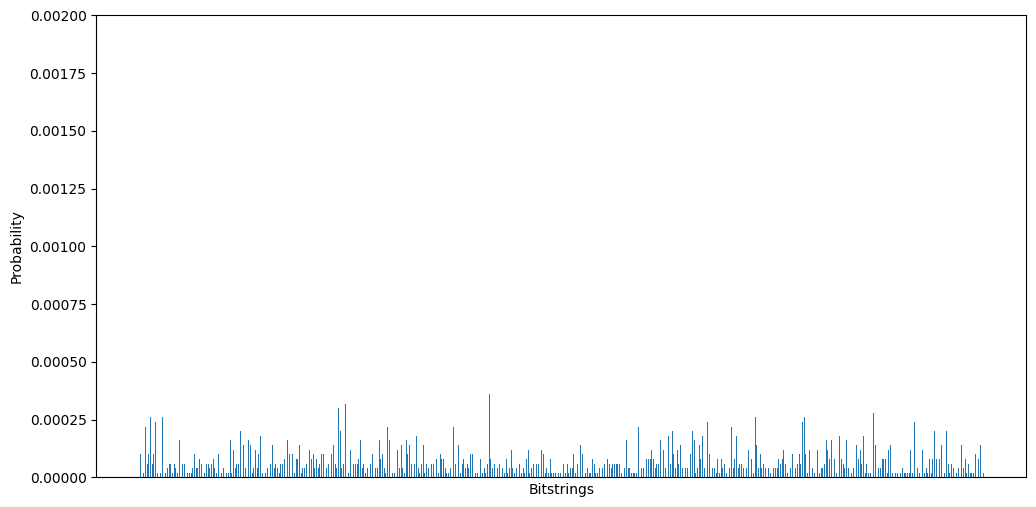

In [180]:
plot_histogram(ba3_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [181]:
ba3_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba3_14_sam2[1], ba3_14_sam2[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 179, Depth: 367


20.09951999999879 0.06415713210546486


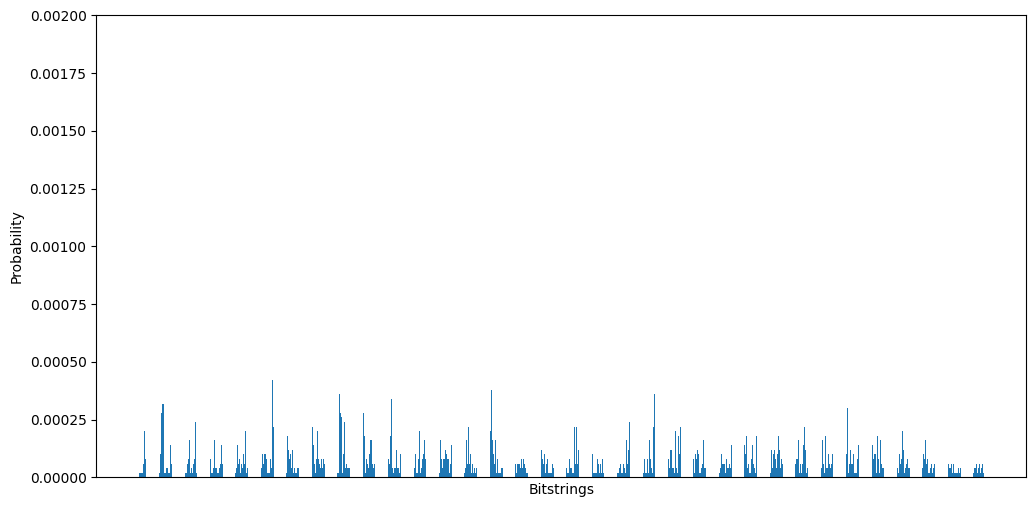

In [182]:
plot_histogram(ba3_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

In [183]:
ba3_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba3_14_sam3[1], ba3_14_sam3[2])

ecr Count: 162, Depth: 306


19.819779999998815 0.7833199841698034


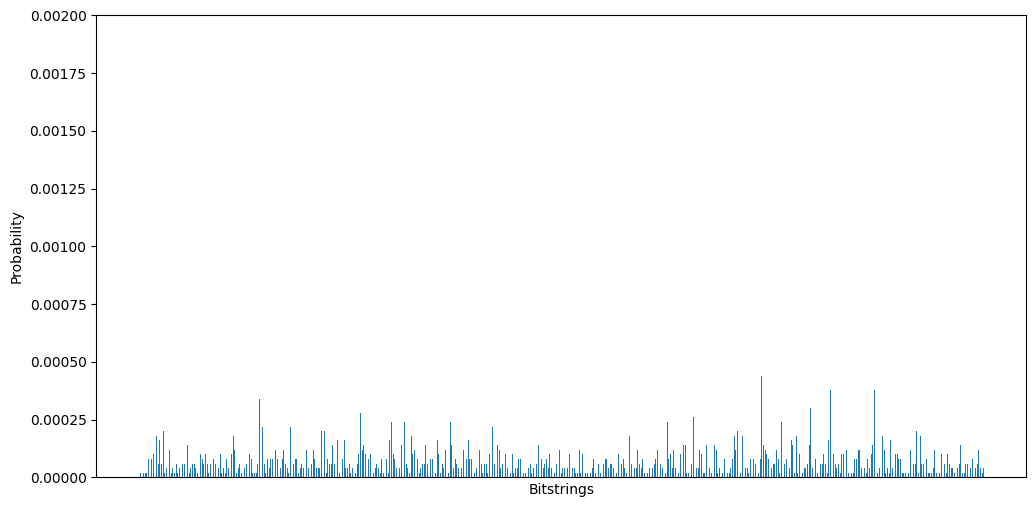

In [184]:
plot_histogram(ba3_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [185]:
ba3_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=3, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba3_14_sam4[1], ba3_14_sam4[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 185, Depth: 387


20.004459999998804 0.08892906386551643


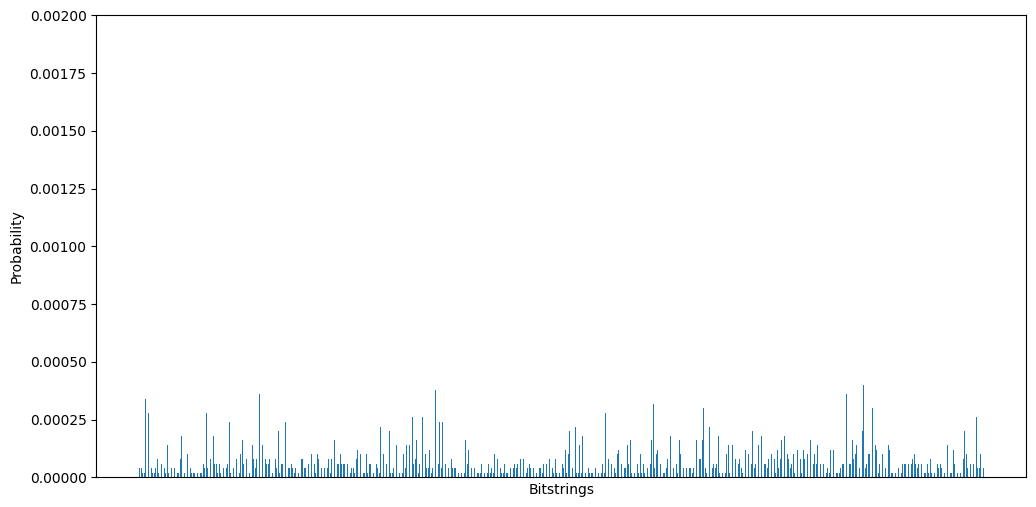

In [186]:
plot_histogram(ba3_14_sam4[0], keep_top=None, y_lim=0.002)

---------------------------------------------------------------------------------------------
---------------------------------------------------------------------------------------------

# **BA4 10**

In [187]:
ba4_10 = nx.barabasi_albert_graph(n=10, m=4, seed=0)
print('random cut size: ', 0.5 * ba4_10.number_of_edges())

random cut size:  12.0


### DEFAULT

In [188]:
ba4_10_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=4, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba4_10_def[1], ba4_10_def[2])

ecr Count: 117, Depth: 248


16.199820000000066 0.6122658814600381


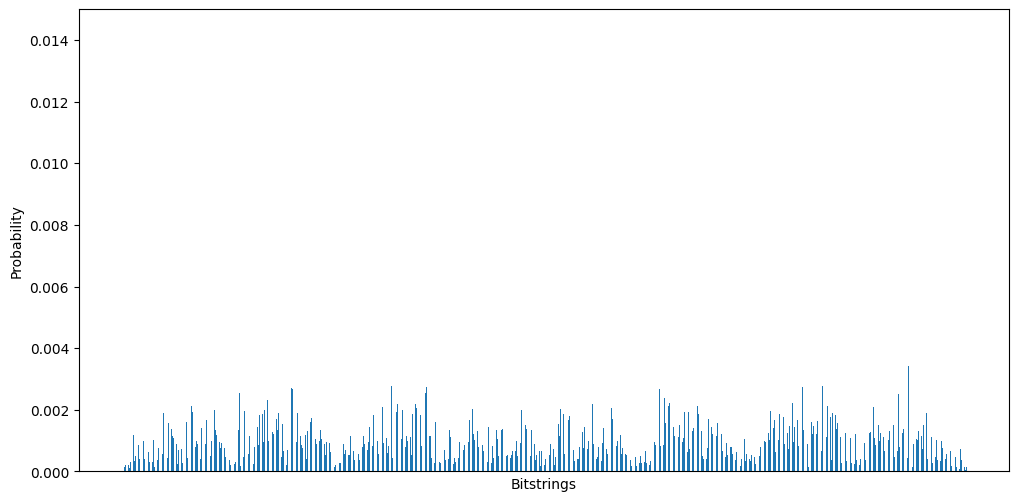

In [189]:
plot_histogram(ba4_10_def[0], keep_top=None, y_lim=0.015)

### FOM

In [190]:
ba4_10_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=4,
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba4_10_fom[1], ba4_10_fom[2])

ecr Count: 121, Depth: 295


16.046460000000057 0.5152457999828963


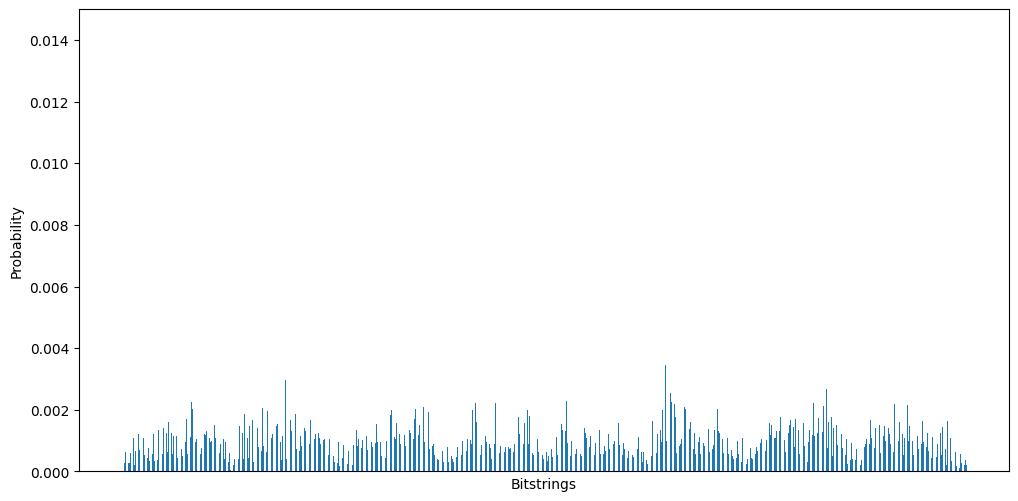

In [191]:
plot_histogram(ba4_10_fom[0], keep_top=None, y_lim=0.015)

### SAM2

In [192]:
ba4_10_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba4_10_sam2[1], ba4_10_sam2[2])

ecr Count: 129, Depth: 290


15.804180000000065 0.6672211549404123


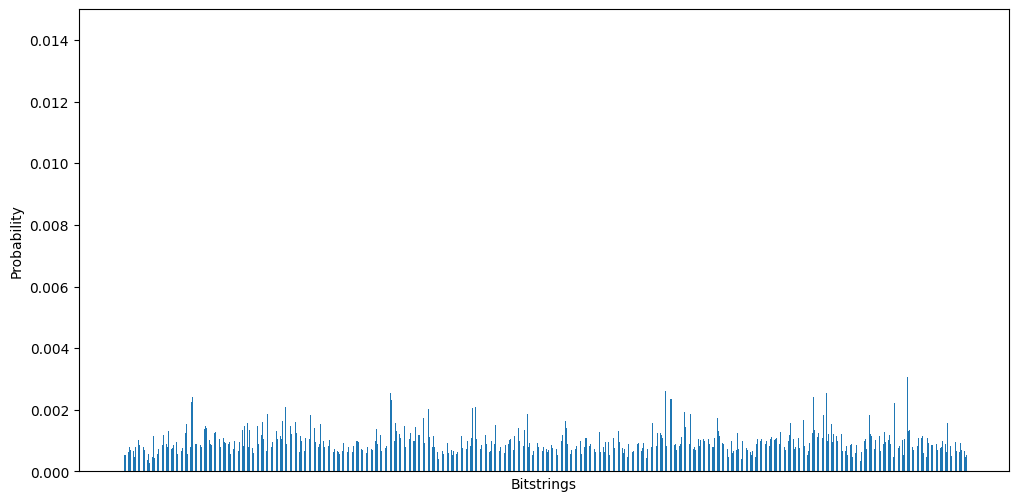

In [193]:
plot_histogram(ba4_10_sam2[0], keep_top=None, y_lim=0.015)

### SAM3

In [194]:
ba4_10_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba4_10_sam3[1], ba4_10_sam3[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 120, Depth: 301


15.496620000000041 0.5267921464866574


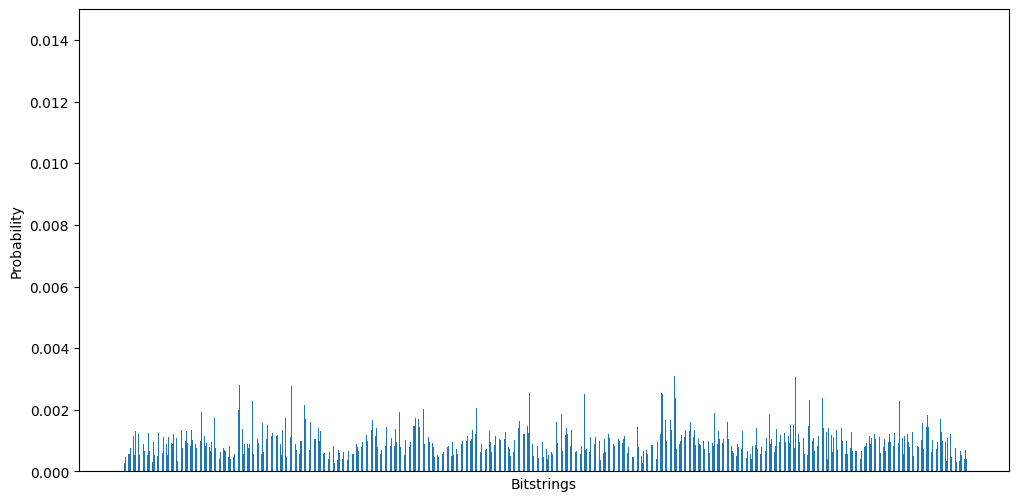

In [195]:
plot_histogram(ba4_10_sam3[0], keep_top=None, y_lim=0.015)

### SAM4

In [196]:
ba4_10_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=10, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba4_10_sam4[1], ba4_10_sam4[2])

ecr Count: 117, Depth: 301


15.963580000000075 0.6637955691325691


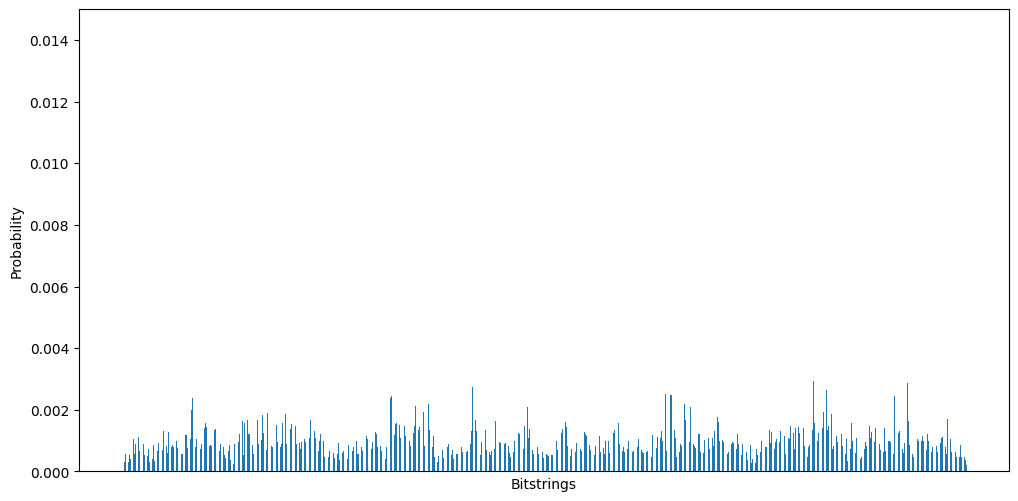

In [197]:
plot_histogram(ba4_10_sam4[0], keep_top=None, y_lim=0.015)

# **BA4 12**

In [198]:
ba4_12 = nx.barabasi_albert_graph(n=12, m=4, seed=0)
print('random cut size: ', 0.5 * ba4_12.number_of_edges())

random cut size:  16.0


### DEFAULT

In [199]:
ba4_12_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=4, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba4_12_def[1], ba4_12_def[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 152, Depth: 345


20.00207999999959 0.5251172074879824


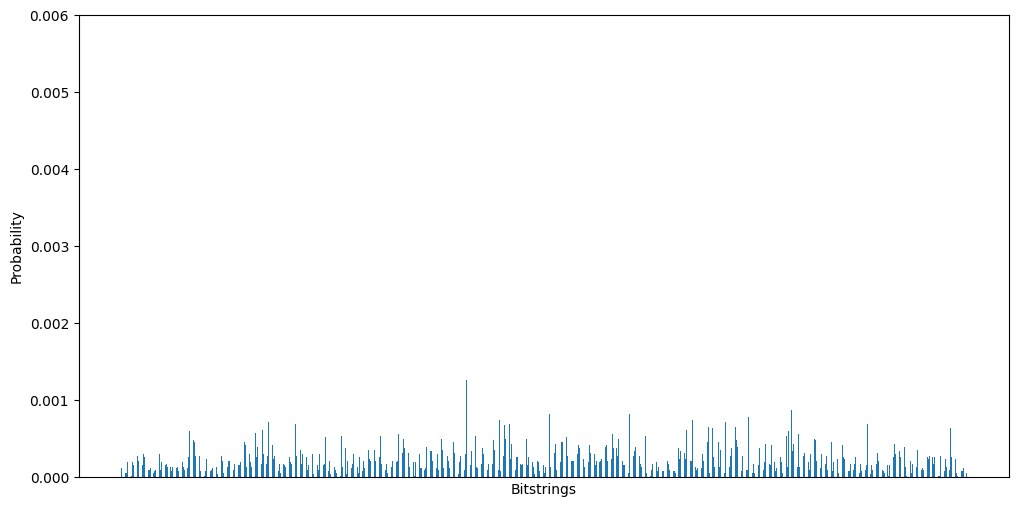

In [200]:
plot_histogram(ba4_12_def[0], keep_top=None, y_lim=0.006)

### FOM

In [201]:
ba4_12_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba4_12_fom[1], ba4_12_fom[2])

ecr Count: 178, Depth: 306


20.023899999999554 0.6747299963689002


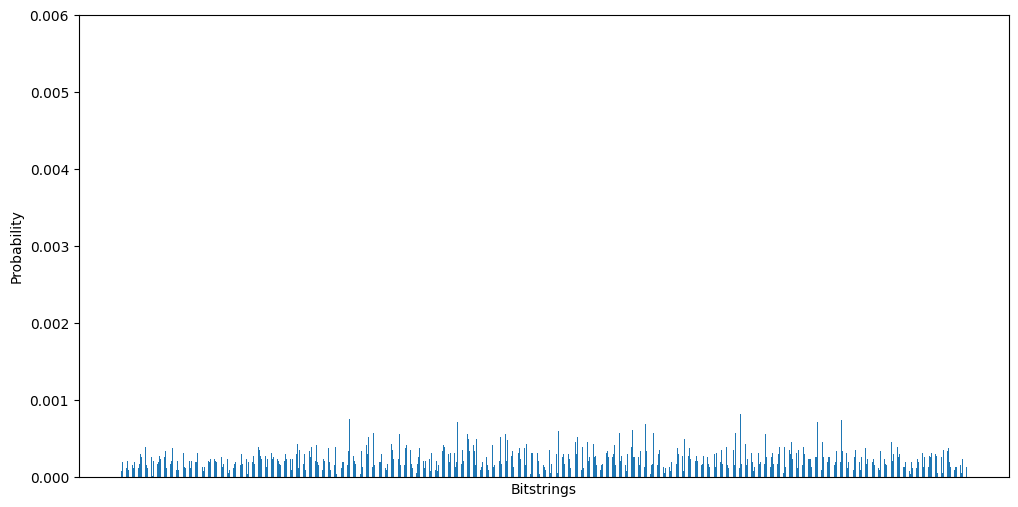

In [202]:
plot_histogram(ba4_12_fom[0], keep_top=None, y_lim=0.006)

### SAM2

In [203]:
ba4_12_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba4_12_sam2[1], ba4_12_sam2[2])

ecr Count: 186, Depth: 403


19.65455999999958 0.6330158247626689


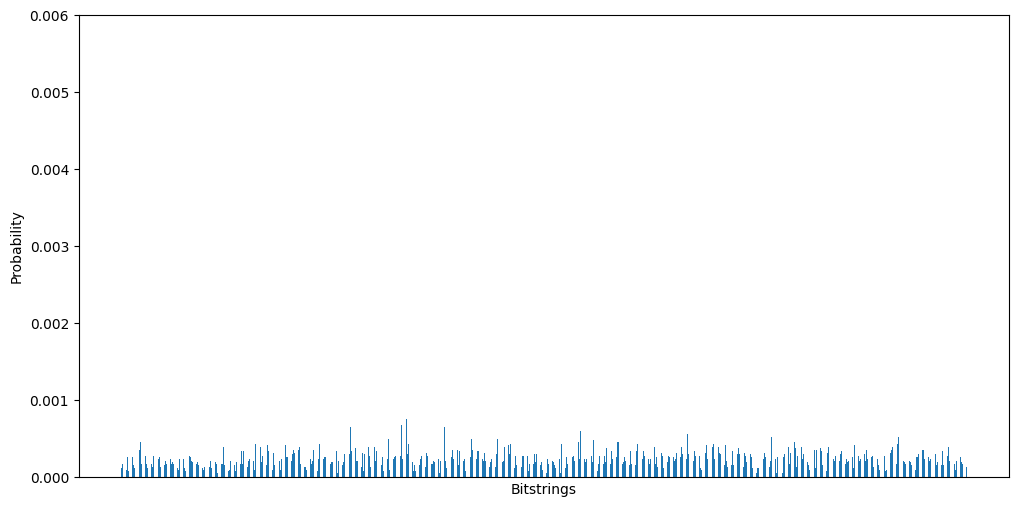

In [204]:
plot_histogram(ba4_12_sam2[0], keep_top=None, y_lim=0.006)

### SAM3

In [205]:
ba4_12_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba4_12_sam3[1], ba4_12_sam3[2])

ecr Count: 172, Depth: 329


20.05209999999959 0.6525285556969166


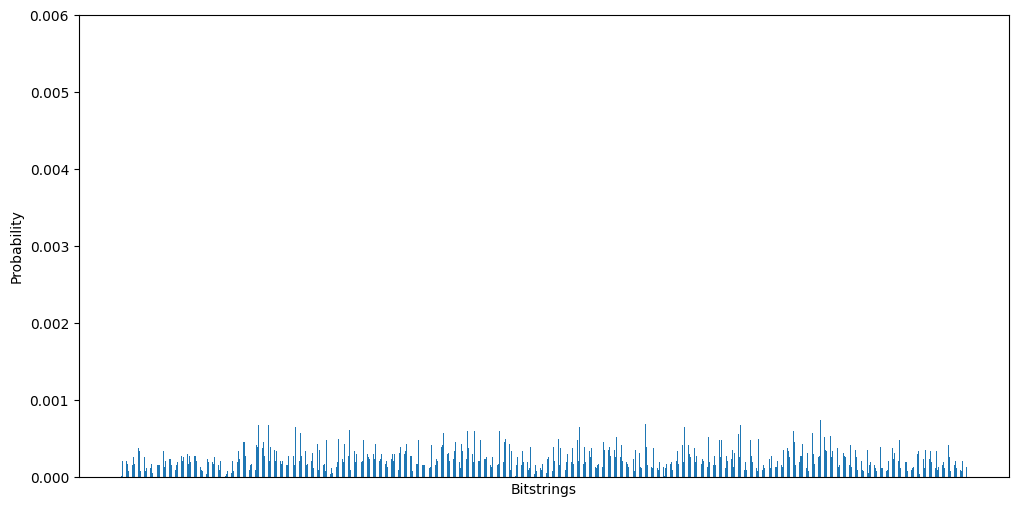

In [206]:
plot_histogram(ba4_12_sam3[0], keep_top=None, y_lim=0.006)

### SAM4

In [207]:
ba4_12_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=12, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba4_12_sam4[1], ba4_12_sam4[2])

ecr Count: 163, Depth: 354


20.40249999999956 0.5282149373124093


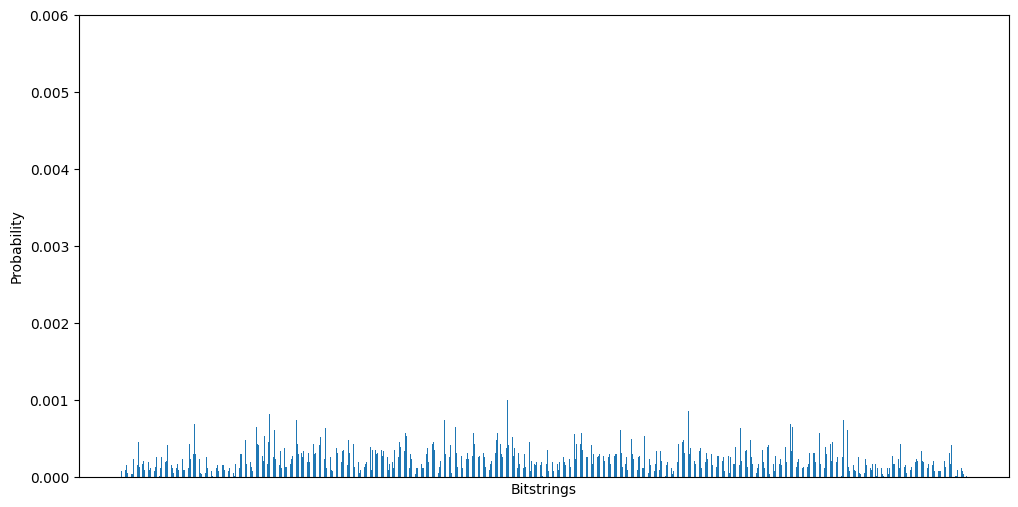

In [208]:
plot_histogram(ba4_12_sam4[0], keep_top=None, y_lim=0.006)

# **BA4 14**

In [209]:
ba4_14 = nx.barabasi_albert_graph(n=14, m=4, seed=0)
print('random cut size: ', 0.5 * ba4_14.number_of_edges())

random cut size:  20.0


### DEFAULT

In [211]:
ba4_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=4, 
                            default=True, 
                            gate='ecr', 
                            average_over=5)
print(ba4_14_def[1], ba4_14_def[2])

ecr Count: 208, Depth: 397


23.754860000000967 0.8028419286511717


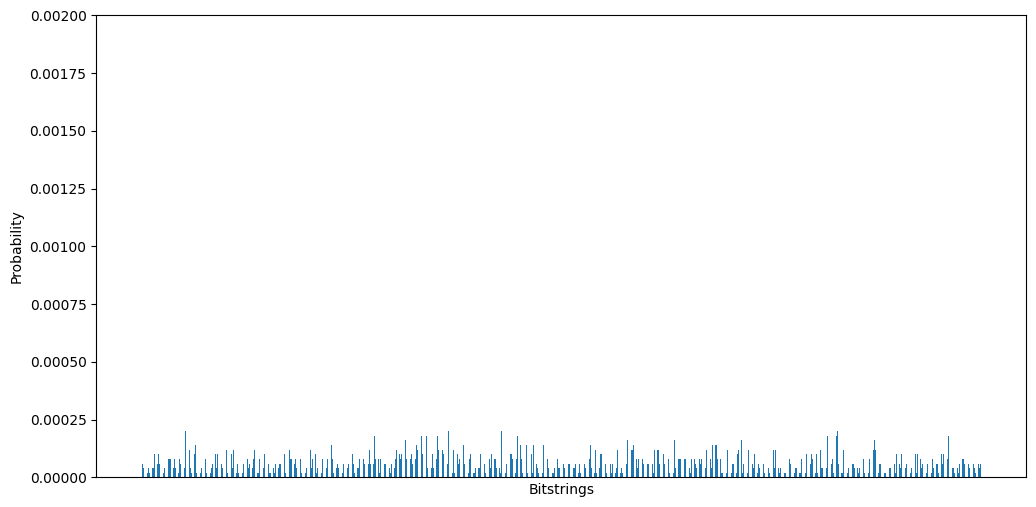

In [212]:
plot_histogram(ba4_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [213]:
ba4_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='1D',
                            gate='ecr', 
                            average_over=5)
print(ba4_14_fom[1], ba4_14_fom[2])

Finding best circuit:   0%|          | 0/100 [00:00<?, ?it/s]

ecr Count: 235, Depth: 407


KeyboardInterrupt: 

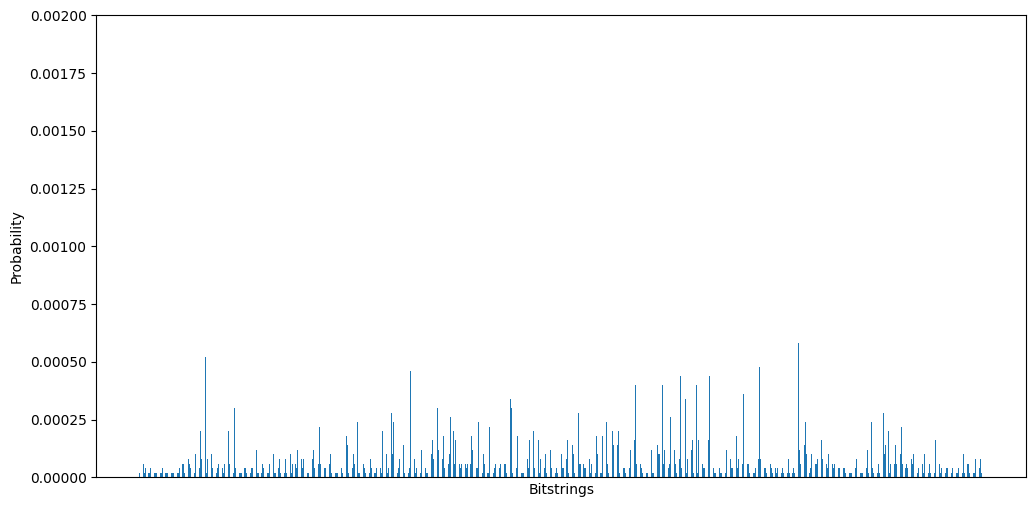

In [ ]:
plot_histogram(ba4_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [ ]:
ba4_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='ecr', 
                            average_over=5)
print(ba4_14_sam2[1], ba4_14_sam2[2])

ecr Count: 100, Depth: 132


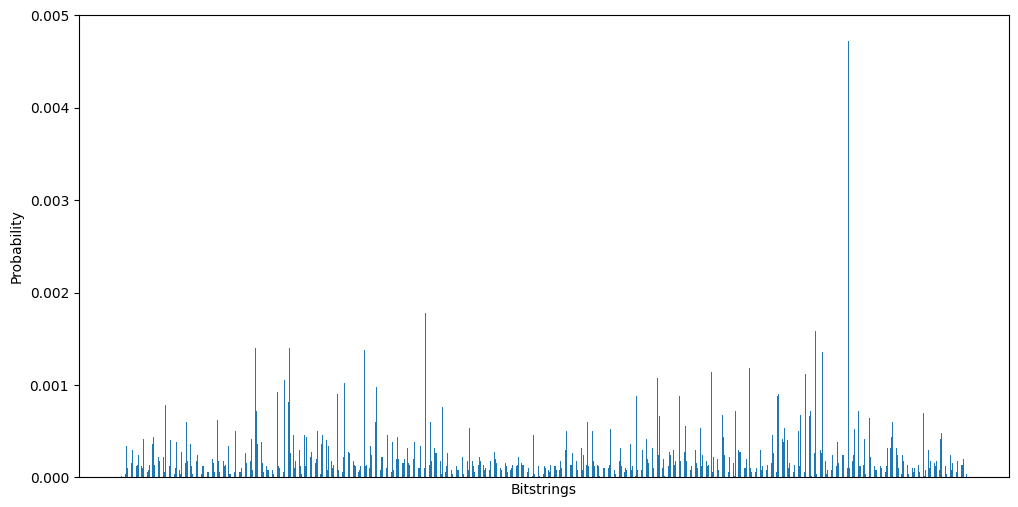

In [ ]:
plot_histogram(ba4_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

ecr Count: 88, Depth: 153


10.837119999999894 0.9228432920057211


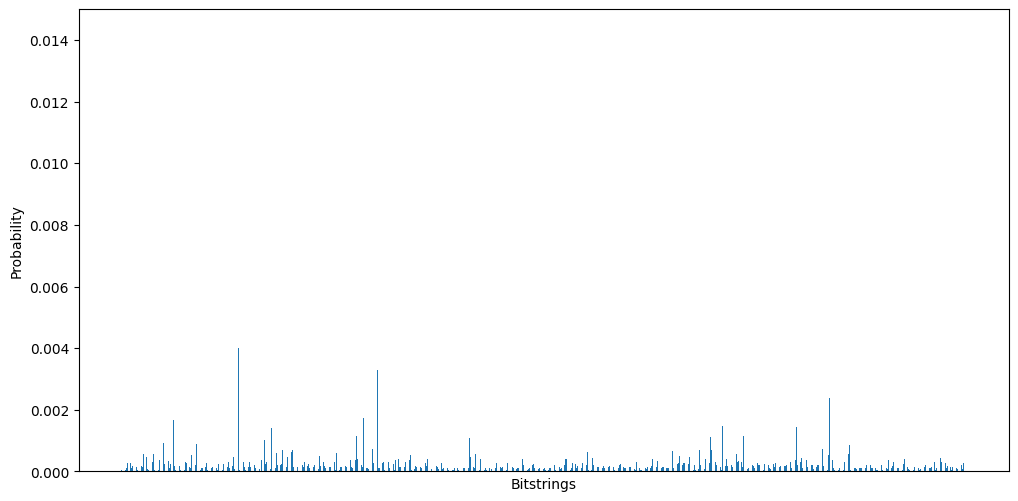

In [ ]:
ba4_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='ecr', 
                            average_over=5)
print(ba4_14_sam3[1], ba4_14_sam3[2])

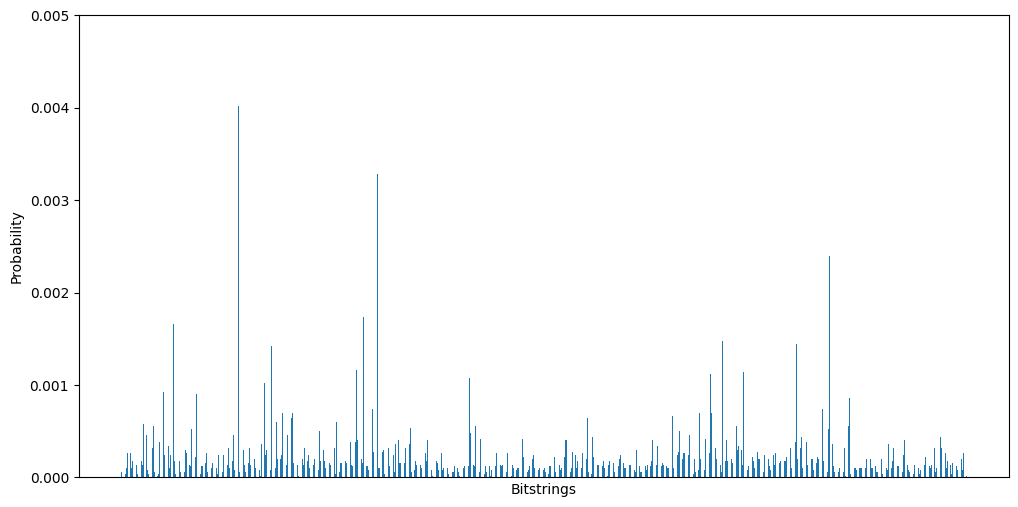

In [ ]:
plot_histogram(ba4_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [ ]:
ba4_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='ba', 
                            num_nodes=14, 
                            param=4, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='ecr', 
                            average_over=5)
print(ba4_14_sam4[1], ba4_14_sam4[2])

ecr Count: 81, Depth: 134


In [ ]:
plot_histogram(ba4_14_sam4[0], keep_top=None, y_lim=0.002)

In [215]:
backend=FakeFez()

# **RR5 14**

In [216]:
rr5_14 = nx.random_regular_graph(n=14, d=5, seed=0)
print('random cut size: ', 0.5 * rr5_14.number_of_edges())

random cut size:  17.5


### DEFAULT

In [217]:
rr5_14_def = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=True, 
                            gate='cz', 
                            average_over=1)
print(rr5_14_def[1], rr5_14_def[2])

cz Count: 183, Depth: 300


21.064199999998714 0.0


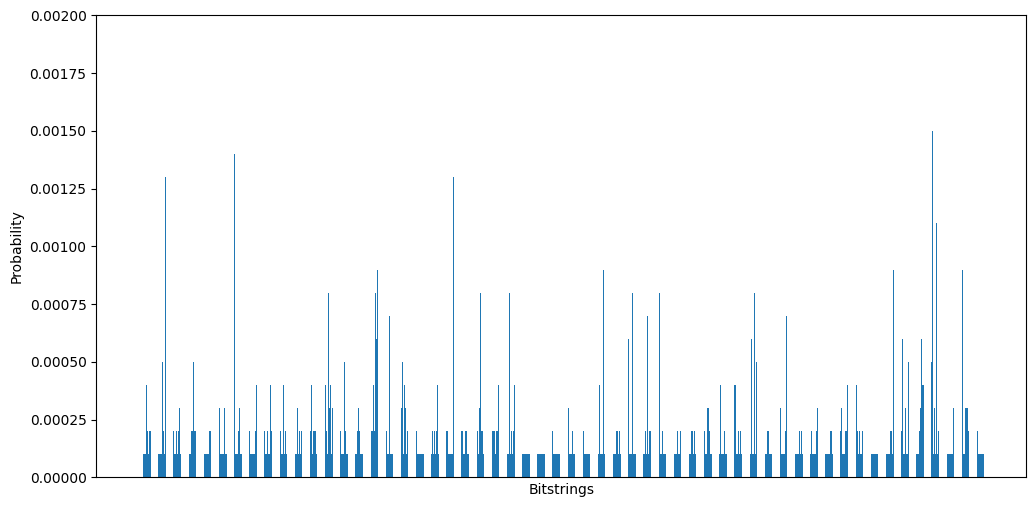

In [218]:
plot_histogram(rr5_14_def[0], keep_top=None, y_lim=0.002)

### FOM

In [219]:
rr5_14_fom = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='1D',
                            gate='cz', 
                            average_over=1)
print(rr5_14_fom[1], rr5_14_fom[2])

cz Count: 201, Depth: 228


17.57939999999921 0.0


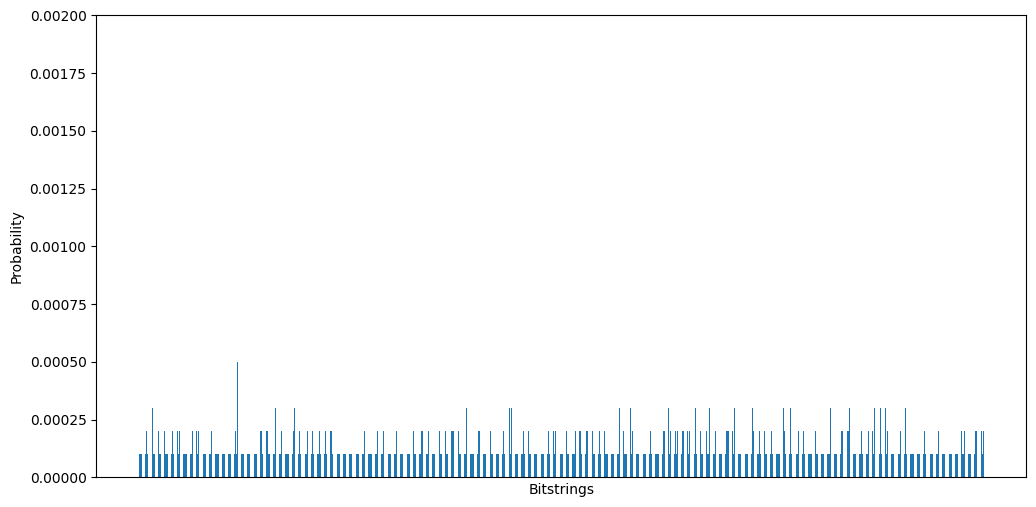

In [220]:
plot_histogram(rr5_14_fom[0], keep_top=None, y_lim=0.002)

### SAM2

In [221]:
rr5_14_sam2 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=2,
                            gate='cz', 
                            average_over=1)
print(rr5_14_sam2[1], rr5_14_sam2[2])

cz Count: 177, Depth: 201


17.45239999999915 0.0


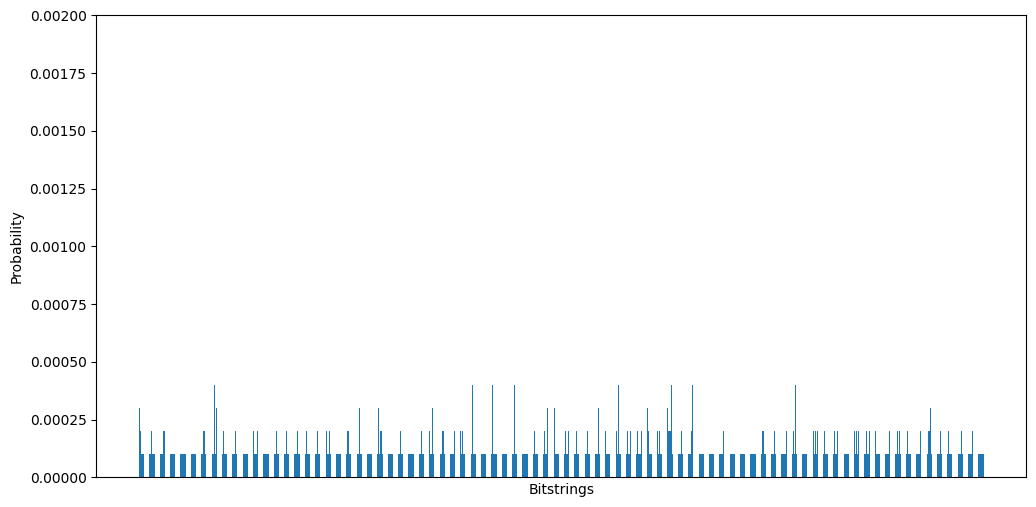

In [222]:
plot_histogram(rr5_14_sam2[0], keep_top=None, y_lim=0.002)

### SAM3

In [223]:
rr5_14_sam3 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=3,
                            gate='cz', 
                            average_over=1)
print(rr5_14_sam3[1], rr5_14_sam3[2])

cz Count: 175, Depth: 245


18.515899999999096 0.0


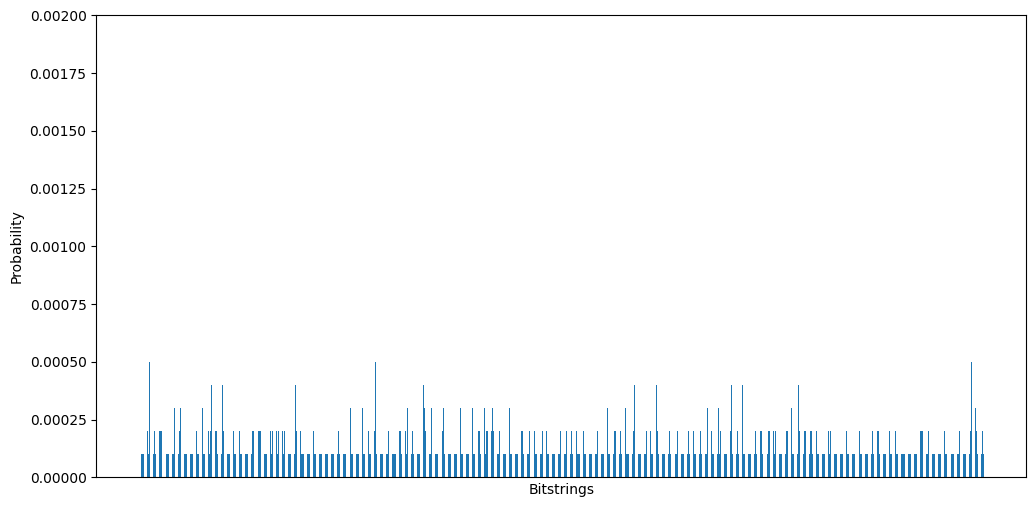

In [224]:
plot_histogram(rr5_14_sam3[0], keep_top=None, y_lim=0.002)

### SAM4

In [225]:
rr5_14_sam4 = maxcut_results(sim=backend, 
                            backend=backend, 
                            graph_type='reg', 
                            num_nodes=14, 
                            param=5, 
                            default=False,
                            tech='2D',
                            k=4,
                            gate='cz', 
                            average_over=1)
print(rr5_14_sam4[1], rr5_14_sam4[2])

cz Count: 176, Depth: 259


18.348099999999008 0.0


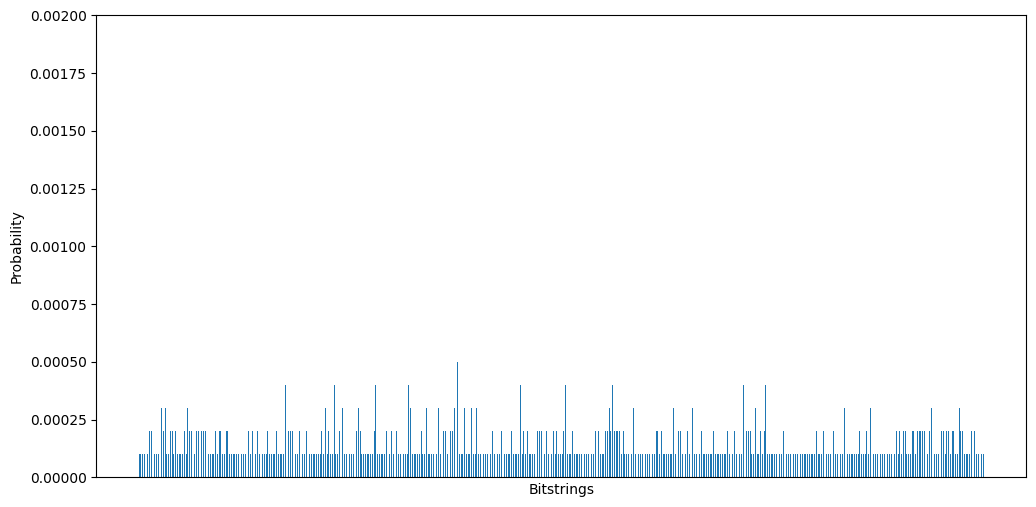

In [226]:
plot_histogram(rr5_14_sam4[0], keep_top=None, y_lim=0.002)